# ĐỒ ÁN DATA WAREHOUSE — DỰ ĐOÁN RỦI RO GIAO HÀNG TRỄ
## Từ kho dữ liệu BigQuery (Bronze → Silver → Gold) đến mô hình Machine Learning

**Đề tài:** Xây dựng kho dữ liệu hỗ trợ phân tích hiệu quả giao hàng và kinh doanh trong chuỗi cung ứng (bộ dữ liệu DataCo Supply Chain).

**Notebook này thực hiện:**

| Phần | Nội dung |
|---|---|
| 1 | Thiết lập thư viện, cấu hình, liên kết Google Drive (thư mục ảnh `img_datawarehouse`) |
| 2 | Kết nối Google BigQuery (Google Cloud → Google Colab) |
| 3 | Đối soát 3 tầng Bronze – Silver – Gold (số dòng, số cột, khóa, toàn vẹn tham chiếu, chỉ tiêu KPI) |
| 4 | Nạp bảng phẳng `gold.wide_order_items` vào Colab |
| 5 | Làm sạch và kiểm tra chất lượng dữ liệu cho học máy |
| 6 | Phân tích khám phá dữ liệu (EDA) |
| 7 | Chọn đặc trưng (có kiểm soát rò rỉ dữ liệu – *data leakage*) |
| 8 | Chia tập Train / Validation / Test theo `order_id` |
| 9 | Sàng lọc đặc trưng bằng thống kê (chỉ trên tập Train) |
| 10 | Tiền xử lý dữ liệu bằng Pipeline |
| 11 | Mô hình cơ sở (baseline) |
| 12 | Huấn luyện 3 mô hình: **Logistic Regression, Random Forest, XGBoost** |
| 13 | Tinh chỉnh siêu tham số bằng Cross-Validation theo nhóm |
| 14 | Đánh giá trên tập Validation, chọn ngưỡng quyết định, chẩn đoán overfitting |
| 15 | Đánh giá cuối cùng trên tập Test (chỉ chạy một lần) |
| 16 | Diễn giải mô hình (hệ số, độ quan trọng, Permutation Importance, SHAP) |
| 17 | Phân tích lỗi theo nhóm và kiểm tra độ bền theo thời gian |
| 18 | Phân tích cải thiện (loại từng nhóm đặc trưng) và thí nghiệm đối chứng rò rỉ dữ liệu |
| 19 | Lưu mô hình, bảng kết quả, danh mục hình và (tùy chọn) ghi dự đoán về tầng Gold |

**Hướng dẫn chạy:** chọn *Runtime → Run all* (hoặc chạy từng cell theo thứ tự). Lần đầu chạy, Colab sẽ hỏi quyền truy cập Google Drive và tài khoản Google Cloud — hãy dùng đúng tài khoản đang sở hữu project `warehouse-512516`.

**Thời gian chạy ước tính:** 25–45 phút ở cấu hình `PROFILE = 'standard'` (phần lớn là bước tinh chỉnh siêu tham số). Có thể đổi sang `'quick'` để chạy thử nhanh.

---
# PHẦN 1. THIẾT LẬP MÔI TRƯỜNG
## 1.1. Cài đặt thư viện

Colab đã có sẵn `pandas`, `numpy`, `scikit-learn`, `matplotlib`, `seaborn`, `scipy`. Chỉ cần cài thêm `xgboost` (mô hình), `shap` (diễn giải mô hình) và `db-dtypes` (để đọc kiểu DATE/NUMERIC từ BigQuery vào pandas).

In [ ]:
!pip install -q xgboost shap db-dtypes

## 1.2. Nhập thư viện và cấu hình chung

Mọi thông số có thể thay đổi (tên project, tên bảng, hạt giống ngẫu nhiên, cấu hình tinh chỉnh) đều đặt tại một chỗ để dễ quản lý. `RANDOM_STATE` cố định giúp kết quả **tái lập được** — yêu cầu cơ bản của một thực nghiệm học máy.

In [ ]:
import os, sys, json, time, warnings, joblib, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import FuncFormatter
from IPython.display import display

import sklearn, xgboost
warnings.filterwarnings("ignore")

# ---------------- Cấu hình dự án ----------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROJECT_ID   = "warehouse-512516"
BRONZE_TABLE = f"{PROJECT_ID}.bronze.dataco_raw"
SILVER_TABLE = f"{PROJECT_ID}.silver.dataco_silver"
FACT_TABLE   = f"{PROJECT_ID}.gold.fact_order_item"
WIDE_TABLE   = f"{PROJECT_ID}.gold.wide_order_items"
DIM_TABLES   = {"dim_date": "date_key", "dim_customer": "customer_id", "dim_product": "product_card_id",
                "dim_geography": "geography_key", "dim_shipping": "shipping_key"}

# Số liệu kỳ vọng lấy từ báo cáo (Chương 1–3)
EXPECTED = {
    "so_dong": 180_519, "so_don_hang": 65_752,
    "cot_bronze": 53, "cot_silver": 43,
    "doanh_so_niem_yet": 36_784_735.01, "doanh_thu_thuc_te": 33_054_402.38,
    "loi_nhuan_rong": 3_966_902.97, "ty_le_tre_loai_huy": 57.29, "ty_le_tre_toan_bo": 54.83,
}

# Cấu trúc kỳ vọng của bảng phẳng gold.wide_order_items (Đoạn mã 3.15)
EXPECTED_WIDE_COLS = [
    "order_item_id", "order_id", "order_status", "payment_type",
    "order_date", "order_year", "order_quarter", "order_month", "shipping_date",
    "customer_id", "customer_segment", "customer_country", "customer_state", "customer_city", "customer_zipcode",
    "product_card_id", "product_name", "category_name", "department_name",
    "market", "order_region", "order_country", "order_state", "order_city",
    "shipping_mode", "delivery_status",
    "order_item_quantity", "sales", "order_item_discount", "order_item_total", "benefit_per_order",
    "order_item_discount_rate", "order_item_product_price", "order_item_profit_ratio",
    "actual_shipping_days", "scheduled_shipping_days", "shipping_delay_days", "late_delivery_risk",
    "is_shipping_canceled",
]

# Cấu hình tinh chỉnh siêu tham số:  'quick' (chạy thử) | 'standard' (khuyến nghị) | 'thorough' (kỹ nhất)
PROFILE = "standard"
PROFILES = {
    "quick":    {"cv_folds": 3, "n_iter": {"Logistic Regression": 3,  "Random Forest": 3,  "XGBoost": 6}},
    "standard": {"cv_folds": 3, "n_iter": {"Logistic Regression": 8,  "Random Forest": 6,  "XGBoost": 15}},
    "thorough": {"cv_folds": 5, "n_iter": {"Logistic Regression": 15, "Random Forest": 10, "XGBoost": 30}},
}
CFG = PROFILES[PROFILE]

# Có ghi kết quả dự đoán ngược về tầng Gold của BigQuery hay không (cần quyền ghi vào dataset gold)
WRITE_BACK_TO_BQ = False

print("Python      :", platform.python_version())
print("pandas      :", pd.__version__, "| numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__, "| xgboost:", xgboost.__version__)
major, minor = map(int, sklearn.__version__.split(".")[:2])
assert (major, minor) >= (1, 2), "Cần scikit-learn >= 1.2 (OneHotEncoder: sparse_output, min_frequency)."
print(f"Cấu hình tinh chỉnh: PROFILE='{PROFILE}' -> {CFG}")

Python      : 3.13.18
pandas      : 2.2.3 | numpy: 2.4.6
scikit-learn: 1.6.1 | xgboost: 3.4.1
Cấu hình tinh chỉnh: PROFILE='standard' -> {'cv_folds': 3, 'n_iter': {'Logistic Regression': 8, 'Random Forest': 6, 'XGBoost': 15}}


## 1.3. Liên kết Google Drive và tạo thư mục ảnh `img_datawarehouse`

**Tài khoản Google Drive:** khi Colab hiện cửa sổ cấp quyền, hãy chọn đúng tài khoản **phucllbk24406@st.uel.edu.vn**. Thư mục sẽ được tạo trong Drive của tài khoản bạn đăng nhập ở bước này.

Toàn bộ hình trong notebook được **tự động lưu** vào thư mục `MyDrive/img_datawarehouse` trên Google Drive (độ phân giải 200 dpi, nền trắng, đặt tên có số thứ tự). Mô hình và các bảng kết quả được lưu riêng tại `MyDrive/DataWarehouse_DoAn/artifacts`.

Mỗi hình đều được in kèm **chú thích tiếng Việt** (đánh số `Hình 4.n`) và ghi vào file `danh_muc_hinh.csv` để bạn đưa thẳng vào báo cáo. Nếu muốn đánh số theo chương khác, chỉ cần sửa biến `CHAPTER`.

In [ ]:
try:
    from google.colab import drive, auth
    IN_COLAB = True
except ImportError:           # chạy ngoài Colab (kiểm thử cục bộ)
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    DRIVE_ROOT = "/content/drive/MyDrive"
else:
    DRIVE_ROOT = os.path.abspath("./drive_local")

DRIVE_ACCOUNT_EXPECTED = "phucllbk24406@st.uel.edu.vn"   # tài khoản Drive dùng cho đồ án (chỉ để nhắc, Colab dùng tài khoản bạn đăng nhập)
print("Hãy chắc chắn đã đăng nhập bằng tài khoản:", DRIVE_ACCOUNT_EXPECTED)
IMG_DIR = os.path.join(DRIVE_ROOT, "img_datawarehouse")                 # thư mục ảnh theo yêu cầu
ART_DIR = os.path.join(DRIVE_ROOT, "DataWarehouse_DoAn", "artifacts")   # mô hình + bảng kết quả
os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(ART_DIR, exist_ok=True)
print("Thư mục ảnh   :", IMG_DIR)
print("Thư mục kết quả:", ART_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Hãy chắc chắn đã đăng nhập bằng tài khoản: phucllbk24406@st.uel.edu.vn
Thư mục ảnh   : /content/drive/MyDrive/img_datawarehouse
Thư mục kết quả: /content/drive/MyDrive/DataWarehouse_DoAn/artifacts


## 1.4. Thiết lập phong cách vẽ hình và hàm lưu hình

Hàm `save_fig()` thực hiện đồng thời bốn việc: lưu ảnh vào Drive, hiển thị ảnh, in chú thích và ghi nhật ký hình. Nhờ vậy **không có hình nào bị sót** khi tổng hợp vào báo cáo.

In [ ]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.family": "DejaVu Sans",
})
C_BLUE, C_RED, C_GREEN, C_ORANGE, C_GREY, C_PURPLE = "#2F6DB5", "#D1495B", "#2E9C6A", "#EDAE49", "#8D99AE", "#7B5EA7"
MODEL_COLORS = {"Logistic Regression": C_BLUE, "Random Forest": C_GREEN, "XGBoost": C_ORANGE}

CHAPTER = "4"       # số chương dùng để đánh số hình: Hình 4.1, 4.2, ...
FIG_LOG = []

def save_fig(fig, slug, caption):
    """Lưu hình vào IMG_DIR, hiển thị, in chú thích và ghi nhật ký."""
    n = len(FIG_LOG) + 1
    fname = f"{n:02d}_{slug}.png"
    path = os.path.join(IMG_DIR, fname)
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    FIG_LOG.append({"so_hinh": f"Hình {CHAPTER}.{n}", "file": fname, "chu_thich": caption})
    plt.show()
    print(f"Hình {CHAPTER}.{n}. {caption}")
    print(f"   → đã lưu: {path}\n")

def fmt_vn(x, d=0):
    """Định dạng số theo kiểu Việt Nam: 180.519 ; 36.784.735,01"""
    s = f"{x:,.{d}f}"
    return s.replace(",", "§").replace(".", ",").replace("§", ".")

def pct(x, d=2):
    return f"{x*100:.{d}f}%".replace(".", ",")

print("Đã thiết lập xong. Hình sẽ được lưu tại:", IMG_DIR)

Đã thiết lập xong. Hình sẽ được lưu tại: /content/drive/MyDrive/img_datawarehouse


---
# PHẦN 2. KẾT NỐI GOOGLE BIGQUERY (GOOGLE CLOUD → GOOGLE COLAB)

Nguồn dữ liệu của phần Machine Learning chính là **tầng Gold** của kho dữ liệu đã xây dựng (project `warehouse-512516`). Đây là điểm liên kết giữa phần Data Warehouse và phần Machine Learning: mô hình được huấn luyện trên dữ liệu **đã làm sạch, đã đối soát** thay vì file CSV gốc.

Hai bước thực hiện: (1) xác thực bằng tài khoản Google; (2) khởi tạo `bigquery.Client` rồi kiểm tra ba dataset `bronze`, `silver`, `gold`.

In [ ]:
from google.cloud import bigquery

if IN_COLAB:
    auth.authenticate_user()          # cửa sổ đăng nhập Google sẽ hiện ra: chọn tài khoản có quyền truy cập project warehouse-512516

client = bigquery.Client(project=PROJECT_ID)

def run_query(sql):
    """Chạy truy vấn BigQuery và trả về DataFrame."""
    return client.query(sql).to_dataframe()

print("Đã kết nối BigQuery. Project:", client.project)

Đã kết nối BigQuery. Project: warehouse-512516


In [ ]:
# Kiểm tra sự tồn tại và vị trí lưu trữ của ba dataset, liệt kê các bảng trong từng tầng
layer_tables = {}
for ds in ["bronze", "silver", "gold"]:
    d = client.get_dataset(f"{PROJECT_ID}.{ds}")
    tables = sorted(t.table_id for t in client.list_tables(d))
    layer_tables[ds] = tables
    print(f"[{ds:6s}] vị trí={d.location} | {len(tables)} bảng")
    for t in tables:
        print("          -", t)

required_gold = {"fact_order_item", "wide_order_items", *DIM_TABLES.keys()}
missing = required_gold - set(layer_tables["gold"])
assert not missing, f"Thiếu bảng ở tầng Gold: {missing}"
assert "dataco_silver" in layer_tables["silver"], "Thiếu silver.dataco_silver"
assert "dataco_raw" in layer_tables["bronze"], "Thiếu bronze.dataco_raw"
print("\n✔ Đủ các bảng cần thiết ở cả ba tầng.")

[bronze] vị trí=US | 1 bảng
          - dataco_raw
[silver] vị trí=US | 3 bảng
          - dataco_silver
          - fact_order_item
          - wide_order_items
[gold  ] vị trí=US | 8 bảng
          - dim_customer
          - dim_date
          - dim_geography
          - dim_product
          - dim_shipping
          - fact_order_item
          - ml_late_delivery_predictions
          - wide_order_items

✔ Đủ các bảng cần thiết ở cả ba tầng.


---
# PHẦN 3. ĐỐI SOÁT BA TẦNG BRONZE – SILVER – GOLD

Mục tiêu: chứng minh rằng dữ liệu **không bị mất, không bị nhân đôi** khi đi qua các tầng, và các chỉ tiêu trên Gold **khớp với số liệu đã công bố** ở Chương 2 và Chương 3. Việc đối soát được thực hiện ở năm mức:

1. Số dòng và số cột của từng tầng.
2. Tính duy nhất của khóa (`order_item_id`) và số đơn hàng.
3. Toàn vẹn tham chiếu giữa bảng sự kiện và các bảng chiều (không có khóa "mồ côi"; bảng chiều không trùng khóa).
4. Đối chiếu **từng dòng** giữa Silver và bảng phẳng Gold (so sánh giá trị các cột chính theo `order_item_id`).
5. Đối chiếu các chỉ tiêu KPI với Bảng 3.8 của báo cáo.

Kết quả mỗi kiểm tra được ghi vào bảng `checks` với trạng thái **ĐẠT / KHÔNG ĐẠT**.

In [ ]:
checks = []
def add_check(name, actual, expected, tol=0.0, note=""):
    ok = abs(float(actual) - float(expected)) <= tol
    checks.append({"Hạng mục": name, "Thực tế": actual, "Kỳ vọng": expected,
                   "Kết quả": "ĐẠT" if ok else "KHÔNG ĐẠT", "Ghi chú": note})
    return ok

# ---- Mức 1: số dòng và số cột ----
rows_df = run_query(f"""
SELECT 'Bronze' AS tang, 'bronze.dataco_raw'        AS bang, COUNT(*) AS so_dong FROM `{BRONZE_TABLE}`
UNION ALL SELECT 'Silver', 'silver.dataco_silver',   COUNT(*) FROM `{SILVER_TABLE}`
UNION ALL SELECT 'Gold',   'gold.fact_order_item',   COUNT(*) FROM `{FACT_TABLE}`
UNION ALL SELECT 'Gold',   'gold.wide_order_items',  COUNT(*) FROM `{WIDE_TABLE}`
""")
cols_df = run_query(f"""
SELECT 'bronze.dataco_raw' AS bang, COUNT(*) AS so_cot
FROM `{PROJECT_ID}.bronze.INFORMATION_SCHEMA.COLUMNS` WHERE table_name = 'dataco_raw'
UNION ALL SELECT 'silver.dataco_silver', COUNT(*)
FROM `{PROJECT_ID}.silver.INFORMATION_SCHEMA.COLUMNS` WHERE table_name = 'dataco_silver'
UNION ALL SELECT 'gold.wide_order_items', COUNT(*)
FROM `{PROJECT_ID}.gold.INFORMATION_SCHEMA.COLUMNS` WHERE table_name = 'wide_order_items'
""")
layer_df = rows_df.merge(cols_df, on="bang", how="left")
layer_df["so_dong"] = layer_df["so_dong"].astype(int)
display(layer_df)

for _, r in layer_df.iterrows():
    add_check(f"Số dòng {r['bang']}", r["so_dong"], EXPECTED["so_dong"])
cols = dict(zip(cols_df["bang"], cols_df["so_cot"].astype(int)))
add_check("Số cột bronze.dataco_raw",    cols["bronze.dataco_raw"],        EXPECTED["cot_bronze"])
add_check("Số cột silver.dataco_silver", cols["silver.dataco_silver"],     EXPECTED["cot_silver"], note="42 cột làm sạch + shipping_delay_days")
add_check("Số cột gold.wide_order_items", cols["gold.wide_order_items"],   len(EXPECTED_WIDE_COLS))

,tang,bang,so_dong,so_cot
0,Bronze,bronze.dataco_raw,180519,53
1,Silver,silver.dataco_silver,180519,43
2,Gold,gold.fact_order_item,180519,<NA>
3,Gold,gold.wide_order_items,180519,39


True

In [ ]:
# ---- Mức 2: khóa duy nhất, số đơn hàng ----
key_df = run_query(f"""
SELECT
  (SELECT COUNT(*) - COUNT(DISTINCT order_item_id) FROM `{SILVER_TABLE}`) AS trung_khoa_silver,
  (SELECT COUNT(*) - COUNT(DISTINCT order_item_id) FROM `{FACT_TABLE}`)   AS trung_khoa_fact,
  (SELECT COUNT(*) - COUNT(DISTINCT order_item_id) FROM `{WIDE_TABLE}`)   AS trung_khoa_wide,
  (SELECT COUNTIF(order_item_id IS NULL)           FROM `{WIDE_TABLE}`)   AS khoa_null_wide,
  (SELECT COUNT(DISTINCT order_id)                 FROM `{SILVER_TABLE}`) AS don_silver,
  (SELECT COUNT(DISTINCT order_id)                 FROM `{WIDE_TABLE}`)   AS don_wide
""").iloc[0]
display(key_df.to_frame("giá trị"))

add_check("Trùng order_item_id (Silver)", key_df.trung_khoa_silver, 0)
add_check("Trùng order_item_id (Fact)",   key_df.trung_khoa_fact, 0)
add_check("Trùng order_item_id (Wide)",   key_df.trung_khoa_wide, 0)
add_check("order_item_id NULL (Wide)",    key_df.khoa_null_wide, 0)
add_check("Số đơn hàng (Silver)", key_df.don_silver, EXPECTED["so_don_hang"])
add_check("Số đơn hàng (Wide)",   key_df.don_wide,   EXPECTED["so_don_hang"])

# ---- Mức 3a: khóa mồ côi giữa Fact và các Dim (LEFT JOIN không tìm thấy bản ghi chiều) ----
orphan_df = run_query(f"""
SELECT
  COUNTIF(f.order_date_key    IS NOT NULL AND od.date_key        IS NULL) AS mo_coi_ngay_dat,
  COUNTIF(f.shipping_date_key IS NOT NULL AND sd.date_key        IS NULL) AS mo_coi_ngay_giao,
  COUNTIF(f.customer_id       IS NOT NULL AND c.customer_id      IS NULL) AS mo_coi_khach_hang,
  COUNTIF(f.product_card_id   IS NOT NULL AND p.product_card_id  IS NULL) AS mo_coi_san_pham,
  COUNTIF(f.geography_key     IS NOT NULL AND g.geography_key    IS NULL) AS mo_coi_dia_ly,
  COUNTIF(f.shipping_key      IS NOT NULL AND s.shipping_key     IS NULL) AS mo_coi_van_chuyen
FROM `{FACT_TABLE}` f
LEFT JOIN `{PROJECT_ID}.gold.dim_date`      od ON f.order_date_key    = od.date_key
LEFT JOIN `{PROJECT_ID}.gold.dim_date`      sd ON f.shipping_date_key = sd.date_key
LEFT JOIN `{PROJECT_ID}.gold.dim_customer`  c  ON f.customer_id       = c.customer_id
LEFT JOIN `{PROJECT_ID}.gold.dim_product`   p  ON f.product_card_id   = p.product_card_id
LEFT JOIN `{PROJECT_ID}.gold.dim_geography` g  ON f.geography_key     = g.geography_key
LEFT JOIN `{PROJECT_ID}.gold.dim_shipping`  s  ON f.shipping_key      = s.shipping_key
""").iloc[0]
display(orphan_df.to_frame("số dòng mồ côi"))
for k, v in orphan_df.items():
    add_check(f"Khóa mồ côi: {k}", v, 0)

# ---- Mức 3b: bảng chiều phải duy nhất theo khóa (nếu trùng, phép LEFT JOIN sẽ nhân dòng) ----
dim_sql = " UNION ALL ".join(
    f"SELECT '{t}' AS bang, '{k}' AS khoa, COUNT(*) AS so_dong, COUNT(DISTINCT {k}) AS so_khoa_duy_nhat "
    f"FROM `{PROJECT_ID}.gold.{t}`" for t, k in DIM_TABLES.items())
dim_df = run_query(dim_sql)
dim_df["trung_khoa"] = dim_df["so_dong"] - dim_df["so_khoa_duy_nhat"]
display(dim_df)
for _, r in dim_df.iterrows():
    add_check(f"Trùng khóa {r['bang']}.{r['khoa']}", r["trung_khoa"], 0, note="Phải = 0 để phép nối không nhân dòng")

,giá trị
trung_khoa_silver,0
trung_khoa_fact,0
trung_khoa_wide,0
khoa_null_wide,0
don_silver,65752
don_wide,65752


,số dòng mồ côi
mo_coi_ngay_dat,0
mo_coi_ngay_giao,0
mo_coi_khach_hang,0
mo_coi_san_pham,0
mo_coi_dia_ly,0
mo_coi_van_chuyen,0


,bang,khoa,so_dong,so_khoa_duy_nhat,trung_khoa
0,dim_date,date_key,1133,1133,0
1,dim_customer,customer_id,20652,20652,0
2,dim_product,product_card_id,118,118,0
3,dim_geography,geography_key,3772,3772,0
4,dim_shipping,shipping_key,12,12,0


In [ ]:
# ---- Mức 4: đối chiếu TỪNG DÒNG giữa Silver và bảng phẳng Gold (nối theo order_item_id) ----
rowlevel = run_query(f"""
SELECT
  COUNT(*) AS so_dong_noi_duoc,
  COUNTIF(s.sales                   IS DISTINCT FROM w.sales)                   AS lech_sales,
  COUNTIF(s.order_item_total        IS DISTINCT FROM w.order_item_total)        AS lech_item_total,
  COUNTIF(s.benefit_per_order       IS DISTINCT FROM w.benefit_per_order)       AS lech_loi_nhuan,
  COUNTIF(s.order_item_quantity     IS DISTINCT FROM w.order_item_quantity)     AS lech_so_luong,
  COUNTIF(s.actual_shipping_days    IS DISTINCT FROM w.actual_shipping_days)    AS lech_ngay_thuc_te,
  COUNTIF(s.scheduled_shipping_days IS DISTINCT FROM w.scheduled_shipping_days) AS lech_ngay_du_kien,
  COUNTIF(s.late_delivery_risk      IS DISTINCT FROM w.late_delivery_risk)      AS lech_nhan_tre,
  COUNTIF(s.delivery_status         IS DISTINCT FROM w.delivery_status)         AS lech_trang_thai_giao,
  COUNTIF(s.shipping_mode           IS DISTINCT FROM w.shipping_mode)           AS lech_phuong_thuc,
  COUNTIF(s.market                  IS DISTINCT FROM w.market)                  AS lech_thi_truong,
  COUNTIF(s.order_region            IS DISTINCT FROM w.order_region)            AS lech_khu_vuc,
  COUNTIF(s.customer_segment        IS DISTINCT FROM w.customer_segment)        AS lech_phan_khuc,
  COUNTIF(s.category_name           IS DISTINCT FROM w.category_name)           AS lech_danh_muc,
  COUNTIF(DATE(s.order_date)        IS DISTINCT FROM w.order_date)              AS lech_ngay_dat
FROM `{SILVER_TABLE}` s
JOIN `{WIDE_TABLE}`   w USING (order_item_id)
""").iloc[0]
display(rowlevel.to_frame("giá trị"))

add_check("Số dòng nối được Silver ↔ Wide", rowlevel["so_dong_noi_duoc"], EXPECTED["so_dong"])
for k, v in rowlevel.items():
    if k.startswith("lech_"):
        add_check(f"Dòng lệch Silver↔Wide: {k[5:]}", v, 0)

,giá trị
so_dong_noi_duoc,180519
lech_sales,0
lech_item_total,0
lech_loi_nhuan,0
lech_so_luong,0
lech_ngay_thuc_te,0
lech_ngay_du_kien,0
lech_nhan_tre,0
lech_trang_thai_giao,0
lech_phuong_thuc,0


In [ ]:
# ---- Mức 5: đối chiếu KPI trên bảng phẳng với Bảng 3.8 của báo cáo ----
kpi = run_query(f"""
SELECT
  COUNT(DISTINCT order_id)                                   AS so_don_hang,
  ROUND(SUM(sales), 2)                                       AS doanh_so_niem_yet,
  ROUND(SUM(order_item_total), 2)                            AS doanh_thu_thuc_te,
  ROUND(SUM(benefit_per_order), 2)                           AS loi_nhuan_rong,
  ROUND(SAFE_DIVIDE(COUNTIF(late_delivery_risk = 1 AND NOT is_shipping_canceled),
                    COUNTIF(NOT is_shipping_canceled)) * 100, 2) AS ty_le_tre_loai_huy,
  ROUND(SAFE_DIVIDE(COUNTIF(late_delivery_risk = 1), COUNT(*)) * 100, 2) AS ty_le_tre_toan_bo
FROM `{WIDE_TABLE}`
""").iloc[0].astype(float)

kpi_tbl = pd.DataFrame({
    "Chỉ tiêu": ["Số đơn hàng", "Doanh số niêm yết (USD)", "Doanh thu thực tế (USD)", "Lợi nhuận ròng (USD)",
                 "Tỷ lệ giao trễ, loại đơn hủy (%)", "Tỷ lệ giao trễ, toàn bộ dòng (%)"],
    "Trên bảng phẳng Gold": [kpi.so_don_hang, kpi.doanh_so_niem_yet, kpi.doanh_thu_thuc_te, kpi.loi_nhuan_rong,
                             kpi.ty_le_tre_loai_huy, kpi.ty_le_tre_toan_bo],
    "Giá trị trong báo cáo": [EXPECTED["so_don_hang"], EXPECTED["doanh_so_niem_yet"], EXPECTED["doanh_thu_thuc_te"],
                              EXPECTED["loi_nhuan_rong"], EXPECTED["ty_le_tre_loai_huy"], EXPECTED["ty_le_tre_toan_bo"]],
})
kpi_tbl["Chênh lệch"] = kpi_tbl["Trên bảng phẳng Gold"] - kpi_tbl["Giá trị trong báo cáo"]
display(kpi_tbl.style.format({"Trên bảng phẳng Gold": "{:,.2f}", "Giá trị trong báo cáo": "{:,.2f}", "Chênh lệch": "{:,.2f}"}))

for _, r in kpi_tbl.iterrows():
    add_check(f"KPI: {r['Chỉ tiêu']}", r["Trên bảng phẳng Gold"], r["Giá trị trong báo cáo"], tol=0.01)

# ---- Tổng hợp ----
checks_df = pd.DataFrame(checks)
n_pass = int((checks_df["Kết quả"] == "ĐẠT").sum())
print(f"\nTỔNG KẾT ĐỐI SOÁT: {n_pass}/{len(checks_df)} hạng mục ĐẠT")
if n_pass < len(checks_df):
    print("⚠ Các hạng mục KHÔNG ĐẠT cần kiểm tra lại model dbt tương ứng:")
    display(checks_df[checks_df["Kết quả"] != "ĐẠT"])
else:
    print("✔ Dữ liệu nhất quán xuyên suốt ba tầng, có thể dùng để huấn luyện mô hình.")
checks_df.to_csv(os.path.join(ART_DIR, "doi_soat_3_tang.csv"), index=False, encoding="utf-8-sig")

,Chỉ tiêu,Trên bảng phẳng Gold,Giá trị trong báo cáo,Chênh lệch
0,Số đơn hàng,"65,752.00","65,752.00",0.00
1,Doanh số niêm yết (USD),"36,784,735.01","36,784,735.01",0.00
2,Doanh thu thực tế (USD),"33,054,402.38","33,054,402.38",0.00
3,Lợi nhuận ròng (USD),"3,966,902.97","3,966,902.97",0.00
4,"Tỷ lệ giao trễ, loại đơn hủy (%)",57.29,57.29,0.00
5,"Tỷ lệ giao trễ, toàn bộ dòng (%)",54.83,54.83,0.00



TỔNG KẾT ĐỐI SOÁT: 45/45 hạng mục ĐẠT
✔ Dữ liệu nhất quán xuyên suốt ba tầng, có thể dùng để huấn luyện mô hình.


### Trực quan hóa kết quả đối soát

Hình dưới biểu diễn **dòng chảy dữ liệu** qua các tầng, kèm số dòng, số cột thực tế đọc từ BigQuery và trạng thái đối soát. Hình tiếp theo so sánh số dòng giữa các bảng để thấy rõ không có bản ghi nào bị mất hoặc nhân đôi.

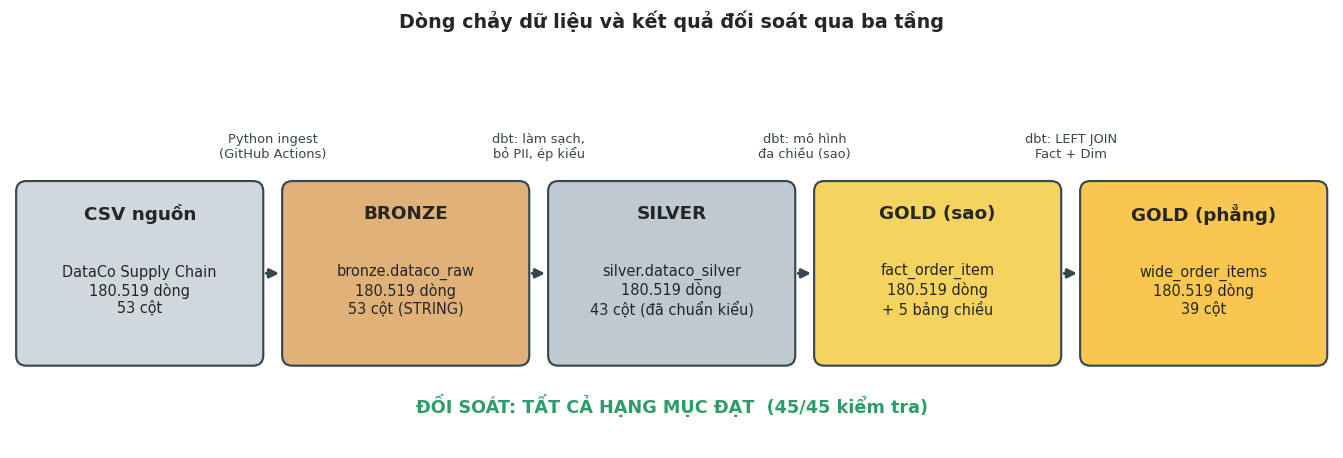

Hình 4.1. Sơ đồ dòng chảy dữ liệu từ file CSV nguồn qua ba tầng Bronze – Silver – Gold trên Google BigQuery, kèm số dòng, số cột thực tế và trạng thái đối soát.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/01_dong_chay_du_lieu_3_tang.png



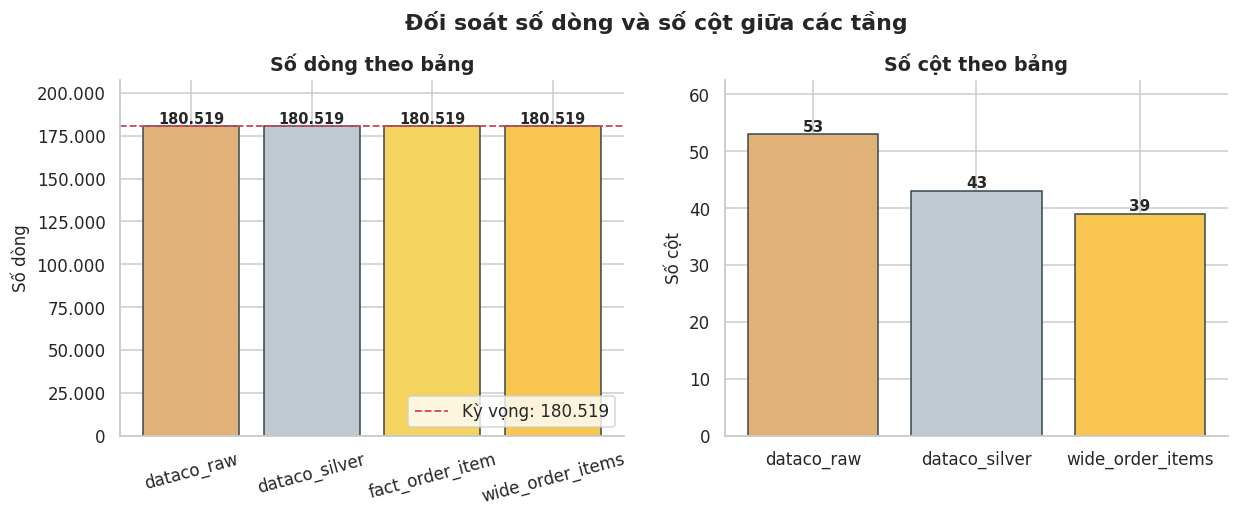

Hình 4.2. Đối soát số dòng (trái) và số cột (phải) giữa các bảng. Số dòng giữ nguyên 180.519 ở mọi tầng; số cột giảm từ 53 (Bronze) xuống 43 (Silver) do loại thông tin nhận dạng cá nhân và thuộc tính dư thừa.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/02_doi_soat_so_dong_so_cot.png



In [ ]:
# ---------- Hình: sơ đồ dòng chảy dữ liệu ----------
get_rows = lambda t: int(layer_df.loc[layer_df.bang == t, "so_dong"].iloc[0])
get_cols = lambda t: int(layer_df.loc[layer_df.bang == t, "so_cot"].iloc[0])
all_ok = (checks_df["Kết quả"] == "ĐẠT").all()

fig, ax = plt.subplots(figsize=(15.5, 4.8))
ax.set_xlim(0, 15.4); ax.set_ylim(0, 4.8); ax.axis("off")
nodes = [
    (0.1,  "CSV nguồn",   f"DataCo Supply Chain\n{fmt_vn(EXPECTED['so_dong'])} dòng\n53 cột", "#CFD8DC"),
    (3.2,  "BRONZE",      f"bronze.dataco_raw\n{fmt_vn(get_rows('bronze.dataco_raw'))} dòng\n{get_cols('bronze.dataco_raw')} cột (STRING)", "#E0B27A"),
    (6.3,  "SILVER",      f"silver.dataco_silver\n{fmt_vn(get_rows('silver.dataco_silver'))} dòng\n{get_cols('silver.dataco_silver')} cột (đã chuẩn kiểu)", "#BFC9D1"),
    (9.4,  "GOLD (sao)",  f"fact_order_item\n{fmt_vn(get_rows('gold.fact_order_item'))} dòng\n+ 5 bảng chiều", "#F4D35E"),
    (12.5, "GOLD (phẳng)", f"wide_order_items\n{fmt_vn(get_rows('gold.wide_order_items'))} dòng\n{get_cols('gold.wide_order_items')} cột", "#F9C74F"),
]
w, h, y0 = 2.8, 2.1, 1.0
for x, title, body, color in nodes:
    ax.add_patch(FancyBboxPatch((x, y0), w, h, boxstyle="round,pad=0.04,rounding_size=0.12",
                                fc=color, ec="#37474F", lw=1.4))
    ax.text(x + w/2, y0 + h - 0.35, title, ha="center", va="center", fontsize=12, fontweight="bold")
    ax.text(x + w/2, y0 + h/2 - 0.2, body, ha="center", va="center", fontsize=9.5)
labels = ["Python ingest\n(GitHub Actions)", "dbt: làm sạch,\nbỏ PII, ép kiểu", "dbt: mô hình\nđa chiều (sao)", "dbt: LEFT JOIN\nFact + Dim"]
for i in range(4):
    x_start, x_end = nodes[i][0] + w + 0.04, nodes[i+1][0] - 0.04
    ax.annotate("", xy=(x_end, y0 + h/2), xytext=(x_start, y0 + h/2),
                arrowprops=dict(arrowstyle="-|>", lw=2, color="#37474F"))
    ax.text((x_start + x_end)/2, y0 + h + 0.45, labels[i], ha="center", va="center", fontsize=8.5, color="#37474F")
status = "ĐỐI SOÁT: TẤT CẢ HẠNG MỤC ĐẠT" if all_ok else "ĐỐI SOÁT: CÒN HẠNG MỤC KHÔNG ĐẠT"
ax.text(7.7, 0.4, f"{status}  ({n_pass}/{len(checks_df)} kiểm tra)", ha="center", fontsize=11.5, fontweight="bold",
        color=C_GREEN if all_ok else C_RED)
ax.set_title("Dòng chảy dữ liệu và kết quả đối soát qua ba tầng", pad=8)
save_fig(fig, "dong_chay_du_lieu_3_tang",
         "Sơ đồ dòng chảy dữ liệu từ file CSV nguồn qua ba tầng Bronze – Silver – Gold trên Google BigQuery, "
         "kèm số dòng, số cột thực tế và trạng thái đối soát.")

# ---------- Hình: số dòng và số cột theo bảng ----------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
order = ["bronze.dataco_raw", "silver.dataco_silver", "gold.fact_order_item", "gold.wide_order_items"]
vals = [get_rows(t) for t in order]
bars = axes[0].bar([t.split(".")[1] for t in order], vals, color=["#E0B27A", "#BFC9D1", "#F4D35E", "#F9C74F"], edgecolor="#37474F")
for b, v in zip(bars, vals):
    axes[0].text(b.get_x() + b.get_width()/2, v, fmt_vn(v), ha="center", va="bottom", fontsize=9.5, fontweight="bold")
axes[0].axhline(EXPECTED["so_dong"], ls="--", c=C_RED, lw=1.2, label=f"Kỳ vọng: {fmt_vn(EXPECTED['so_dong'])}")
axes[0].set_ylim(0, max(vals) * 1.15); axes[0].set_ylabel("Số dòng"); axes[0].set_title("Số dòng theo bảng")
axes[0].tick_params(axis="x", rotation=15); axes[0].legend(loc="lower right")
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda x, p: fmt_vn(x)))

cols_order = ["bronze.dataco_raw", "silver.dataco_silver", "gold.wide_order_items"]
cvals = [get_cols(t) for t in cols_order]
bars = axes[1].bar([t.split(".")[1] for t in cols_order], cvals, color=["#E0B27A", "#BFC9D1", "#F9C74F"], edgecolor="#37474F")
for b, v in zip(bars, cvals):
    axes[1].text(b.get_x() + b.get_width()/2, v, str(v), ha="center", va="bottom", fontsize=10, fontweight="bold")
axes[1].set_ylim(0, max(cvals) * 1.18); axes[1].set_ylabel("Số cột"); axes[1].set_title("Số cột theo bảng")
fig.suptitle("Đối soát số dòng và số cột giữa các tầng", fontweight="bold", y=1.03)
save_fig(fig, "doi_soat_so_dong_so_cot",
         "Đối soát số dòng (trái) và số cột (phải) giữa các bảng. Số dòng giữ nguyên 180.519 ở mọi tầng; "
         "số cột giảm từ 53 (Bronze) xuống 43 (Silver) do loại thông tin nhận dạng cá nhân và thuộc tính dư thừa.")

---
# PHẦN 4. NẠP BẢNG PHẲNG `gold.wide_order_items` VÀO COLAB

Bảng phẳng đã nối sẵn bảng sự kiện với toàn bộ bảng chiều nên mỗi dòng mang đủ thuộc tính để huấn luyện mô hình. Sau khi nạp, cần **ép kiểu** vì thư viện BigQuery trả về:

- `NUMERIC` dưới dạng đối tượng `Decimal` (không tính toán thống kê được) → chuyển sang `float`;
- `DATE` dưới dạng kiểu `dbdate` → chuyển sang `datetime64`;
- `BOOL` có thể chứa giá trị thiếu → chuyển sang `bool` thuần.

Cuối cùng kiểm tra cấu trúc cột có khớp với thiết kế (Đoạn mã 3.15) hay không, để phát hiện sớm khi ai đó đổi model dbt.

In [ ]:
t0 = time.time()
df_raw = run_query(f"SELECT * FROM `{WIDE_TABLE}`")
print(f"Đã nạp {len(df_raw):,} dòng × {df_raw.shape[1]} cột trong {time.time()-t0:.1f}s")

# Lưu bản sao (parquet) vào Drive để nếu Colab ngắt kết nối có thể nạp lại nhanh mà không cần truy vấn
try:
    df_raw.to_parquet(os.path.join(ART_DIR, "wide_order_items_snapshot.parquet"), index=False)
    print("Đã lưu bản sao parquet vào Drive.")
except Exception as e:
    print("Không lưu được parquet (bỏ qua):", e)

Đã nạp 180,519 dòng × 39 cột trong 5.9s
Đã lưu bản sao parquet vào Drive.


In [ ]:
# Nếu Colab bị ngắt kết nối, bỏ comment 2 dòng dưới để nạp lại từ bản sao thay vì truy vấn BigQuery:
# df_raw = pd.read_parquet(os.path.join(ART_DIR, "wide_order_items_snapshot.parquet"))

df = df_raw.copy()

FLOAT_COLS = ["sales", "order_item_discount", "order_item_total", "benefit_per_order",
              "order_item_discount_rate", "order_item_product_price", "order_item_profit_ratio"]
INT_COLS   = ["order_item_id", "order_id", "customer_id", "product_card_id", "order_item_quantity",
              "actual_shipping_days", "scheduled_shipping_days", "shipping_delay_days", "late_delivery_risk"]
for c in FLOAT_COLS:
    df[c] = pd.to_numeric(df[c], errors="coerce").astype("float64")
for c in INT_COLS:
    df[c] = pd.to_numeric(df[c], errors="coerce")           # giữ NaN nếu có -> kiểm tra ở phần làm sạch
df["order_date"]    = pd.to_datetime(df["order_date"])
df["shipping_date"] = pd.to_datetime(df["shipping_date"])
df["is_shipping_canceled"] = df["is_shipping_canceled"].fillna(False).astype(bool)

# Kiểm tra cấu trúc cột
missing_cols = [c for c in EXPECTED_WIDE_COLS if c not in df.columns]
extra_cols   = [c for c in df.columns if c not in EXPECTED_WIDE_COLS]
assert not missing_cols, f"Bảng phẳng thiếu cột: {missing_cols}"
print("Cột phát sinh ngoài thiết kế:", extra_cols if extra_cols else "không có")
print(f"\nKích thước: {df.shape[0]:,} dòng × {df.shape[1]} cột | số đơn hàng: {df['order_id'].nunique():,}")
print(f"Khoảng thời gian đặt hàng: {df['order_date'].min().date()} → {df['order_date'].max().date()}")
display(df.dtypes.to_frame("kiểu dữ liệu").T)
display(df.head(3).T)

Cột phát sinh ngoài thiết kế: không có

Kích thước: 180,519 dòng × 39 cột | số đơn hàng: 65,752
Khoảng thời gian đặt hàng: 2015-01-01 → 2018-01-31


,order_item_id,order_id,order_status,payment_type,order_date,order_year,order_quarter,order_month,shipping_date,customer_id,...,order_item_total,benefit_per_order,order_item_discount_rate,order_item_product_price,order_item_profit_ratio,actual_shipping_days,scheduled_shipping_days,shipping_delay_days,late_delivery_risk,is_shipping_canceled
kiểu dữ liệu,Int64,Int64,object,object,datetime64[ns],Int64,Int64,Int64,datetime64[ns],Int64,...,float64,float64,float64,float64,float64,Int64,Int64,Int64,Int64,bool


,0,1,2
order_item_id,159460,163950,155972
order_id,63796,65604,62396
order_status,COMPLETE,CLOSED,COMPLETE
payment_type,DEBIT,CASH,DEBIT
order_date,2017-07-20 00:00:00,2017-08-15 00:00:00,2017-06-29 00:00:00
order_year,2017,2017,2017
order_quarter,3,3,2
order_month,7,8,6
shipping_date,2017-07-22 00:00:00,2017-08-20 00:00:00,2017-06-30 00:00:00
customer_id,6746,8166,2149


---
# PHẦN 5. LÀM SẠCH VÀ KIỂM TRA CHẤT LƯỢNG DỮ LIỆU CHO HỌC MÁY

Tầng Silver đã làm sạch ở mức **kho dữ liệu** (ép kiểu, chuẩn hóa chuỗi, loại PII). Trước khi huấn luyện, cần thêm một vòng kiểm tra ở mức **học máy**, vì mô hình nhạy cảm với những lỗi mà báo cáo BI có thể bỏ qua: giá trị thiếu, dòng trùng, giá trị vô lý, nhãn mâu thuẫn, ngoại lai.

| Bước | Nội dung | Lý do |
|---|---|---|
| 5.1 | Giá trị thiếu | Hầu hết thuật toán (Logistic, Random Forest của sklearn) không chấp nhận `NaN` |
| 5.2 | Dòng trùng | Dòng trùng làm mô hình "học thuộc" và làm điểm kiểm tra cao giả |
| 5.3 | Ràng buộc nghiệp vụ / khoảng giá trị | Phát hiện dữ liệu vô lý (số lượng âm, ngày giao trước ngày đặt, ...) |
| 5.4 | Tính nhất quán của **nhãn** | Nhãn sai thì mô hình học sai, không có kỹ thuật nào bù được |
| 5.5 | Ngoại lai | Quyết định giữ hay xử lý, có ghi lý do |
| 5.6 | Xử lý đơn hủy vận chuyển | "Giao trễ" không có nghĩa với đơn bị hủy |

In [ ]:
# ---------- 5.1 Giá trị thiếu ----------
miss = pd.DataFrame({"so_thieu": df.isna().sum(), "ty_le_%": df.isna().mean() * 100})
miss_nz = miss[miss.so_thieu > 0].sort_values("so_thieu", ascending=False)
print(f"Số cột có giá trị thiếu: {len(miss_nz)} / {df.shape[1]}")
display(miss_nz if len(miss_nz) else pd.DataFrame({"kết luận": ["Không có giá trị thiếu trong bảng phẳng"]}))

# ---------- 5.2 Dòng trùng ----------
n_dup_full = int(df.duplicated().sum())
n_dup_key  = int(df.duplicated("order_item_id").sum())
print(f"\nDòng trùng hoàn toàn: {n_dup_full} | Trùng khóa order_item_id: {n_dup_key}")

# ---------- 5.3 Ràng buộc nghiệp vụ ----------
nc = ~df["is_shipping_canceled"]
rules = {
    "order_item_id duy nhất":                       ~df.duplicated("order_item_id", keep=False),
    "Số lượng ≥ 1":                                 df["order_item_quantity"] >= 1,
    "Tỷ lệ chiết khấu trong [0, 1]":                df["order_item_discount_rate"].between(0, 1),
    "Giá sản phẩm > 0":                             df["order_item_product_price"] > 0,
    "Doanh số (sales) ≥ 0":                         df["sales"] >= 0,
    "Doanh thu thực tế (order_item_total) ≥ 0":     df["order_item_total"] >= 0,
    "Số ngày giao thực tế trong [0, 30]":           df["actual_shipping_days"].between(0, 30),
    "Số ngày giao dự kiến trong [0, 30]":           df["scheduled_shipping_days"].between(0, 30),
    "Ngày giao ≥ ngày đặt":                         df["shipping_date"].isna() | (df["shipping_date"] >= df["order_date"]),
    "Nhãn late_delivery_risk ∈ {0, 1}":             df["late_delivery_risk"].isin([0, 1]),
    "shipping_delay_days = thực tế − dự kiến":      df["shipping_delay_days"] == (df["actual_shipping_days"] - df["scheduled_shipping_days"]),
}
rule_tbl = pd.DataFrame({"Quy tắc": list(rules.keys()),
                         "Số dòng vi phạm": [int((~s).sum()) for s in rules.values()],
                         "Tỷ lệ đạt (%)": [float(s.mean() * 100) for s in rules.values()]})
display(rule_tbl.style.format({"Tỷ lệ đạt (%)": "{:.3f}"}))

# ---------- 5.4 Nhãn có nhất quán với số ngày giao không? ----------
# Định nghĩa nghiệp vụ: trễ  <=>  số ngày thực tế > số ngày dự kiến (áp dụng cho đơn không bị hủy)
label_from_days = (df.loc[nc, "actual_shipping_days"] > df.loc[nc, "scheduled_shipping_days"]).astype(int)
agree = float((label_from_days == df.loc[nc, "late_delivery_risk"]).mean() * 100)
print(f"\nNhãn late_delivery_risk khớp định nghĩa 'thực tế > dự kiến' ở {agree:.3f}% số dòng không bị hủy.")
print("→ Nhãn được SUY RA từ số ngày thực tế: đây chính là căn cứ để loại các biến sau giao hàng khỏi đặc trưng (Phần 7).")
print("\nPhân bố Delivery Status theo nhãn (kiểm tra mâu thuẫn):")
display(pd.crosstab(df["delivery_status"], df["late_delivery_risk"], margins=True))

Số cột có giá trị thiếu: 1 / 39


,so_thieu,ty_le_%
customer_zipcode,3,0.001662



Dòng trùng hoàn toàn: 0 | Trùng khóa order_item_id: 0


,Quy tắc,Số dòng vi phạm,Tỷ lệ đạt (%)
0,order_item_id duy nhất,0,100.000
1,Số lượng ≥ 1,0,100.000
2,"Tỷ lệ chiết khấu trong [0, 1]",0,100.000
3,Giá sản phẩm > 0,0,100.000
4,Doanh số (sales) ≥ 0,0,100.000
5,Doanh thu thực tế (order_item_total) ≥ 0,0,100.000
6,"Số ngày giao thực tế trong [0, 30]",0,100.000
7,"Số ngày giao dự kiến trong [0, 30]",0,100.000
8,Ngày giao ≥ ngày đặt,0,100.000
9,"Nhãn late_delivery_risk ∈ {0, 1}",0,100.000



Nhãn late_delivery_risk khớp định nghĩa 'thực tế > dự kiến' ở 100.000% số dòng không bị hủy.
→ Nhãn được SUY RA từ số ngày thực tế: đây chính là căn cứ để loại các biến sau giao hàng khỏi đặc trưng (Phần 7).

Phân bố Delivery Status theo nhãn (kiểm tra mâu thuẫn):


late_delivery_risk,0,1,All
delivery_status,,,
Advance shipping,41592,0,41592
Late delivery,0,98977,98977
Shipping canceled,7754,0,7754
Shipping on time,32196,0,32196
All,81542,98977,180519


In [ ]:
# ---------- 5.5 Ngoại lai (IQR) ----------
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((s < lo) | (s > hi)).sum()), lo, hi

out_rows = []
for c in ["order_item_total", "order_item_quantity", "order_item_discount_rate", "benefit_per_order", "order_item_product_price"]:
    n, lo, hi = iqr_outliers(df[c])
    out_rows.append({"Biến": c, "Số ngoại lai (IQR)": n, "Tỷ lệ (%)": n / len(df) * 100, "Ngưỡng dưới": lo, "Ngưỡng trên": hi,
                     "Min": df[c].min(), "Max": df[c].max()})
out_tbl = pd.DataFrame(out_rows)
display(out_tbl.style.format({"Tỷ lệ (%)": "{:.2f}", "Ngưỡng dưới": "{:,.2f}", "Ngưỡng trên": "{:,.2f}", "Min": "{:,.2f}", "Max": "{:,.2f}"}))
print("Quyết định: KHÔNG loại ngoại lai. Đây là đơn hàng giá trị lớn có thật (không phải lỗi nhập liệu, đã kiểm ở 5.3).")
print("Cách xử lý: (a) mô hình cây/boosting không nhạy với ngoại lai; (b) với Logistic Regression dùng log1p cho doanh thu + chuẩn hóa.")

# ---------- 5.6 Đơn hủy vận chuyển ----------
n_cancel = int(df["is_shipping_canceled"].sum())
df_model = df.loc[~df["is_shipping_canceled"]].copy().reset_index(drop=True)
print(f"\nĐơn hủy vận chuyển: {n_cancel:,} dòng ({n_cancel/len(df)*100:.2f}%) → loại khỏi tập huấn luyện.")
print(f"Tập mô hình: {len(df_model):,} dòng | {df_model['order_id'].nunique():,} đơn hàng")
late_rate = df_model["late_delivery_risk"].mean() * 100
print(f"Tỷ lệ giao trễ trên tập mô hình: {late_rate:.2f}%  (báo cáo Chương 3: {EXPECTED['ty_le_tre_loai_huy']}%)")
assert abs(late_rate - EXPECTED["ty_le_tre_loai_huy"]) < 0.01, "Tỷ lệ trễ không khớp báo cáo — kiểm tra lại bước loại đơn hủy"
assert df_model["late_delivery_risk"].isin([0, 1]).all() and df_model["late_delivery_risk"].notna().all()

# Độ phân giải (cardinality) của các biến phân loại: cơ sở để chọn cách mã hóa
cat_scan = [c for c in df_model.columns if df_model[c].dtype == "object" or str(df_model[c].dtype).startswith("string")]
card = pd.DataFrame({"Số giá trị khác nhau": df_model[cat_scan].nunique()}).sort_values("Số giá trị khác nhau", ascending=False)
display(card.T)

,Biến,Số ngoại lai (IQR),Tỷ lệ (%),Ngưỡng dưới,Ngưỡng trên,Min,Max
0,order_item_total,1943,1.08,-110.15,461.93,7.49,"1,939.99"
1,order_item_quantity,0,0.00,-2.00,6.00,1.00,5.00
2,order_item_discount_rate,0,0.00,-0.14,0.34,0.00,0.25
3,benefit_per_order,18942,10.49,-79.70,151.50,"-4,274.98",911.80
4,order_item_product_price,2048,1.13,-174.99,424.98,9.99,"1,999.99"


Quyết định: KHÔNG loại ngoại lai. Đây là đơn hàng giá trị lớn có thật (không phải lỗi nhập liệu, đã kiểm ở 5.3).
Cách xử lý: (a) mô hình cây/boosting không nhạy với ngoại lai; (b) với Logistic Regression dùng log1p cho doanh thu + chuẩn hóa.

Đơn hủy vận chuyển: 7,754 dòng (4.30%) → loại khỏi tập huấn luyện.
Tập mô hình: 172,765 dòng | 62,897 đơn hàng
Tỷ lệ giao trễ trên tập mô hình: 57.29%  (báo cáo Chương 3: 57.29%)


,order_city,order_state,customer_zipcode,customer_city,order_country,product_name,category_name,customer_state,order_region,department_name,order_status,market,payment_type,shipping_mode,customer_segment,delivery_status,customer_country
Số giá trị khác nhau,3585,1083,995,563,164,118,50,46,23,11,7,5,4,4,3,3,2


**Giải thích các quyết định ở Phần 5**

- *Vì sao loại đơn hủy thay vì giữ?* Ở đơn hủy, nhãn `late_delivery_risk = 0` không có nghĩa "giao đúng hạn" mà là "không có giao hàng". Giữ lại sẽ dạy mô hình rằng một số thuộc tính nhất định (đơn bị hủy) dẫn đến "không trễ", là một tín hiệu giả. Đồng thời, loại đơn hủy giúp con số 57,29% khớp với Chương 3.
- *Vì sao không điền / xóa giá trị thiếu ở đây?* Bảng phẳng gần như không còn giá trị thiếu (Silver đã xử lý). Phần xử lý thiếu còn lại được đặt **bên trong Pipeline** (Phần 10) và chỉ học trên tập Train, để tránh rò rỉ thông tin từ Validation/Test.
- *Vì sao không loại ngoại lai?* Loại ngoại lai khi chúng là dữ liệu thật sẽ làm mô hình không biết xử lý các đơn lớn khi triển khai thực tế.

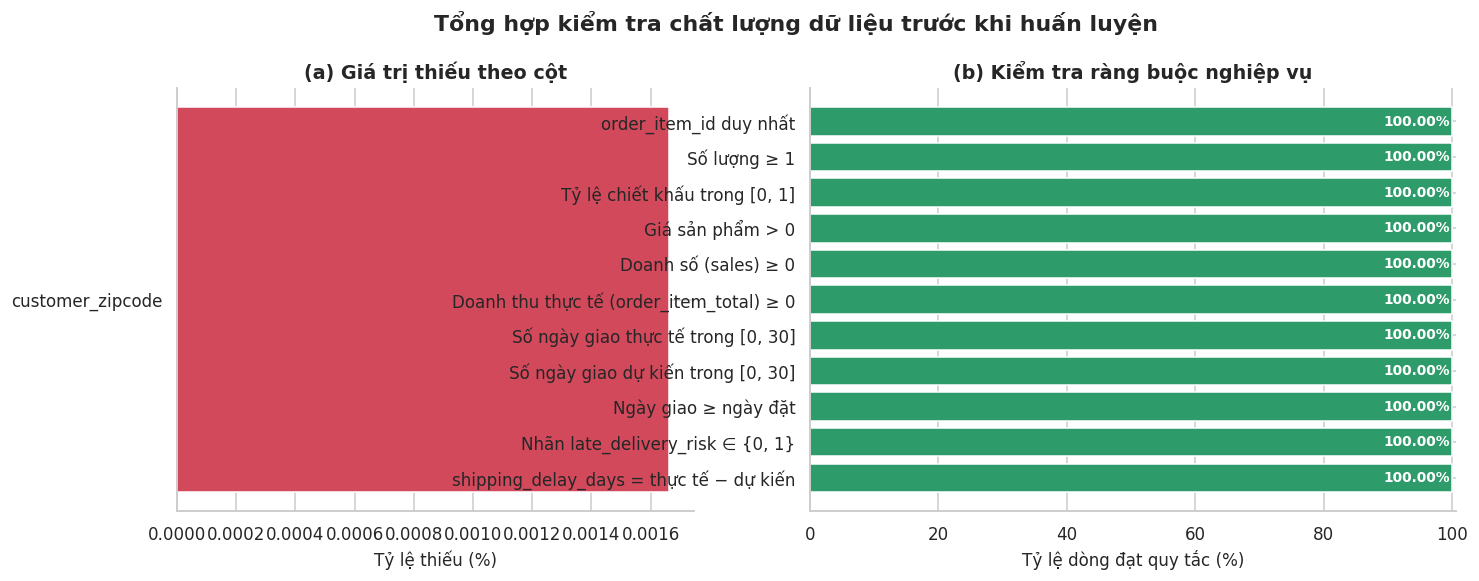

Hình 4.3. Tổng hợp kiểm tra chất lượng dữ liệu của bảng phẳng: (a) tỷ lệ giá trị thiếu theo cột; (b) tỷ lệ dòng đạt từng ràng buộc nghiệp vụ (màu xanh: đạt 100%).
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/03_chat_luong_du_lieu.png



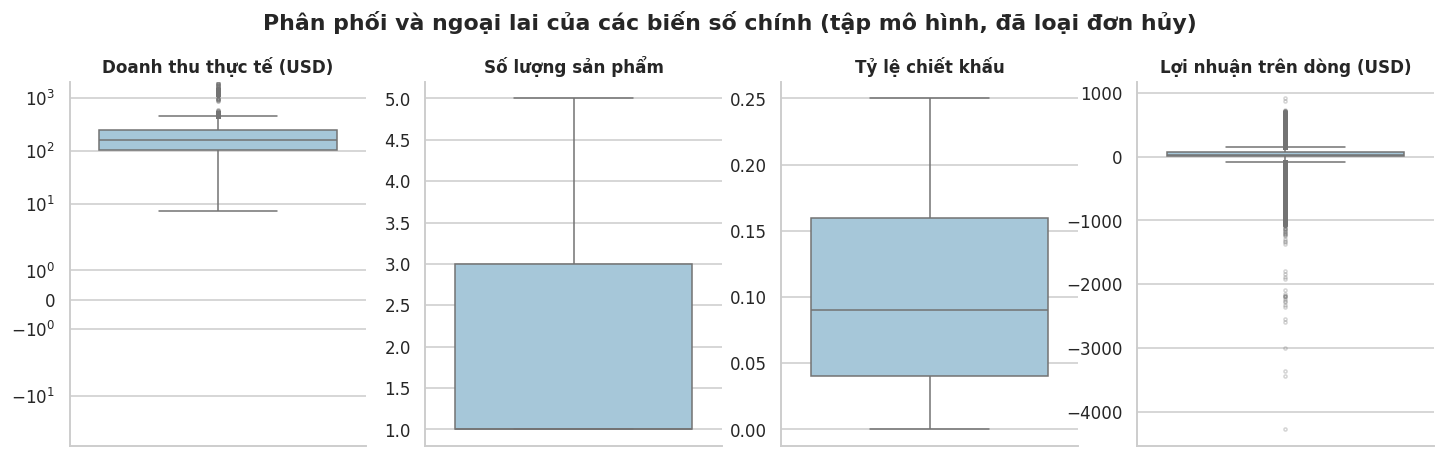

Hình 4.4. Biểu đồ hộp (boxplot) của các biến số chính. Các điểm ngoài râu là đơn hàng giá trị lớn có thật nên được giữ lại; trục doanh thu dùng thang symlog để dễ quan sát.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/04_ngoai_lai_bien_so.png



In [ ]:
# ---------- Hình: tổng hợp chất lượng dữ liệu ----------
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.25]})

ax = axes[0]
if len(miss_nz):
    top = miss_nz.head(12).iloc[::-1]
    ax.barh(top.index, top["ty_le_%"], color=C_RED)
    ax.set_xlabel("Tỷ lệ thiếu (%)")
else:
    ax.axis("off")
    ax.text(0.5, 0.5, "KHÔNG CÓ GIÁ TRỊ THIẾU\ntrong bảng phẳng\n(0 / %d cột)" % df.shape[1],
            ha="center", va="center", fontsize=15, fontweight="bold", color=C_GREEN)
ax.set_title("(a) Giá trị thiếu theo cột")

ax = axes[1]
r = rule_tbl.iloc[::-1]
colors = [C_GREEN if v >= 99.999 else C_ORANGE if v >= 99 else C_RED for v in r["Tỷ lệ đạt (%)"]]
ax.barh(r["Quy tắc"], r["Tỷ lệ đạt (%)"], color=colors)
for i, v in enumerate(r["Tỷ lệ đạt (%)"]):
    ax.text(min(v, 100) - 0.3, i, f"{v:.2f}%", va="center", ha="right", color="white", fontsize=9, fontweight="bold")
ax.set_xlim(0, 100.5); ax.set_xlabel("Tỷ lệ dòng đạt quy tắc (%)")
ax.set_title("(b) Kiểm tra ràng buộc nghiệp vụ")
fig.suptitle("Tổng hợp kiểm tra chất lượng dữ liệu trước khi huấn luyện", fontweight="bold", y=1.02)
save_fig(fig, "chat_luong_du_lieu",
         "Tổng hợp kiểm tra chất lượng dữ liệu của bảng phẳng: (a) tỷ lệ giá trị thiếu theo cột; "
         "(b) tỷ lệ dòng đạt từng ràng buộc nghiệp vụ (màu xanh: đạt 100%).")

# ---------- Hình: ngoại lai ----------
fig, axes = plt.subplots(1, 4, figsize=(16, 4.3))
specs = [("order_item_total", "Doanh thu thực tế (USD)", True), ("order_item_quantity", "Số lượng sản phẩm", False),
         ("order_item_discount_rate", "Tỷ lệ chiết khấu", False), ("benefit_per_order", "Lợi nhuận trên dòng (USD)", False)]
for ax, (c, lab, logy) in zip(axes, specs):
    sns.boxplot(y=df_model[c], ax=ax, color="#9ECAE1", fliersize=2, flierprops={"alpha": 0.3})
    ax.set_ylabel(""); ax.set_title(lab, fontsize=11)
    if logy: ax.set_yscale("symlog")
fig.suptitle("Phân phối và ngoại lai của các biến số chính (tập mô hình, đã loại đơn hủy)", fontweight="bold", y=1.03)
save_fig(fig, "ngoai_lai_bien_so",
         "Biểu đồ hộp (boxplot) của các biến số chính. Các điểm ngoài râu là đơn hàng giá trị lớn có thật nên được giữ lại; "
         "trục doanh thu dùng thang symlog để dễ quan sát.")

---
# PHẦN 6. PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA)

EDA phục vụ ba mục đích: (1) hiểu phân bố nhãn; (2) tìm những yếu tố có liên hệ với giao trễ để **định hướng chọn đặc trưng**; (3) phát hiện sớm các biến gây rò rỉ dữ liệu. Phần này chỉ **mô tả** — mọi phép chọn đặc trưng mang tính thống kê sẽ làm lại trên tập Train ở Phần 9 để tránh nhìn trộm tập Test.

In [ ]:
# Hàm tiện ích dùng chung cho EDA
def late_tbl(d, col):
    t = d.groupby(col)["late_delivery_risk"].agg(rate="mean", n="size").reset_index()
    return t.sort_values("rate", ascending=False).reset_index(drop=True)

def draw_rate_bars(ax, t, col, title, horizontal=False, color=C_BLUE, overall=None):
    labels = t[col].astype(str)
    if horizontal:
        t, labels = t.iloc[::-1], labels.iloc[::-1]
        ax.barh(labels, t["rate"] * 100, color=color)
        for i, (r_, n_) in enumerate(zip(t["rate"], t["n"])):
            ax.text(r_ * 100 + 0.8, i, f"{r_*100:.1f}%  (n={fmt_vn(n_)})", va="center", fontsize=8.5)
        if overall is not None: ax.axvline(overall * 100, ls="--", c=C_RED, lw=1.2)
        ax.set_xlim(0, 125); ax.set_xlabel("Tỷ lệ giao trễ (%)")
    else:
        ax.bar(labels, t["rate"] * 100, color=color)
        for i, (r_, n_) in enumerate(zip(t["rate"], t["n"])):
            ax.text(i, r_ * 100 + 1, f"{r_*100:.1f}%\n(n={fmt_vn(n_)})", ha="center", fontsize=8.5)
        if overall is not None: ax.axhline(overall * 100, ls="--", c=C_RED, lw=1.2, label=f"Trung bình: {overall*100:.1f}%")
        ax.set_ylim(0, 125); ax.set_ylabel("Tỷ lệ giao trễ (%)")
    ax.set_title(title)

OVERALL = df_model["late_delivery_risk"].mean()
print(f"Tỷ lệ giao trễ chung (loại đơn hủy): {OVERALL*100:.2f}%")

Tỷ lệ giao trễ chung (loại đơn hủy): 57.29%


## 6.1. Phân bố trạng thái giao hàng và phân bố nhãn

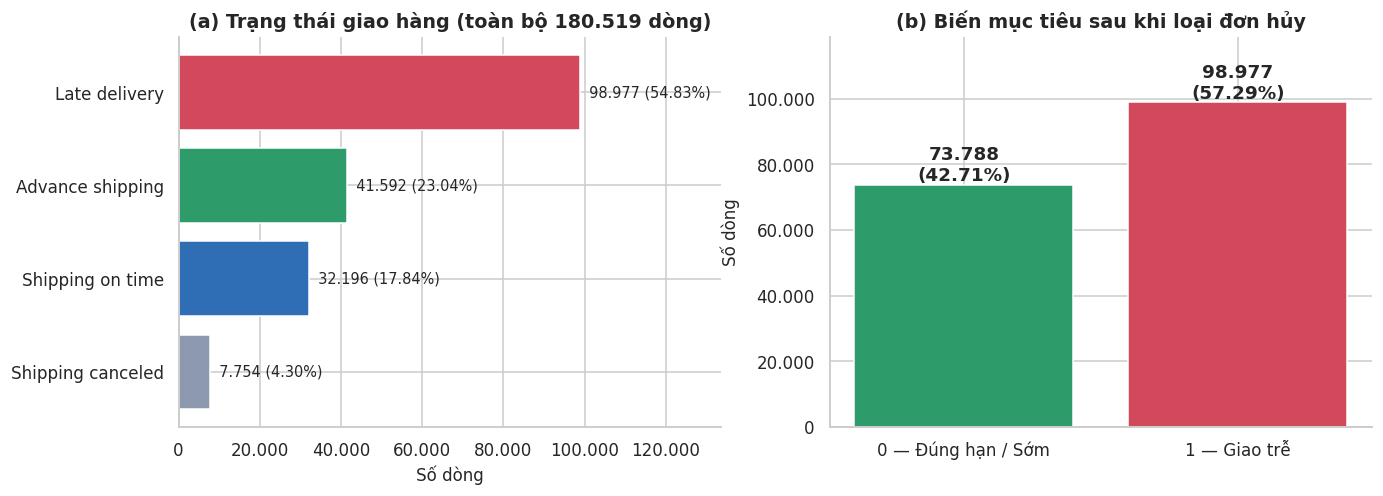

Hình 4.5. (a) Phân bố trạng thái giao hàng trên toàn bộ dữ liệu; (b) phân bố biến mục tiêu late_delivery_risk sau khi loại đơn hủy vận chuyển. Hai lớp tương đối cân bằng (tỷ lệ trễ khoảng 57%), nên không cần kỹ thuật lấy mẫu lại (resampling).
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/05_phan_bo_trang_thai_va_nhan.png



In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ds = df["delivery_status"].value_counts()
palette = {"Late delivery": C_RED, "Advance shipping": C_GREEN, "Shipping on time": C_BLUE, "Shipping canceled": C_GREY}
ax = axes[0]
ax.barh(ds.index[::-1], ds.values[::-1], color=[palette.get(k, C_GREY) for k in ds.index[::-1]])
for i, v in enumerate(ds.values[::-1]):
    ax.text(v, i, f"  {fmt_vn(v)} ({v/len(df)*100:.2f}%)", va="center", fontsize=9.5)
ax.set_xlim(0, ds.max() * 1.35); ax.set_xlabel("Số dòng"); ax.set_title("(a) Trạng thái giao hàng (toàn bộ 180.519 dòng)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, p: fmt_vn(x)))

ax = axes[1]
vc = df_model["late_delivery_risk"].value_counts().sort_index()
ax.bar(["0 — Đúng hạn / Sớm", "1 — Giao trễ"], vc.values, color=[C_GREEN, C_RED])
for i, v in enumerate(vc.values):
    ax.text(i, v, f"{fmt_vn(v)}\n({v/vc.sum()*100:.2f}%)", ha="center", va="bottom", fontweight="bold")
ax.set_ylim(0, vc.max() * 1.2); ax.set_ylabel("Số dòng"); ax.set_title("(b) Biến mục tiêu sau khi loại đơn hủy")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: fmt_vn(x)))
save_fig(fig, "phan_bo_trang_thai_va_nhan",
         "(a) Phân bố trạng thái giao hàng trên toàn bộ dữ liệu; (b) phân bố biến mục tiêu late_delivery_risk sau khi loại đơn hủy "
         "vận chuyển. Hai lớp tương đối cân bằng (tỷ lệ trễ khoảng 57%), nên không cần kỹ thuật lấy mẫu lại (resampling).")

## 6.2. Giao trễ theo phương thức vận chuyển

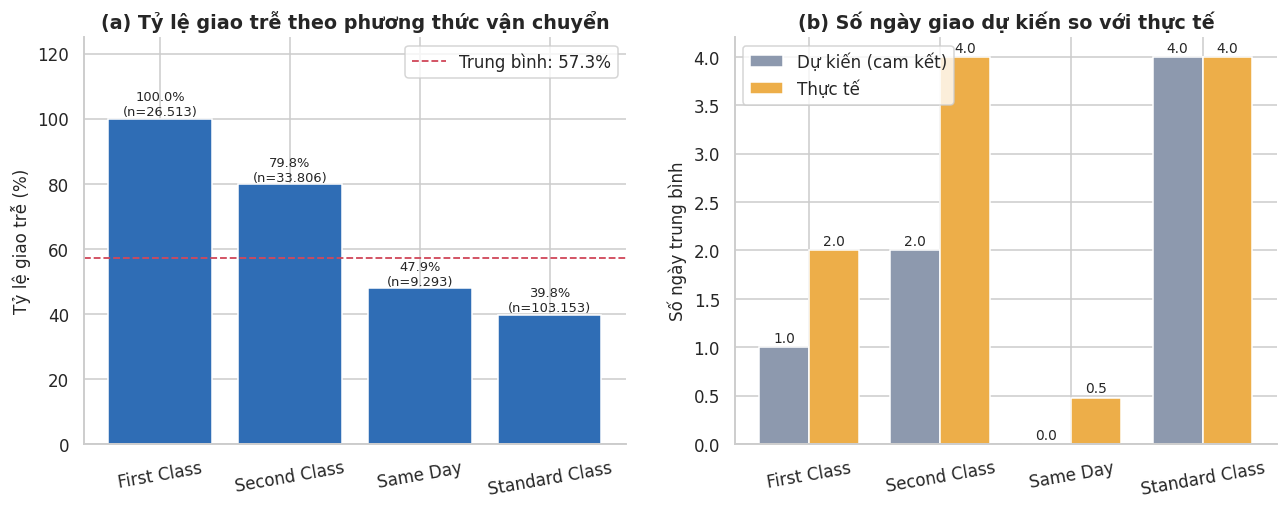

Hình 4.6. (a) Tỷ lệ giao trễ theo phương thức vận chuyển (đường đứt đỏ: trung bình toàn hệ thống); (b) số ngày giao hàng dự kiến so với thực tế. Mỗi phương thức có cam kết thời gian khác nhau nên mức độ trễ khác nhau rõ rệt.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/06_giao_tre_theo_phuong_thuc_van_chuyen.png

Nhận xét tự động: 'First Class' có tỷ lệ trễ cao nhất (100.0%), 'Standard Class' thấp nhất (39.8%).


In [ ]:
t_mode = late_tbl(df_model, "shipping_mode")
mode_days = df_model.groupby("shipping_mode")[["scheduled_shipping_days", "actual_shipping_days"]].mean().loc[t_mode["shipping_mode"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
draw_rate_bars(axes[0], t_mode, "shipping_mode", "(a) Tỷ lệ giao trễ theo phương thức vận chuyển", overall=OVERALL, color=C_BLUE)
axes[0].legend(loc="upper right"); axes[0].tick_params(axis="x", rotation=10)
x = np.arange(len(mode_days)); wd = 0.38
axes[1].bar(x - wd/2, mode_days["scheduled_shipping_days"], wd, label="Dự kiến (cam kết)", color=C_GREY)
axes[1].bar(x + wd/2, mode_days["actual_shipping_days"], wd, label="Thực tế", color=C_ORANGE)
for i, (a, b) in enumerate(zip(mode_days["scheduled_shipping_days"], mode_days["actual_shipping_days"])):
    axes[1].text(i - wd/2, a + 0.05, f"{a:.1f}", ha="center", fontsize=9); axes[1].text(i + wd/2, b + 0.05, f"{b:.1f}", ha="center", fontsize=9)
axes[1].set_xticks(x); axes[1].set_xticklabels(mode_days.index, rotation=10)
axes[1].set_ylabel("Số ngày trung bình"); axes[1].set_title("(b) Số ngày giao dự kiến so với thực tế"); axes[1].legend()
save_fig(fig, "giao_tre_theo_phuong_thuc_van_chuyen",
         "(a) Tỷ lệ giao trễ theo phương thức vận chuyển (đường đứt đỏ: trung bình toàn hệ thống); "
         "(b) số ngày giao hàng dự kiến so với thực tế. Mỗi phương thức có cam kết thời gian khác nhau nên mức độ trễ khác nhau rõ rệt.")
top, bot = t_mode.iloc[0], t_mode.iloc[-1]
print(f"Nhận xét tự động: '{top['shipping_mode']}' có tỷ lệ trễ cao nhất ({top['rate']*100:.1f}%), "
      f"'{bot['shipping_mode']}' thấp nhất ({bot['rate']*100:.1f}%).")

## 6.3. Giao trễ theo thị trường, khu vực, ngành hàng, phân khúc khách hàng và hình thức thanh toán

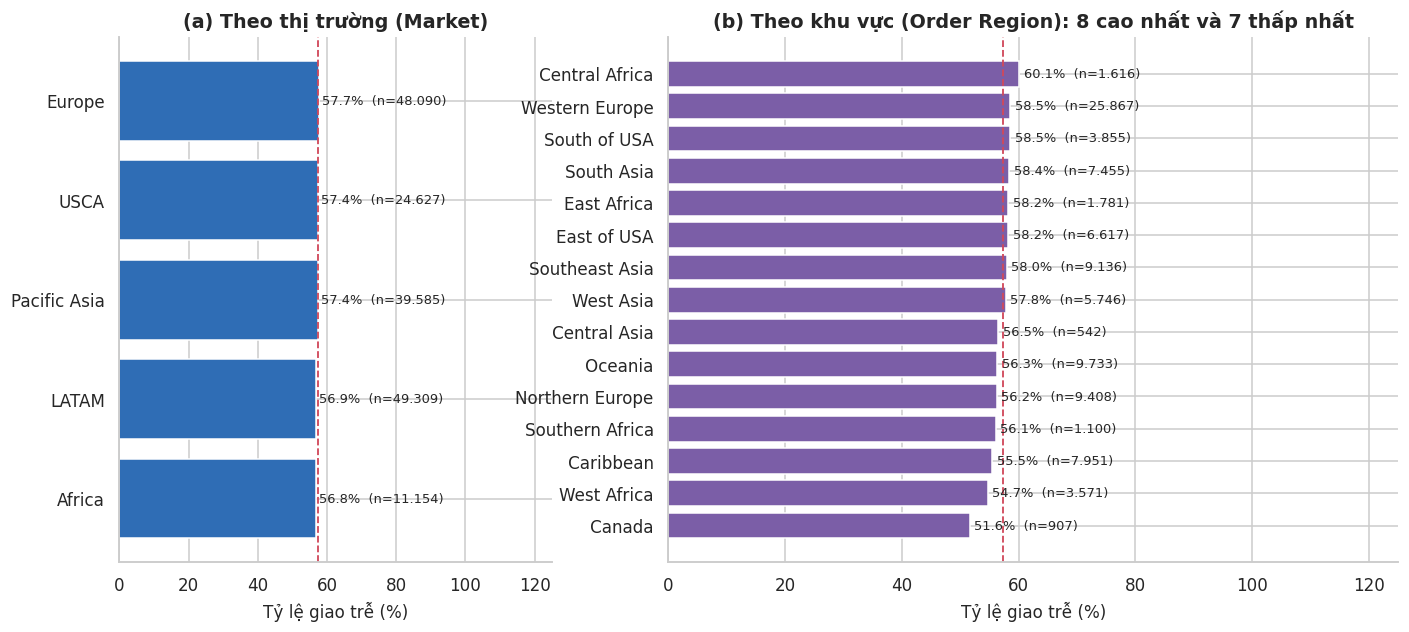

Hình 4.7. Tỷ lệ giao trễ theo (a) thị trường và (b) khu vực nhận hàng (đường đứt đỏ: trung bình). Chênh lệch giữa các thị trường và khu vực nhỏ, cho thấy yếu tố địa lý ít phân biệt được rủi ro giao trễ.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/07_giao_tre_theo_thi_truong_khu_vuc.png



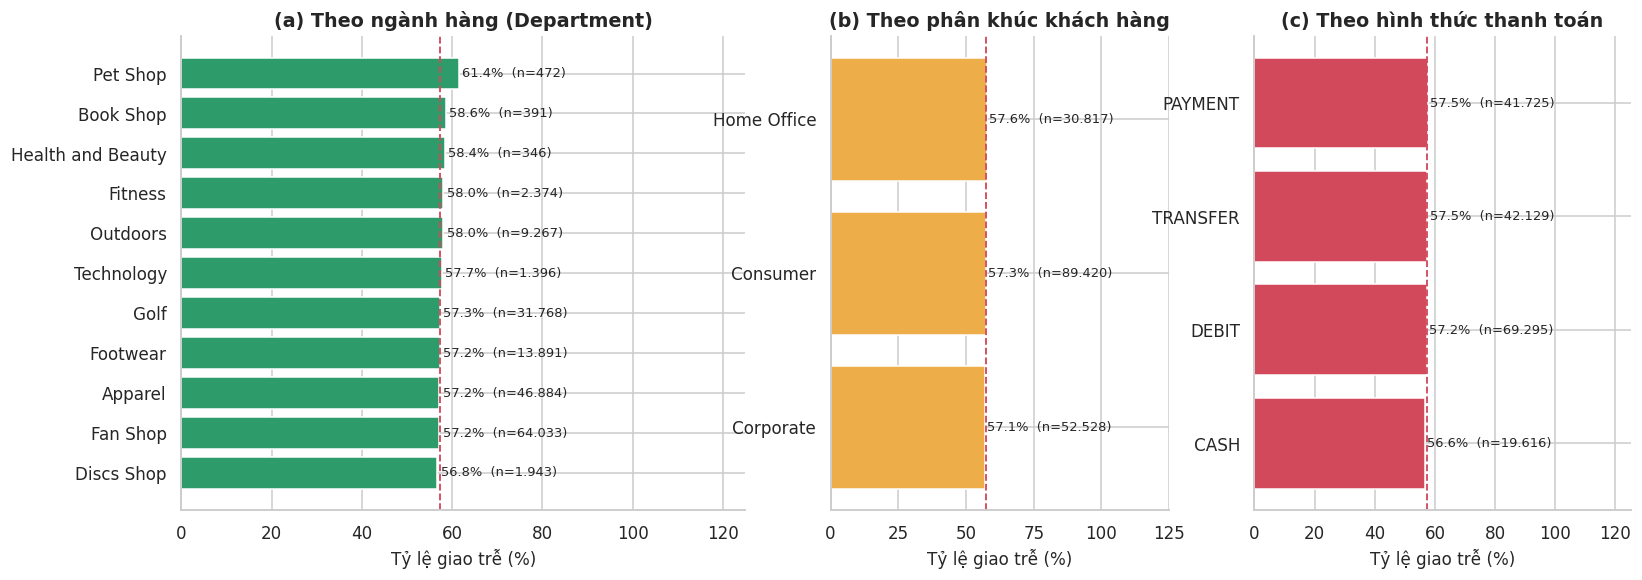

Hình 4.8. Tỷ lệ giao trễ theo (a) ngành hàng, (b) phân khúc khách hàng và (c) hình thức thanh toán. Các nhóm này đều dao động quanh mức trung bình, tức là có liên hệ yếu với nhãn.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/08_giao_tre_theo_nganh_hang_phan_khuc_thanh_toan.png



In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [0.8, 1.35]})
draw_rate_bars(axes[0], late_tbl(df_model, "market"), "market", "(a) Theo thị trường (Market)", horizontal=True, overall=OVERALL, color=C_BLUE)
t_reg = late_tbl(df_model, "order_region")
t_reg = pd.concat([t_reg.head(8), t_reg.tail(7)]).drop_duplicates("order_region") if len(t_reg) > 15 else t_reg
draw_rate_bars(axes[1], t_reg, "order_region", "(b) Theo khu vực (Order Region): 8 cao nhất và 7 thấp nhất", horizontal=True, overall=OVERALL, color=C_PURPLE)
save_fig(fig, "giao_tre_theo_thi_truong_khu_vuc",
         "Tỷ lệ giao trễ theo (a) thị trường và (b) khu vực nhận hàng (đường đứt đỏ: trung bình). "
         "Chênh lệch giữa các thị trường và khu vực nhỏ, cho thấy yếu tố địa lý ít phân biệt được rủi ro giao trễ.")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.6), gridspec_kw={"width_ratios": [1.5, 0.9, 1.0]})
draw_rate_bars(axes[0], late_tbl(df_model, "department_name"), "department_name", "(a) Theo ngành hàng (Department)", horizontal=True, overall=OVERALL, color=C_GREEN)
draw_rate_bars(axes[1], late_tbl(df_model, "customer_segment"), "customer_segment", "(b) Theo phân khúc khách hàng", horizontal=True, overall=OVERALL, color=C_ORANGE)
draw_rate_bars(axes[2], late_tbl(df_model, "payment_type"), "payment_type", "(c) Theo hình thức thanh toán", horizontal=True, overall=OVERALL, color=C_RED)
save_fig(fig, "giao_tre_theo_nganh_hang_phan_khuc_thanh_toan",
         "Tỷ lệ giao trễ theo (a) ngành hàng, (b) phân khúc khách hàng và (c) hình thức thanh toán. "
         "Các nhóm này đều dao động quanh mức trung bình, tức là có liên hệ yếu với nhãn.")

## 6.4. Xu hướng theo thời gian

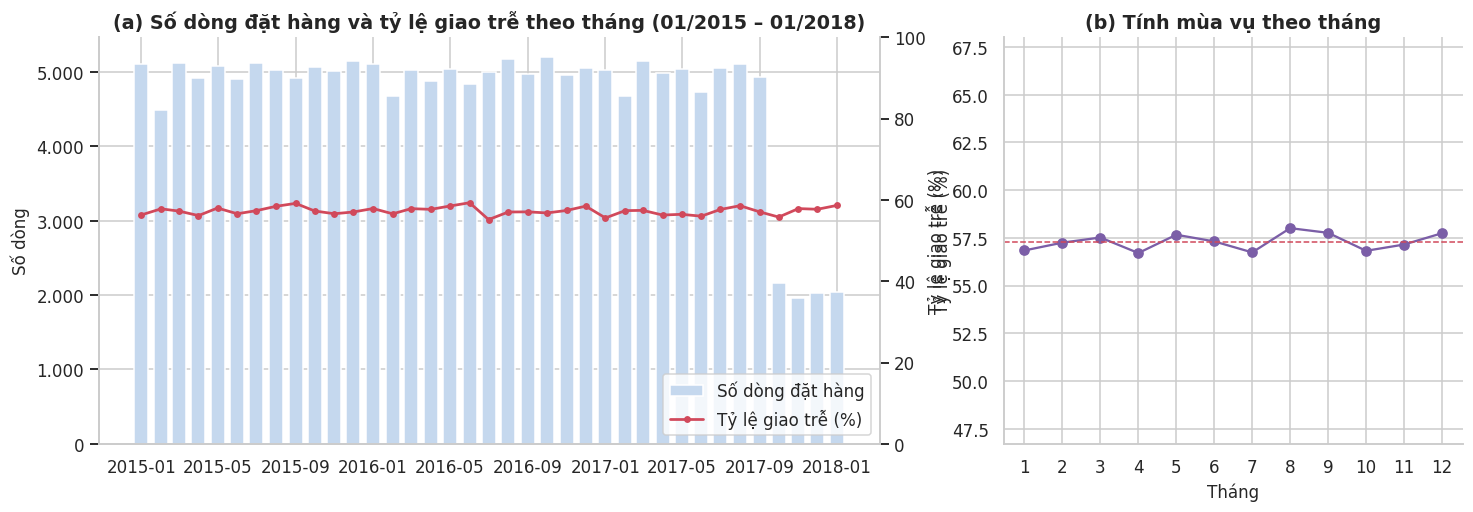

Hình 4.9. (a) Số dòng đặt hàng (cột) và tỷ lệ giao trễ (đường đỏ) theo tháng; năm 2018 chỉ có tháng 01. (b) Tỷ lệ giao trễ trung bình theo tháng trong năm. Tỷ lệ trễ gần như không đổi theo thời gian, cho thấy không có xu hướng hay mùa vụ rõ rệt.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/09_xu_huong_theo_thoi_gian.png

Biên độ tỷ lệ trễ theo tháng trong năm: 56.7% – 58.0%  |  theo thứ trong tuần: 56.6% – 57.8%


In [ ]:
d_t = df_model.copy()
d_t["ym"] = d_t["order_date"].dt.to_period("M").dt.to_timestamp()
ts = d_t.groupby("ym").agg(so_dong=("order_item_id", "size"), ty_le_tre=("late_delivery_risk", "mean")).reset_index()
d_t["thang"] = d_t["order_date"].dt.month
seas = d_t.groupby("thang")["late_delivery_risk"].mean() * 100
dow = d_t.groupby(d_t["order_date"].dt.dayofweek)["late_delivery_risk"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.7, 1]})
ax = axes[0]
ax.bar(ts["ym"], ts["so_dong"], width=22, color="#C5D8EE", label="Số dòng đặt hàng")
ax.set_ylabel("Số dòng"); ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: fmt_vn(x)))
ax2 = ax.twinx(); ax2.spines["right"].set_visible(True)
ax2.plot(ts["ym"], ts["ty_le_tre"] * 100, color=C_RED, marker="o", ms=3.5, lw=1.8, label="Tỷ lệ giao trễ (%)")
ax2.set_ylim(0, 100); ax2.set_ylabel("Tỷ lệ giao trễ (%)"); ax2.grid(False)
ax.set_title("(a) Số dòng đặt hàng và tỷ lệ giao trễ theo tháng (01/2015 – 01/2018)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="lower right")
ax = axes[1]
ax.plot(seas.index, seas.values, marker="o", color=C_PURPLE, label="Theo tháng trong năm")
ax.set_xticks(range(1, 13)); ax.set_xlabel("Tháng"); ax.set_ylabel("Tỷ lệ giao trễ (%)")
ax.set_ylim(max(0, seas.min() - 10), min(100, seas.max() + 10)); ax.axhline(OVERALL * 100, ls="--", c=C_RED, lw=1)
ax.set_title("(b) Tính mùa vụ theo tháng")
save_fig(fig, "xu_huong_theo_thoi_gian",
         "(a) Số dòng đặt hàng (cột) và tỷ lệ giao trễ (đường đỏ) theo tháng; năm 2018 chỉ có tháng 01. "
         "(b) Tỷ lệ giao trễ trung bình theo tháng trong năm. Tỷ lệ trễ gần như không đổi theo thời gian, cho thấy không có xu hướng hay mùa vụ rõ rệt.")
print(f"Biên độ tỷ lệ trễ theo tháng trong năm: {seas.min():.1f}% – {seas.max():.1f}%  |  theo thứ trong tuần: {dow.min():.1f}% – {dow.max():.1f}%")

## 6.5. Quan hệ giữa số ngày dự kiến và thực tế — bằng chứng về rò rỉ dữ liệu

Nhãn được **định nghĩa** từ việc số ngày thực tế có vượt số ngày dự kiến hay không. Ma trận dưới đây cho thấy mối liên hệ gần như tất định. Hệ quả: các biến phản ánh kết quả giao hàng (`actual_shipping_days`, `shipping_delay_days`, `delivery_status`) **không được dùng làm đặc trưng** nếu mục tiêu là dự đoán trước khi giao.

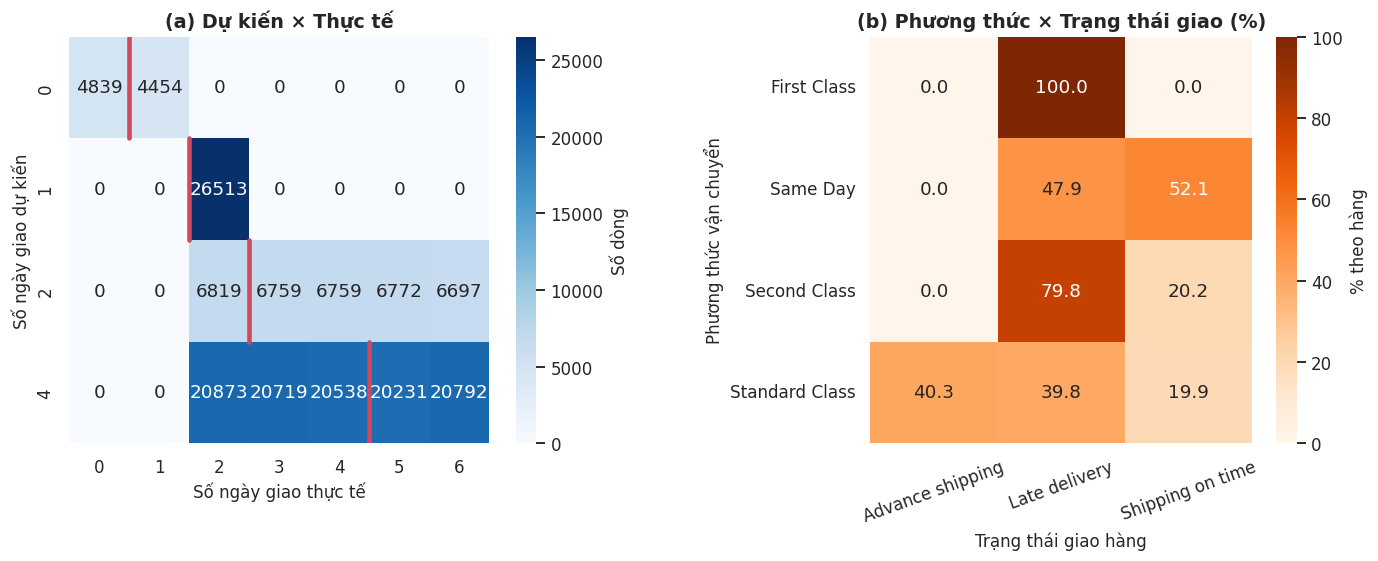

Hình 4.10. (a) Ma trận số dòng theo số ngày giao dự kiến (trục dọc) và thực tế (trục ngang); đường đỏ đánh dấu ranh giới bắt đầu bị tính là trễ. (b) Cơ cấu trạng thái giao hàng theo phương thức vận chuyển (%). Số ngày thực tế quyết định gần như hoàn toàn nhãn, do đó phải loại khỏi đặc trưng để tránh rò rỉ dữ liệu (data leakage).
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/10_du_kien_thuc_te_ro_ri_du_lieu.png



In [ ]:
ct = pd.crosstab(df_model["scheduled_shipping_days"], df_model["actual_shipping_days"])
ct_mode = pd.crosstab(df_model["shipping_mode"], df_model["delivery_status"], normalize="index") * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar_kws={"label": "Số dòng"})
axes[0].set_xlabel("Số ngày giao thực tế"); axes[0].set_ylabel("Số ngày giao dự kiến")
axes[0].set_title("(a) Dự kiến × Thực tế")
# Đường phân cách vùng "trễ" (thực tế > dự kiến)
for sched_val, i in zip(ct.index, range(len(ct.index))):
    j = list(ct.columns).index(sched_val + 1) if (sched_val + 1) in list(ct.columns) else None
    if j is not None:
        axes[0].plot([j, j], [i, i + 1], color=C_RED, lw=3)
sns.heatmap(ct_mode, annot=True, fmt=".1f", cmap="Oranges", ax=axes[1], cbar_kws={"label": "% theo hàng"})
axes[1].set_xlabel("Trạng thái giao hàng"); axes[1].set_ylabel("Phương thức vận chuyển"); axes[1].set_title("(b) Phương thức × Trạng thái giao (%)")
axes[1].tick_params(axis="x", rotation=20)
fig.subplots_adjust(wspace=0.55)
save_fig(fig, "du_kien_thuc_te_ro_ri_du_lieu",
         "(a) Ma trận số dòng theo số ngày giao dự kiến (trục dọc) và thực tế (trục ngang); đường đỏ đánh dấu ranh giới bắt đầu "
         "bị tính là trễ. (b) Cơ cấu trạng thái giao hàng theo phương thức vận chuyển (%). Số ngày thực tế quyết định gần như hoàn toàn nhãn, "
         "do đó phải loại khỏi đặc trưng để tránh rò rỉ dữ liệu (data leakage).")

## 6.6. Phân phối các biến số theo từng lớp nhãn

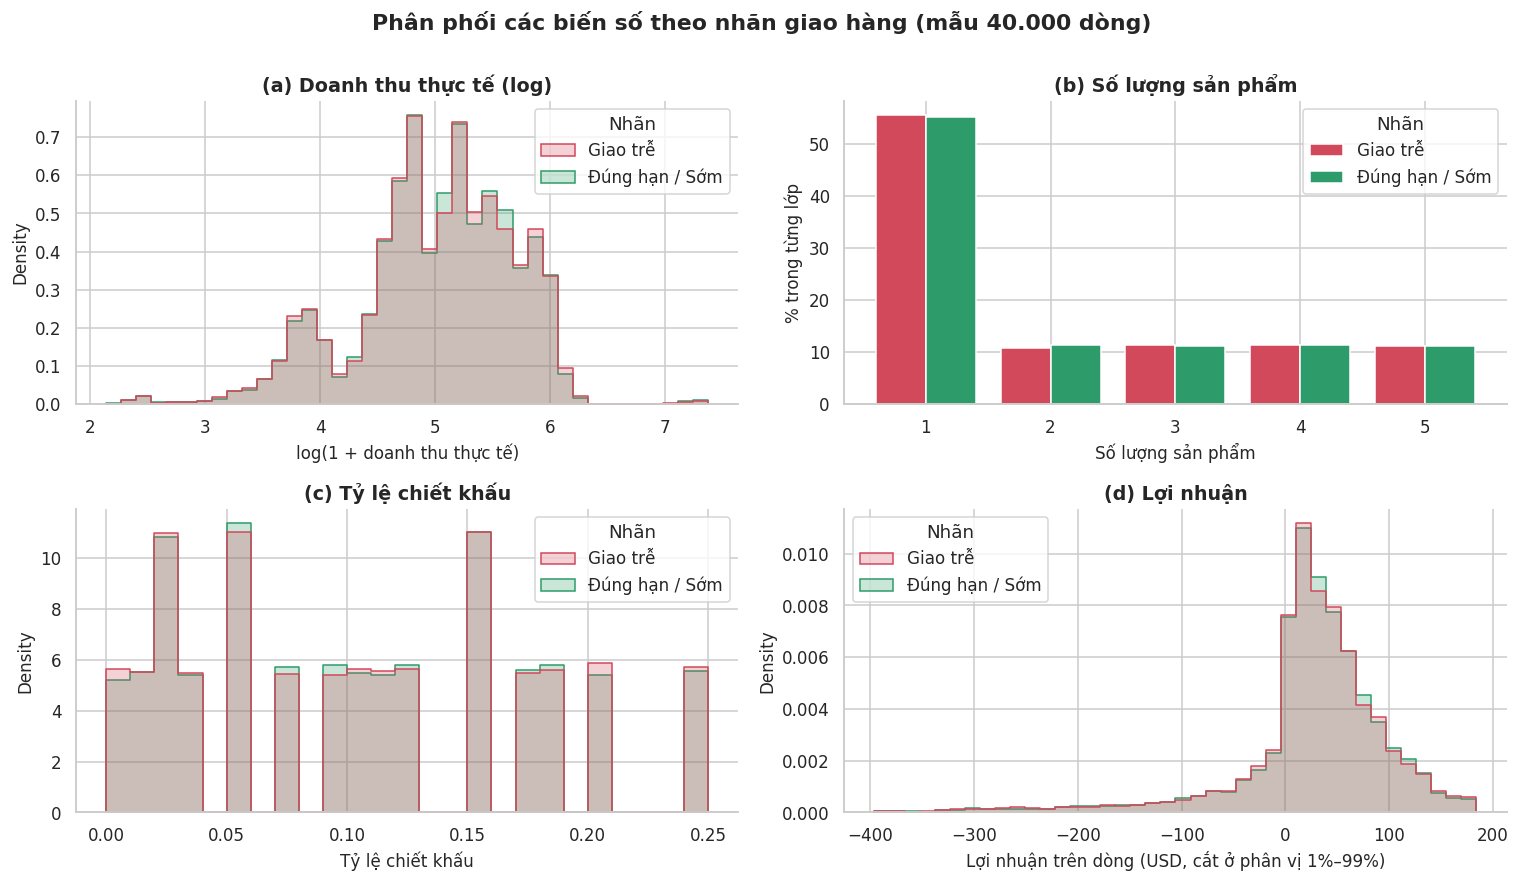

Hình 4.11. Phân phối của (a) doanh thu thực tế (thang log), (b) số lượng sản phẩm, (c) tỷ lệ chiết khấu và (d) lợi nhuận theo từng lớp nhãn. Hai lớp có phân phối gần như trùng nhau, cho thấy các biến tài chính ít phân biệt được giao trễ.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/11_phan_phoi_bien_so_theo_nhan.png



In [ ]:
samp = df_model.sample(n=min(40_000, len(df_model)), random_state=RANDOM_STATE).copy()
samp["Nhãn"] = samp["late_delivery_risk"].map({0: "Đúng hạn / Sớm", 1: "Giao trễ"})
samp["log_total"] = np.log1p(samp["order_item_total"].clip(lower=0))
lo, hi = samp["benefit_per_order"].quantile([0.01, 0.99])
pal = {"Đúng hạn / Sớm": C_GREEN, "Giao trễ": C_RED}

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
sns.histplot(data=samp, x="log_total", hue="Nhãn", stat="density", common_norm=False, element="step", palette=pal, ax=axes[0, 0], bins=40)
axes[0, 0].set_xlabel("log(1 + doanh thu thực tế)"); axes[0, 0].set_title("(a) Doanh thu thực tế (log)")
qtab = samp.groupby(["order_item_quantity", "Nhãn"]).size().unstack(fill_value=0)
(qtab / qtab.sum() * 100).plot(kind="bar", ax=axes[0, 1], color=[pal[c] for c in qtab.columns], width=0.8)
axes[0, 1].set_xlabel("Số lượng sản phẩm"); axes[0, 1].set_ylabel("% trong từng lớp"); axes[0, 1].set_title("(b) Số lượng sản phẩm"); axes[0, 1].tick_params(axis="x", rotation=0)
sns.histplot(data=samp, x="order_item_discount_rate", hue="Nhãn", stat="density", common_norm=False, element="step", palette=pal, ax=axes[1, 0], bins=25)
axes[1, 0].set_xlabel("Tỷ lệ chiết khấu"); axes[1, 0].set_title("(c) Tỷ lệ chiết khấu")
sns.histplot(data=samp[samp["benefit_per_order"].between(lo, hi)], x="benefit_per_order", hue="Nhãn", stat="density", common_norm=False,
             element="step", palette=pal, ax=axes[1, 1], bins=40)
axes[1, 1].set_xlabel("Lợi nhuận trên dòng (USD, cắt ở phân vị 1%–99%)"); axes[1, 1].set_title("(d) Lợi nhuận")
fig.suptitle("Phân phối các biến số theo nhãn giao hàng (mẫu 40.000 dòng)", fontweight="bold", y=1.0)
fig.tight_layout()
save_fig(fig, "phan_phoi_bien_so_theo_nhan",
         "Phân phối của (a) doanh thu thực tế (thang log), (b) số lượng sản phẩm, (c) tỷ lệ chiết khấu và (d) lợi nhuận theo từng lớp nhãn. "
         "Hai lớp có phân phối gần như trùng nhau, cho thấy các biến tài chính ít phân biệt được giao trễ.")

## 6.7. Tương quan giữa các biến số và với nhãn

Biểu đồ cột bên phải tô **đỏ** những biến gây rò rỉ dữ liệu (chỉ biết sau khi giao hàng), tô xanh những biến hợp lệ. Tương quan cao của nhóm đỏ với nhãn không phải là "đặc trưng tốt" mà là "dấu hiệu gian lận" của dữ liệu.

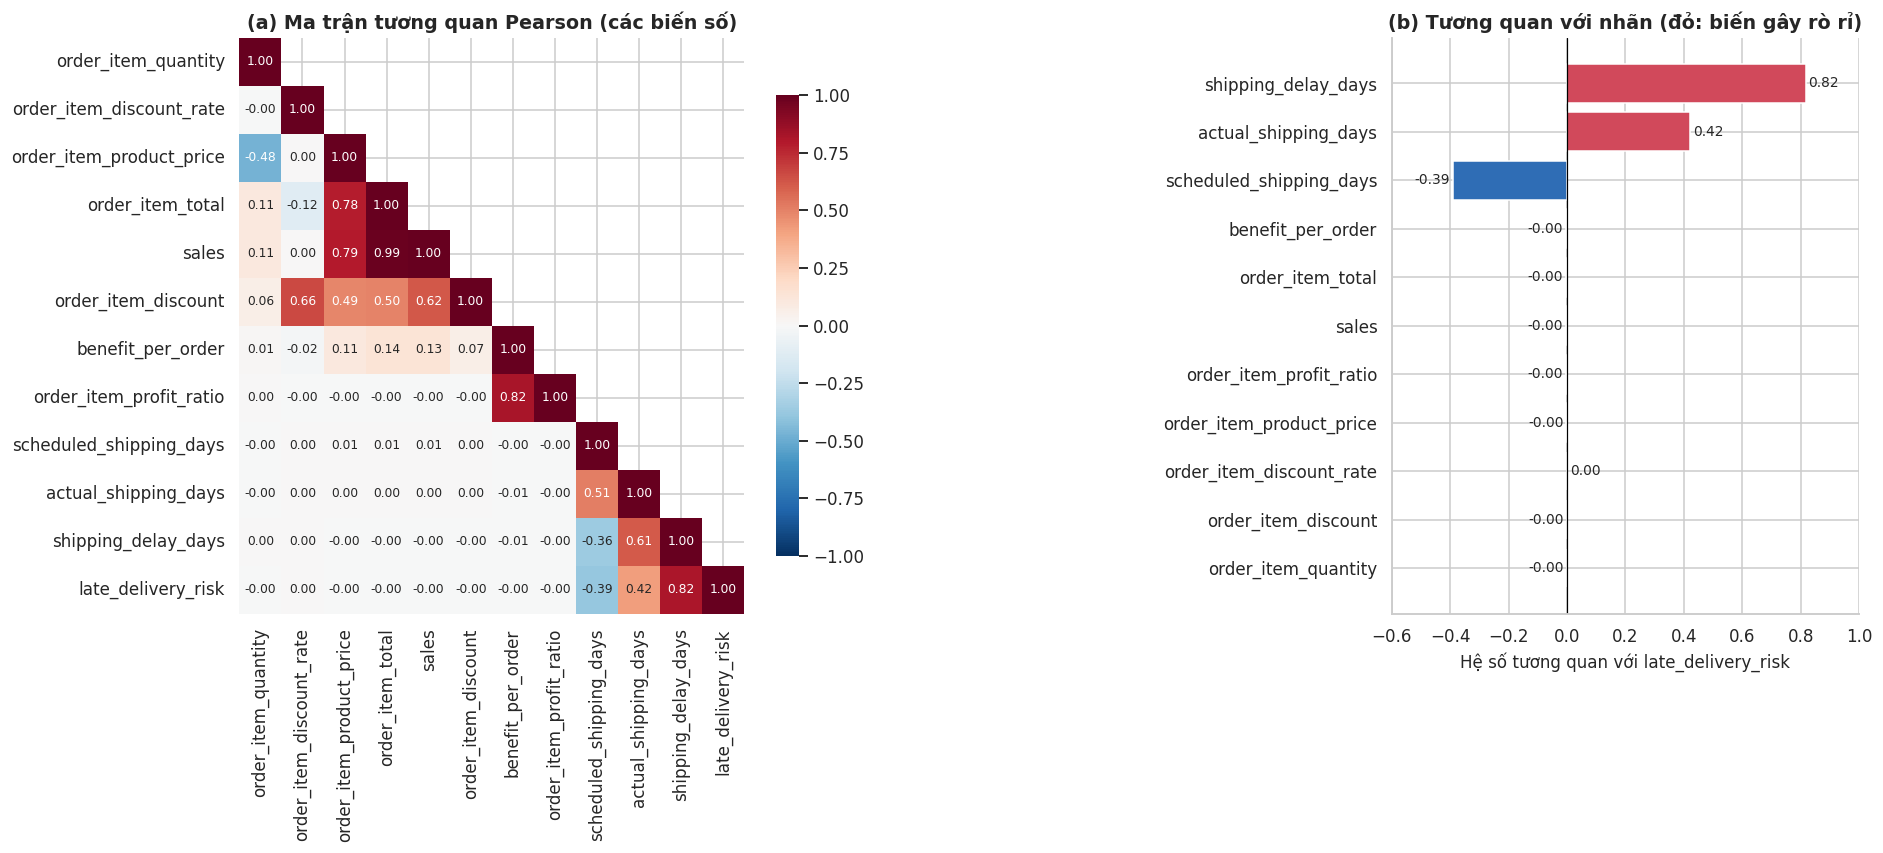

Hình 4.12. (a) Ma trận tương quan Pearson giữa các biến số. (b) Tương quan của từng biến với nhãn late_delivery_risk; màu đỏ là các biến chỉ biết sau khi giao hàng (gây rò rỉ dữ liệu), màu xanh là biến hợp lệ. Doanh số, doanh thu và chiết khấu tương quan rất cao với nhau nên cần loại bớt để tránh đa cộng tuyến.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/12_tuong_quan_bien_so.png

Các cặp biến có |r| ≥ 0,9 (đa cộng tuyến):
  order_item_total             ~ sales                         r = +0.990


In [ ]:
num_scan = ["order_item_quantity", "order_item_discount_rate", "order_item_product_price", "order_item_total", "sales",
            "order_item_discount", "benefit_per_order", "order_item_profit_ratio",
            "scheduled_shipping_days", "actual_shipping_days", "shipping_delay_days", "late_delivery_risk"]
LEAKY = {"actual_shipping_days", "shipping_delay_days"}
corr = df_model[num_scan].corr(method="pearson")

fig, axes = plt.subplots(1, 2, figsize=(19, 6.8), gridspec_kw={"width_ratios": [1.35, 1]})
fig.subplots_adjust(wspace=0.95)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0],
            annot_kws={"size": 8}, cbar_kws={"shrink": 0.8})
axes[0].set_title("(a) Ma trận tương quan Pearson (các biến số)")
tc = corr["late_delivery_risk"].drop("late_delivery_risk").sort_values(key=np.abs)
axes[1].barh(tc.index, tc.values, color=[C_RED if i in LEAKY else C_BLUE for i in tc.index])
for i, v in enumerate(tc.values):
    axes[1].text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
axes[1].axvline(0, c="black", lw=0.8); axes[1].set_xlim(-0.6, 1.0); axes[1].set_xlabel("Hệ số tương quan với late_delivery_risk")
axes[1].set_title("(b) Tương quan với nhãn (đỏ: biến gây rò rỉ)")
save_fig(fig, "tuong_quan_bien_so",
         "(a) Ma trận tương quan Pearson giữa các biến số. (b) Tương quan của từng biến với nhãn late_delivery_risk; "
         "màu đỏ là các biến chỉ biết sau khi giao hàng (gây rò rỉ dữ liệu), màu xanh là biến hợp lệ. "
         "Doanh số, doanh thu và chiết khấu tương quan rất cao với nhau nên cần loại bớt để tránh đa cộng tuyến.")

hi_pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(num_scan) for b in num_scan[i+1:] if abs(corr.loc[a, b]) >= 0.9]
print("Các cặp biến có |r| ≥ 0,9 (đa cộng tuyến):")
for a, b, r_ in hi_pairs: print(f"  {a:28s} ~ {b:28s}  r = {r_:+.3f}")

## 6.8. Góc nhìn kinh doanh: doanh thu và lợi nhuận theo ngành hàng

Phần này liên kết kết quả học máy với mục tiêu kinh doanh của đề tài: xác định ngành hàng đóng góp nhiều nhất và so sánh với mức độ rủi ro giao trễ.

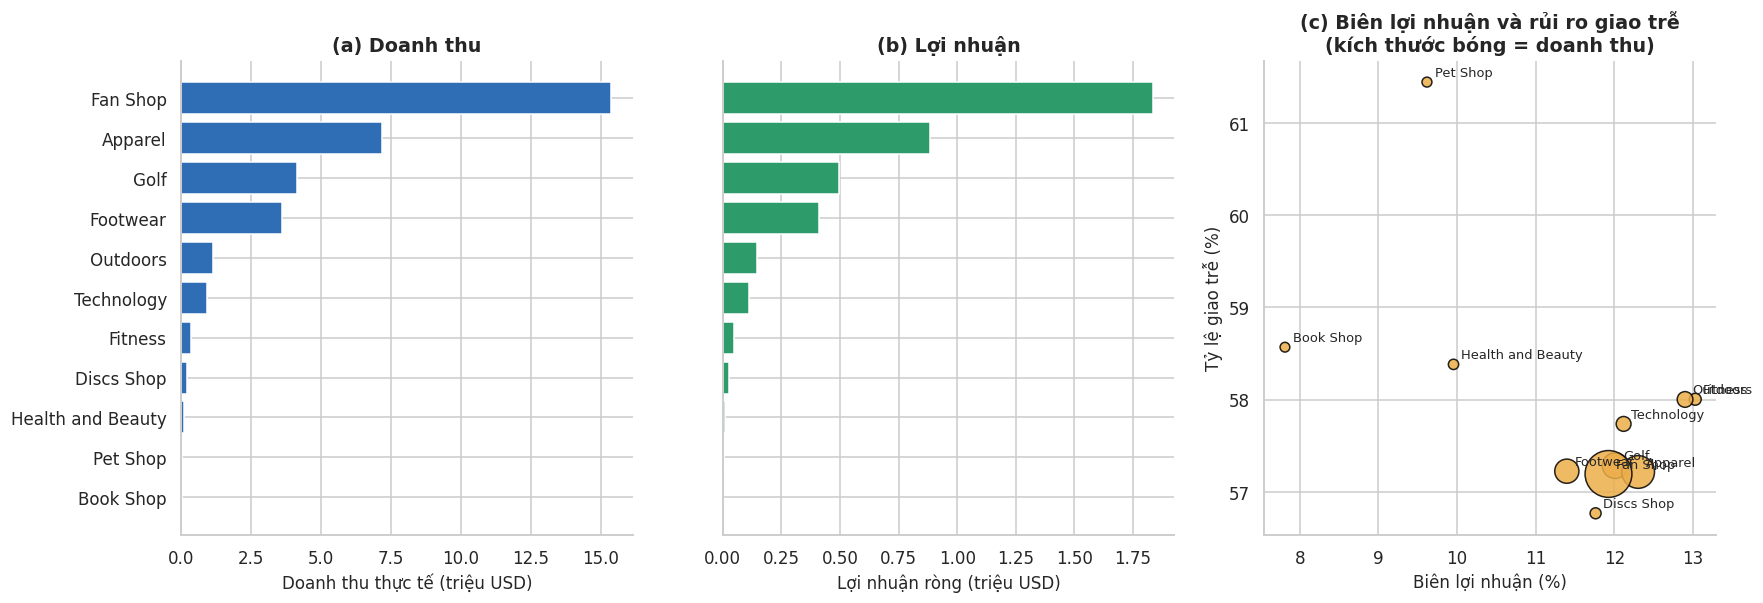

Hình 4.13. (a) Doanh thu thực tế và (b) lợi nhuận ròng theo ngành hàng; (c) quan hệ giữa biên lợi nhuận và tỷ lệ giao trễ của từng ngành (kích thước bóng tỷ lệ với doanh thu). Giúp xác định ngành chủ lực và mức độ rủi ro giao hàng đi kèm.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/13_doanh_thu_loi_nhuan_theo_nganh_hang.png



In [ ]:
dep = df.groupby("department_name").agg(doanh_thu=("order_item_total", "sum"), loi_nhuan=("benefit_per_order", "sum")).sort_values("doanh_thu")
dep["bien_ln_%"] = dep["loi_nhuan"] / dep["doanh_thu"] * 100
dep_late = df_model.groupby("department_name")["late_delivery_risk"].mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
axes[0].barh(dep.index, dep["doanh_thu"] / 1e6, color=C_BLUE); axes[0].set_xlabel("Doanh thu thực tế (triệu USD)"); axes[0].set_title("(a) Doanh thu")
axes[1].barh(dep.index, dep["loi_nhuan"] / 1e6, color=C_GREEN); axes[1].set_xlabel("Lợi nhuận ròng (triệu USD)"); axes[1].set_title("(b) Lợi nhuận")
axes[1].set_yticklabels([])
sc = axes[2].scatter(dep["bien_ln_%"], dep_late.loc[dep.index], s=dep["doanh_thu"] / dep["doanh_thu"].max() * 900 + 40, c=C_ORANGE, edgecolor="black", alpha=0.85)
for name in dep.index:
    axes[2].annotate(name, (dep.loc[name, "bien_ln_%"], dep_late.loc[name]), fontsize=8.5, xytext=(5, 4), textcoords="offset points")
axes[2].set_xlabel("Biên lợi nhuận (%)"); axes[2].set_ylabel("Tỷ lệ giao trễ (%)"); axes[2].set_title("(c) Biên lợi nhuận và rủi ro giao trễ\n(kích thước bóng = doanh thu)")
save_fig(fig, "doanh_thu_loi_nhuan_theo_nganh_hang",
         "(a) Doanh thu thực tế và (b) lợi nhuận ròng theo ngành hàng; (c) quan hệ giữa biên lợi nhuận và tỷ lệ giao trễ của từng ngành "
         "(kích thước bóng tỷ lệ với doanh thu). Giúp xác định ngành chủ lực và mức độ rủi ro giao hàng đi kèm.")

---
# PHẦN 7. CHỌN ĐẶC TRƯNG (BƯỚC QUAN TRỌNG NHẤT)

## 7.1. Định nghĩa bài toán

> **Dự đoán, tại thời điểm đơn hàng được đặt, khả năng đơn đó bị giao trễ** (`late_delivery_risk = 1`).

Đây là bài toán **phân loại nhị phân** trên dữ liệu bảng. Bài toán chỉ có ý nghĩa nghiệp vụ nếu mô hình chỉ dùng những thông tin **đã biết lúc đặt hàng** (hoặc ngay khi xếp lịch giao). Dùng thông tin chỉ có sau khi giao hàng sẽ cho điểm số rất cao nhưng mô hình **vô dụng khi triển khai**. Đó là lỗi *rò rỉ dữ liệu* (data leakage) và là lỗi phổ biến nhất ở bài toán này.

## 7.2. Bốn tiêu chí lọc đặc trưng

| # | Tiêu chí | Ví dụ bị loại |
|---|---|---|
| 1 | **Không rò rỉ**: biết được vào thời điểm dự đoán | `actual_shipping_days`, `shipping_delay_days`, `delivery_status`, `shipping_date`, `order_status` |
| 2 | **Không là định danh**: ID không có tính tổng quát | `order_item_id`, `order_id`, `customer_id`, `product_card_id` |
| 3 | **Không dư thừa / đa cộng tuyến** (|r| ≥ 0,9) | `sales`, `order_item_discount`, `order_item_product_price`, `order_item_profit_ratio` |
| 4 | **Độ phân giải vừa phải**: không có hàng nghìn giá trị | `order_city`, `order_state`, `customer_city`, `customer_zipcode`, `product_name` |

In [ ]:
# Kiểm tra: shipping_mode có quyết định hoàn toàn scheduled_shipping_days không? (nếu có, hai biến mang cùng thông tin)
map_mode = df_model.groupby("shipping_mode")["scheduled_shipping_days"].agg(["nunique", "min", "max"])
display(map_mode)
SCHEDULED_REDUNDANT = bool((map_mode["nunique"] == 1).all())
print(f"scheduled_shipping_days được quyết định hoàn toàn bởi shipping_mode: {SCHEDULED_REDUNDANT}")
if SCHEDULED_REDUNDANT:
    print("→ Hai biến trùng thông tin. Giữ shipping_mode (dễ diễn giải hơn) và loại scheduled_shipping_days "
          "để tránh cộng tuyến hoàn hảo với các biến giả (dummy) của shipping_mode trong Logistic Regression.")

,nunique,min,max
shipping_mode,,,
First Class,1,1,1
Same Day,1,0,0
Second Class,1,2,2
Standard Class,1,4,4


scheduled_shipping_days được quyết định hoàn toàn bởi shipping_mode: True
→ Hai biến trùng thông tin. Giữ shipping_mode (dễ diễn giải hơn) và loại scheduled_shipping_days để tránh cộng tuyến hoàn hảo với các biến giả (dummy) của shipping_mode trong Logistic Regression.


In [ ]:
# ---------- Bảng quyết định cho TỪNG cột của bảng phẳng ----------
KEEP, DROP = "GIỮ", "LOẠI"
decision = {
 # cột: (nhóm, quyết định, lý do)
 "order_item_id":            ("Định danh", DROP, "Mã định danh dòng, không có tính tổng quát"),
 "order_id":                 ("Định danh", DROP, "Chỉ dùng làm biến nhóm khi chia tập (không đưa vào mô hình)"),
 "customer_id":              ("Định danh", DROP, "Mã khách hàng, nguy cơ học thuộc (overfit)"),
 "product_card_id":          ("Định danh", DROP, "Mã sản phẩm; đã có category_name và department_name"),
 "order_status":             ("Rò rỉ", DROP, "Trạng thái xử lý đơn phát sinh SAU khi đặt hàng (COMPLETE, CLOSED, ...)"),
 "shipping_date":            ("Rò rỉ", DROP, "Ngày xuất kho: chưa biết lúc đặt hàng; cộng với số ngày thực tế cho ra nhãn"),
 "actual_shipping_days":     ("Rò rỉ", DROP, "Số ngày giao thực tế: nhãn được định nghĩa từ chính biến này"),
 "shipping_delay_days":      ("Rò rỉ", DROP, "= thực tế − dự kiến: quyết định trực tiếp nhãn"),
 "delivery_status":          ("Rò rỉ", DROP, "Trạng thái 'Late delivery' ≡ nhãn (r = 1,00 theo Chương 2)"),
 "is_shipping_canceled":     ("Điều kiện lọc", DROP, "Dùng để loại đơn hủy ở Phần 5; không phải đặc trưng"),
 "late_delivery_risk":       ("Nhãn", "NHÃN", "Biến mục tiêu"),
 "sales":                    ("Dư thừa", DROP, "r = 0,99 với order_item_total (đa cộng tuyến)"),
 "order_item_discount":      ("Dư thừa", DROP, "Số tiền chiết khấu, đã được biểu diễn bởi tỷ lệ chiết khấu và doanh thu"),
 "order_item_product_price": ("Dư thừa", DROP, "Tương quan cao với doanh thu và quyết định bởi sản phẩm (đã có category_name)"),
 "order_item_profit_ratio":  ("Dư thừa", DROP, "Tỷ lệ suy ra từ lợi nhuận và doanh thu"),
 "order_year":               ("Thời gian", DROP, "Xu hướng năm không tổng quát cho tương lai; 2018 chỉ có tháng 01"),
 "order_quarter":            ("Thời gian", DROP, "Trùng thông tin với order_month"),
 "order_date":               ("Thời gian", DROP, "Đã tách thành order_month và order_dayofweek"),
 "customer_country":         ("Khách hàng", DROP, "Chỉ vài giá trị, trùng thông tin với địa lý nhận hàng"),
 "customer_state":           ("Khách hàng", DROP, "Độ phân giải cao, ít giá trị dự báo"),
 "customer_city":            ("Khách hàng", DROP, "Độ phân giải cao (hàng trăm giá trị)"),
 "customer_zipcode":         ("Khách hàng", DROP, "Độ phân giải cao, nhiều giá trị mặc định"),
 "product_name":             ("Sản phẩm", DROP, "Độ phân giải cao; đã có category_name"),
 "order_state":              ("Địa lý", DROP, "Độ phân giải cao (hàng trăm giá trị)"),
 "order_city":               ("Địa lý", DROP, "Độ phân giải rất cao (hàng nghìn giá trị)"),
 "scheduled_shipping_days":  ("Vận chuyển", DROP if SCHEDULED_REDUNDANT else KEEP,
                              "Trùng hoàn toàn với shipping_mode (xem kiểm tra trên)" if SCHEDULED_REDUNDANT else "Cam kết thời gian giao, biết lúc đặt"),
 # ---- Đặc trưng được giữ ----
 "shipping_mode":            ("Vận chuyển", KEEP, "Phương thức do khách chọn lúc đặt hàng; mang cam kết thời gian"),
 "market":                   ("Địa lý", KEEP, "Thị trường nhận hàng (5 giá trị)"),
 "order_region":             ("Địa lý", KEEP, "Khu vực nhận hàng (~23 giá trị)"),
 "order_country":            ("Địa lý", KEEP, "Quốc gia nhận hàng; nhóm quốc gia hiếm gộp thành 'infrequent' khi mã hóa"),
 "category_name":            ("Sản phẩm", KEEP, "Danh mục sản phẩm (~50 giá trị)"),
 "department_name":          ("Sản phẩm", KEEP, "Ngành hàng (~11 giá trị)"),
 "customer_segment":         ("Khách hàng", KEEP, "Consumer / Corporate / Home Office"),
 "payment_type":             ("Giao dịch", KEEP, "Hình thức thanh toán, biết lúc đặt"),
 "order_month":              ("Thời gian", KEEP, "Tháng đặt hàng, xử lý như biến phân loại (mùa vụ)"),
 "order_item_quantity":      ("Tài chính", KEEP, "Số lượng sản phẩm, biết lúc đặt"),
 "order_item_discount_rate": ("Tài chính", KEEP, "Tỷ lệ chiết khấu, biết lúc đặt"),
 "order_item_total":         ("Tài chính", KEEP, "Doanh thu thực tế (dùng dạng log1p để giảm lệch phải)"),
 "benefit_per_order":        ("Tài chính", KEEP, "Lợi nhuận trên dòng, tính từ giá bán và chi phí, biết lúc đặt (Chương 2 giữ biến này)"),
}
# Biến phái sinh (không có trong bảng phẳng)
derived = {
 "order_dayofweek":      ("Thời gian", KEEP, "Thứ trong tuần, tách từ order_date (biến phân loại)"),
 "log_order_item_total": ("Tài chính", KEEP, "log1p(order_item_total): giảm lệch phải, giúp Logistic Regression ổn định"),
}
assert set(decision) == set(EXPECTED_WIDE_COLS), f"Bảng quyết định chưa phủ hết cột: {set(EXPECTED_WIDE_COLS) ^ set(decision)}"
# order_item_total được thay bằng log_order_item_total trong mô hình
decision["order_item_total"] = ("Tài chính", "THAY BẰNG log1p", "Doanh thu thực tế; lệch phải mạnh nên dùng log1p(order_item_total) làm đặc trưng")

feat_table = pd.DataFrame([(k, *v) for k, v in {**decision, **derived}.items()], columns=["Cột", "Nhóm", "Quyết định", "Lý do"])
feat_table = feat_table.sort_values(["Quyết định", "Nhóm", "Cột"]).reset_index(drop=True)
pd.set_option("display.max_colwidth", 120)
display(feat_table)
feat_table.to_csv(os.path.join(ART_DIR, "bang_quyet_dinh_dac_trung.csv"), index=False, encoding="utf-8-sig")

,Cột,Nhóm,Quyết định,Lý do
0,payment_type,Giao dịch,GIỮ,"Hình thức thanh toán, biết lúc đặt"
1,customer_segment,Khách hàng,GIỮ,Consumer / Corporate / Home Office
2,category_name,Sản phẩm,GIỮ,Danh mục sản phẩm (~50 giá trị)
3,department_name,Sản phẩm,GIỮ,Ngành hàng (~11 giá trị)
4,order_dayofweek,Thời gian,GIỮ,"Thứ trong tuần, tách từ order_date (biến phân loại)"
5,order_month,Thời gian,GIỮ,"Tháng đặt hàng, xử lý như biến phân loại (mùa vụ)"
6,benefit_per_order,Tài chính,GIỮ,"Lợi nhuận trên dòng, tính từ giá bán và chi phí, biết lúc đặt (Chương 2 giữ biến này)"
7,log_order_item_total,Tài chính,GIỮ,"log1p(order_item_total): giảm lệch phải, giúp Logistic Regression ổn định"
8,order_item_discount_rate,Tài chính,GIỮ,"Tỷ lệ chiết khấu, biết lúc đặt"
9,order_item_quantity,Tài chính,GIỮ,"Số lượng sản phẩm, biết lúc đặt"


In [ ]:
# ---------- Tạo biến phái sinh và xác định danh sách đặc trưng cuối cùng ----------
df_model["order_dayofweek"]      = df_model["order_date"].dt.day_name().str[:3]
df_model["log_order_item_total"] = np.log1p(df_model["order_item_total"].clip(lower=0))
df_model["order_month"]          = df_model["order_date"].dt.month.map(lambda m: f"T{int(m):02d}")   # tháng dưới dạng chuỗi => biến phân loại

CAT_FEATURES = ["shipping_mode", "market", "order_region", "order_country", "category_name", "department_name",
                "customer_segment", "payment_type", "order_month", "order_dayofweek"]
NUM_FEATURES = ["order_item_quantity", "order_item_discount_rate", "log_order_item_total", "benefit_per_order"]
if not SCHEDULED_REDUNDANT:
    NUM_FEATURES.append("scheduled_shipping_days")
FEATURES = CAT_FEATURES + NUM_FEATURES
TARGET, GROUP = "late_delivery_risk", "order_id"

# ---------- Chốt chặn chống rò rỉ: nếu lỡ đưa biến cấm vào, chạy tiếp sẽ báo lỗi ngay ----------
FORBIDDEN = {"actual_shipping_days", "shipping_delay_days", "delivery_status", "shipping_date", "order_status",
             "is_shipping_canceled", "late_delivery_risk", "order_item_id", "order_id", "customer_id", "product_card_id"}
leak = FORBIDDEN & set(FEATURES)
assert not leak, f"RÒ RỈ DỮ LIỆU: các biến cấm đang nằm trong danh sách đặc trưng: {leak}"
print(f"✔ Không có biến rò rỉ trong danh sách đặc trưng.\n")
print(f"Đặc trưng phân loại ({len(CAT_FEATURES)}): {CAT_FEATURES}")
print(f"Đặc trưng số        ({len(NUM_FEATURES)}): {NUM_FEATURES}")

# Kiểm tra đa cộng tuyến (VIF) trên các đặc trưng số
from sklearn.linear_model import LinearRegression
def vif_table(frame):
    Z = (frame - frame.mean()) / frame.std(ddof=0)
    rows = []
    for c in Z.columns:
        others = Z.drop(columns=c)
        r2 = LinearRegression().fit(others, Z[c]).score(others, Z[c])
        rows.append((c, np.inf if r2 >= 1 else 1 / (1 - r2)))
    return pd.DataFrame(rows, columns=["Đặc trưng số", "VIF"]).sort_values("VIF", ascending=False)
vif = vif_table(df_model[NUM_FEATURES])
display(vif)
print("Quy ước: VIF < 5 là tốt; 5–10 cần chú ý; > 10 là đa cộng tuyến nghiêm trọng.")
if (vif["VIF"] > 10).any(): print("⚠ Có đặc trưng VIF > 10 — cân nhắc loại bớt.")

# Tập dữ liệu cho mô hình
for c in CAT_FEATURES:
    df_model[c] = df_model[c].astype("object").where(df_model[c].notna(), np.nan)
X_all = df_model[FEATURES].copy()
y_all = df_model[TARGET].astype(int).copy()
g_all = df_model[GROUP].copy()
print(f"\nX: {X_all.shape} | y: {y_all.shape} | số nhóm (đơn hàng): {g_all.nunique():,}")

✔ Không có biến rò rỉ trong danh sách đặc trưng.

Đặc trưng phân loại (10): ['shipping_mode', 'market', 'order_region', 'order_country', 'category_name', 'department_name', 'customer_segment', 'payment_type', 'order_month', 'order_dayofweek']
Đặc trưng số        (4): ['order_item_quantity', 'order_item_discount_rate', 'log_order_item_total', 'benefit_per_order']


,Đặc trưng số,VIF
2,log_order_item_total,1.077600
0,order_item_quantity,1.048339
3,benefit_per_order,1.014712
1,order_item_discount_rate,1.014291


Quy ước: VIF < 5 là tốt; 5–10 cần chú ý; > 10 là đa cộng tuyến nghiêm trọng.

X: (172765, 14) | y: (172765,) | số nhóm (đơn hàng): 62,897


---
# PHẦN 8. CHIA TẬP DỮ LIỆU: TRAIN / VALIDATION / TEST THEO `order_id`

## 8.1. Nguyên tắc

| Tập | Tỷ lệ | Vai trò |
|---|---|---|
| **Train** | ≈ 71,4% | Học tham số mô hình; tinh chỉnh siêu tham số bằng Cross-Validation |
| **Validation** | ≈ 14,3% | So sánh mô hình, chọn ngưỡng quyết định, chẩn đoán overfitting |
| **Test** | ≈ 14,3% | Đánh giá cuối cùng, **chỉ dùng một lần** |

## 8.2. Vì sao phải chia theo `order_id`, không chia ngẫu nhiên theo dòng?

Một đơn hàng có thể có nhiều dòng (180.519 dòng thuộc 65.752 đơn). Các dòng cùng đơn **dùng chung phương thức vận chuyển, ngày đặt, địa điểm giao và nhãn**. Nếu chia ngẫu nhiên theo dòng, dòng này nằm ở Train còn dòng kia ở Test; mô hình chỉ cần "nhớ" đơn hàng là đoán đúng, làm điểm Test **cao giả**. Chia theo nhóm `order_id` đảm bảo mọi dòng của một đơn nằm trọn vẹn trong **một** tập.

Dùng `StratifiedGroupKFold` với 7 phần: 5 phần làm Train, 1 phần Validation, 1 phần Test (≈ 71,4% / 14,3% / 14,3%). Phương pháp này vừa **giữ nhóm không bị tách**, vừa **giữ tỷ lệ nhãn xấp xỉ đều** giữa các tập.

✔ Không có order_id nào bị chia ra nhiều tập.


,Tập,Số dòng,Số đơn hàng,Tỷ lệ dòng (%),Tỷ lệ giao trễ (%)
0,Train,"123,399","44,927",71.43,57.29
1,Validation,"24,735","8,985",14.32,57.49
2,Test,"24,631","8,985",14.26,57.08


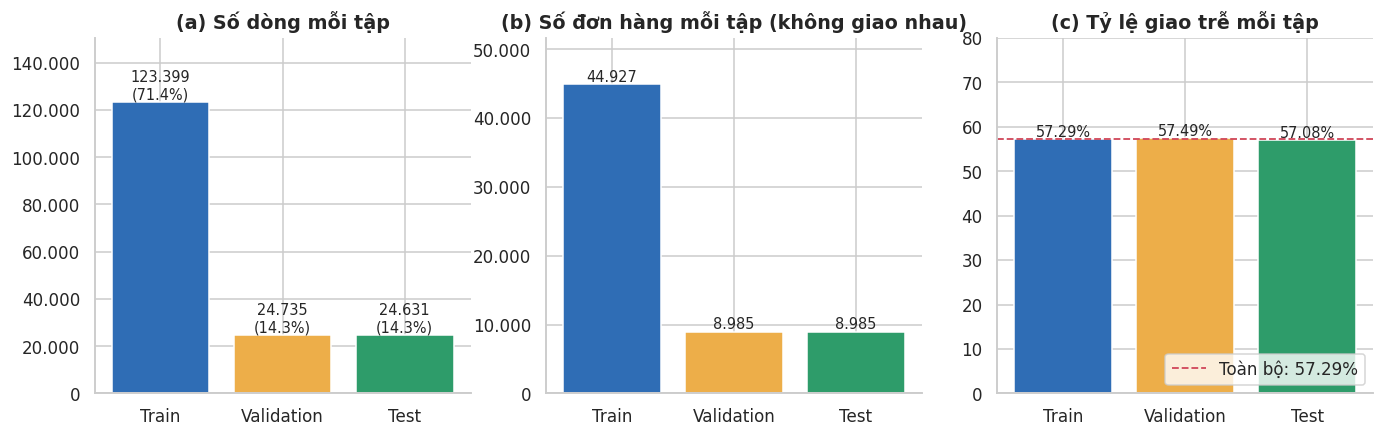

Hình 4.14. Kết quả chia tập theo order_id: (a) số dòng, (b) số đơn hàng (không có đơn nào xuất hiện ở hai tập), (c) tỷ lệ giao trễ của từng tập, xấp xỉ đều nhờ phân tầng theo nhãn (StratifiedGroupKFold).
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/14_chia_tap_train_val_test.png



In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=RANDOM_STATE)
folds = [te for _, te in sgkf.split(X_all, y_all, groups=g_all)]
test_idx  = folds[0]
val_idx   = folds[1]
train_idx = np.concatenate(folds[2:])

X_train, y_train, g_train = X_all.iloc[train_idx], y_all.iloc[train_idx], g_all.iloc[train_idx]
X_val,   y_val,   g_val   = X_all.iloc[val_idx],   y_all.iloc[val_idx],   g_all.iloc[val_idx]
X_test,  y_test,  g_test  = X_all.iloc[test_idx],  y_all.iloc[test_idx],  g_all.iloc[test_idx]

# ---- Kiểm tra bất biến: không có đơn hàng nào xuất hiện ở hai tập ----
s_tr, s_va, s_te = set(g_train), set(g_val), set(g_test)
assert s_tr.isdisjoint(s_va) and s_tr.isdisjoint(s_te) and s_va.isdisjoint(s_te), "Có đơn hàng nằm ở nhiều tập!"
assert len(train_idx) + len(val_idx) + len(test_idx) == len(X_all)
print("✔ Không có order_id nào bị chia ra nhiều tập.")

split_tbl = pd.DataFrame({
    "Tập": ["Train", "Validation", "Test"],
    "Số dòng": [len(X_train), len(X_val), len(X_test)],
    "Số đơn hàng": [len(s_tr), len(s_va), len(s_te)],
    "Tỷ lệ dòng (%)": [len(X_train) / len(X_all) * 100, len(X_val) / len(X_all) * 100, len(X_test) / len(X_all) * 100],
    "Tỷ lệ giao trễ (%)": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
})
display(split_tbl.style.format({"Số dòng": "{:,}", "Số đơn hàng": "{:,}", "Tỷ lệ dòng (%)": "{:.2f}", "Tỷ lệ giao trễ (%)": "{:.2f}"}))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
cols3 = [C_BLUE, C_ORANGE, C_GREEN]
axes[0].bar(split_tbl["Tập"], split_tbl["Số dòng"], color=cols3)
for i, v in enumerate(split_tbl["Số dòng"]): axes[0].text(i, v, f"{fmt_vn(v)}\n({v/len(X_all)*100:.1f}%)", ha="center", va="bottom", fontsize=9.5)
axes[0].set_ylim(0, split_tbl["Số dòng"].max() * 1.22); axes[0].set_title("(a) Số dòng mỗi tập")
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda x, p: fmt_vn(x)))
axes[1].bar(split_tbl["Tập"], split_tbl["Số đơn hàng"], color=cols3)
for i, v in enumerate(split_tbl["Số đơn hàng"]): axes[1].text(i, v, fmt_vn(v), ha="center", va="bottom", fontsize=9.5)
axes[1].set_ylim(0, split_tbl["Số đơn hàng"].max() * 1.15); axes[1].set_title("(b) Số đơn hàng mỗi tập (không giao nhau)")
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda x, p: fmt_vn(x)))
axes[2].bar(split_tbl["Tập"], split_tbl["Tỷ lệ giao trễ (%)"], color=cols3)
for i, v in enumerate(split_tbl["Tỷ lệ giao trễ (%)"]): axes[2].text(i, v + 0.5, f"{v:.2f}%", ha="center", fontsize=9.5)
axes[2].axhline(y_all.mean() * 100, ls="--", c=C_RED, lw=1.2, label=f"Toàn bộ: {y_all.mean()*100:.2f}%")
axes[2].set_ylim(0, 80); axes[2].set_title("(c) Tỷ lệ giao trễ mỗi tập"); axes[2].legend(loc="lower right")
save_fig(fig, "chia_tap_train_val_test",
         "Kết quả chia tập theo order_id: (a) số dòng, (b) số đơn hàng (không có đơn nào xuất hiện ở hai tập), "
         "(c) tỷ lệ giao trễ của từng tập, xấp xỉ đều nhờ phân tầng theo nhãn (StratifiedGroupKFold).")

---
# PHẦN 9. SÀNG LỌC ĐẶC TRƯNG BẰNG THỐNG KÊ (CHỈ TRÊN TẬP TRAIN)

Bước này **xác nhận** danh sách đặc trưng đã chọn ở Phần 7 bằng số liệu, không phải để chọn lại. Vì dùng nhãn, mọi tính toán chỉ thực hiện trên **Train** (nếu tính trên toàn bộ dữ liệu, thông tin của Test đã "chảy" vào quyết định chọn đặc trưng).

- Biến phân loại: **hệ số Cramér's V** (0 = độc lập, 1 = phụ thuộc hoàn toàn) từ kiểm định χ². Dùng V thay vì p-value vì với 120 nghìn dòng, p-value luôn rất nhỏ và không phân biệt được mức độ.
- Biến số: **thông tin tương hỗ (Mutual Information)**, bắt được cả quan hệ phi tuyến.

,Đặc trưng,Cramér's V,p-value (χ²),Bậc tự do,Số giá trị
0,shipping_mode,0.4825,0.00e+00,3,4
1,order_country,0.0517,2.32e-35,158,159
2,order_region,0.0197,7.09e-07,22,23
3,order_dayofweek,0.0140,3.46e-05,6,7
4,order_month,0.0122,1.98e-03,11,12
5,category_name,0.0084,1.85e-01,49,50
6,market,0.0046,1.57e-01,4,5
7,department_name,0.0043,2.70e-01,10,11
8,payment_type,0.0035,2.09e-01,3,4
9,customer_segment,0.0000,7.36e-01,2,3


,Đặc trưng,Mutual Information
0,log_order_item_total,0.00196
1,order_item_quantity,0.00000
2,order_item_discount_rate,0.00000
3,benefit_per_order,0.00000


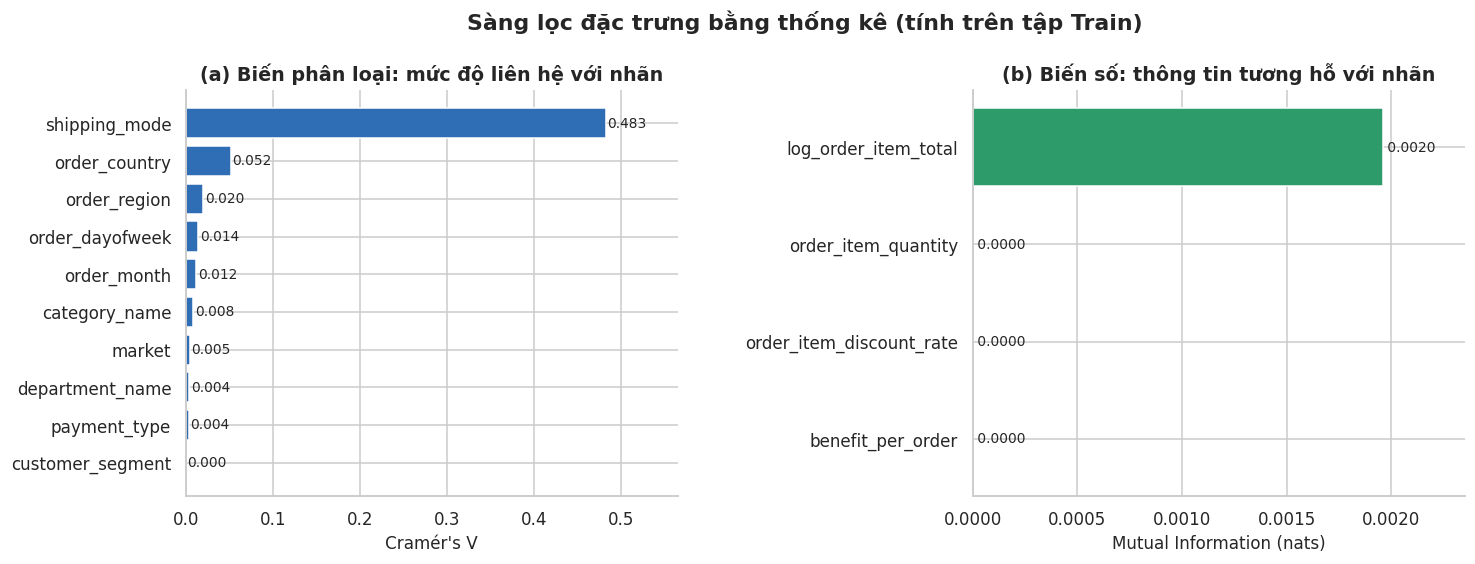

Hình 4.15. Mức độ liên hệ giữa từng đặc trưng với biến mục tiêu, tính trên tập Train: (a) hệ số Cramér's V cho biến phân loại; (b) thông tin tương hỗ cho biến số. Phương thức vận chuyển có liên hệ mạnh nhất; các biến còn lại có liên hệ yếu.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/15_sang_loc_dac_trung_thong_ke.png

Nhận xét tự động: biến phân loại liên hệ mạnh nhất là 'shipping_mode' (V = 0.483).


In [ ]:
from scipy.stats import chi2_contingency
from sklearn.feature_selection import mutual_info_classif

def cramers_v(x, y):
    ctab = pd.crosstab(x, y)
    chi2 = chi2_contingency(ctab, correction=False)[0]
    n = ctab.values.sum(); r, k = ctab.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    denom = min(kc - 1, rc - 1)
    return float(np.sqrt(phi2 / denom)) if denom > 0 else 0.0

cv_rows = []
for c in CAT_FEATURES:
    xc = X_train[c].astype(str)
    chi2_val, p_val, dof, _ = chi2_contingency(pd.crosstab(xc, y_train), correction=False)
    cv_rows.append({"Đặc trưng": c, "Cramér's V": cramers_v(xc, y_train), "p-value (χ²)": p_val, "Bậc tự do": dof, "Số giá trị": xc.nunique()})
cv_tbl = pd.DataFrame(cv_rows).sort_values("Cramér's V", ascending=False).reset_index(drop=True)
display(cv_tbl.style.format({"Cramér's V": "{:.4f}", "p-value (χ²)": "{:.2e}"}))

samp_idx = X_train.sample(n=min(50_000, len(X_train)), random_state=RANDOM_STATE).index
Xn = X_train.loc[samp_idx, NUM_FEATURES].astype(float)
mi = mutual_info_classif(Xn.fillna(Xn.median()), y_train.loc[samp_idx], random_state=RANDOM_STATE, n_neighbors=5)
mi_tbl = pd.DataFrame({"Đặc trưng": NUM_FEATURES, "Mutual Information": mi}).sort_values("Mutual Information", ascending=False).reset_index(drop=True)
display(mi_tbl.style.format({"Mutual Information": "{:.5f}"}))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
fig.subplots_adjust(wspace=0.6)
t = cv_tbl.iloc[::-1]
axes[0].barh(t["Đặc trưng"], t["Cramér's V"], color=C_BLUE)
for i, v in enumerate(t["Cramér's V"]): axes[0].text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9)
axes[0].set_xlim(0, cv_tbl["Cramér's V"].max() * 1.15 + 0.01); axes[0].set_xlabel("Cramér's V"); axes[0].set_title("(a) Biến phân loại: mức độ liên hệ với nhãn")
t = mi_tbl.iloc[::-1]
axes[1].barh(t["Đặc trưng"], t["Mutual Information"], color=C_GREEN)
for i, v in enumerate(t["Mutual Information"]): axes[1].text(v, i, f" {v:.4f}", va="center", fontsize=9)
axes[1].set_xlim(0, max(mi_tbl["Mutual Information"].max() * 1.2, 1e-4)); axes[1].set_xlabel("Mutual Information (nats)"); axes[1].set_title("(b) Biến số: thông tin tương hỗ với nhãn")
fig.suptitle("Sàng lọc đặc trưng bằng thống kê (tính trên tập Train)", fontweight="bold", y=1.03)
save_fig(fig, "sang_loc_dac_trung_thong_ke",
         "Mức độ liên hệ giữa từng đặc trưng với biến mục tiêu, tính trên tập Train: (a) hệ số Cramér's V cho biến phân loại; "
         "(b) thông tin tương hỗ cho biến số. Phương thức vận chuyển có liên hệ mạnh nhất; các biến còn lại có liên hệ yếu.")
V_COL = "Cramér's V"
print(f"Nhận xét tự động: biến phân loại liên hệ mạnh nhất là '{cv_tbl.iloc[0]['Đặc trưng']}' (V = {cv_tbl.iloc[0][V_COL]:.3f}).")

---
# PHẦN 10. TIỀN XỬ LÝ DỮ LIỆU BẰNG PIPELINE

Mọi bước tiền xử lý được đóng gói trong `ColumnTransformer` + `Pipeline` của scikit-learn. Lợi ích then chốt: khi `fit`, Pipeline chỉ học các thống kê (trung vị, trung bình, độ lệch chuẩn, danh sách giá trị) **từ dữ liệu Train**, rồi áp dụng nguyên xi cho Validation/Test. Nếu tự tính trung bình/độ lệch chuẩn trên toàn bộ dữ liệu rồi mới chia, thông tin của tập Test đã rò rỉ vào quá trình huấn luyện.

| Nhóm | Bước | Lý do |
|---|---|---|
| Biến số | Điền thiếu bằng **trung vị** | Trung vị bền với ngoại lai |
| Biến số (chỉ Logistic) | **StandardScaler** | Logistic Regression dùng điều chuẩn L2 và gradient nên nhạy với thang đo. Cây và XGBoost không cần |
| Biến phân loại | Điền thiếu bằng **giá trị phổ biến nhất** | Giữ nguyên cấu trúc |
| Biến phân loại | **One-Hot Encoding**, gộp giá trị hiếm (< 0,5% dòng) vào nhóm `infrequent` | Giữ số cột vừa phải; xử lý được quốc gia/danh mục chưa từng thấy ở Test |

*Vì sao One-Hot mà không dùng Label Encoding?* Label Encoding gán `Africa=0, Europe=1, LATAM=2…` khiến mô hình tuyến tính hiểu nhầm có thứ tự và khoảng cách giữa các thị trường. One-Hot không áp đặt thứ tự.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone

def make_preprocessor(cat_cols, num_cols, scale_numeric):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        num_steps.append(("scaler", StandardScaler()))
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005, sparse_output=True)),
    ])
    transformers = []
    if cat_cols: transformers.append(("cat", cat_pipe, list(cat_cols)))
    if num_cols: transformers.append(("num", Pipeline(num_steps), list(num_cols)))
    return ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=True)

# Minh họa: fit trên Train, kiểm tra kích thước và tính hợp lệ của đầu ra
demo_prep = make_preprocessor(CAT_FEATURES, NUM_FEATURES, scale_numeric=True).fit(X_train)
Xt_demo = demo_prep.transform(X_train)
feat_names = list(demo_prep.get_feature_names_out())
print(f"Sau tiền xử lý: {Xt_demo.shape[1]} cột (từ {len(FEATURES)} đặc trưng gốc) | ma trận thưa: {hasattr(Xt_demo, 'tocsr')}")
n_inf = sum("infrequent" in n for n in feat_names)
print(f"Số cột 'infrequent' (gộp giá trị hiếm): {n_inf}")
dense_chk = Xt_demo.toarray() if hasattr(Xt_demo, "toarray") else Xt_demo
assert not np.isnan(dense_chk).any(), "Còn NaN sau tiền xử lý"
Xv_demo = demo_prep.transform(X_val); Xte_demo = demo_prep.transform(X_test)
assert Xv_demo.shape[1] == Xt_demo.shape[1] == Xte_demo.shape[1]
print("✔ Không còn NaN; Train/Validation/Test có cùng số cột (Validation/Test chỉ được transform, không fit).")

# Số cột sinh ra theo từng đặc trưng phân loại
cols_per = pd.Series({c: sum(n.startswith(f"cat__{c}_") for n in feat_names) for c in CAT_FEATURES}).sort_values(ascending=False)
display(cols_per.to_frame("số cột One-Hot").T)
del dense_chk

Sau tiền xử lý: 124 cột (từ 14 đặc trưng gốc) | ma trận thưa: True
Số cột 'infrequent' (gộp giá trị hiếm): 4
✔ Không còn NaN; Train/Validation/Test có cùng số cột (Validation/Test chỉ được transform, không fit).


,order_country,order_region,category_name,order_month,department_name,order_dayofweek,market,shipping_mode,payment_type,customer_segment
số cột One-Hot,38,22,16,12,9,7,5,4,4,3


---
# PHẦN 11. MÔ HÌNH CƠ SỞ (BASELINE) VÀ HỆ THỐNG CHỈ SỐ ĐÁNH GIÁ

Mô hình học máy chỉ có giá trị khi **vượt được một cách làm đơn giản**. Hai mốc so sánh:

1. **Dự đoán theo tỷ lệ chung (DummyClassifier):** vì lớp "trễ" chiếm ~57% nên luôn đoán "trễ". Cho biết mức tối thiểu cần vượt.
2. **Logistic Regression chỉ với `shipping_mode`:** cho biết riêng phương thức vận chuyển giải thích được bao nhiêu, từ đó thấy các đặc trưng còn lại đóng góp thêm gì.

## Các chỉ số dùng trong đồ án

| Chỉ số | Ý nghĩa | Lưu ý với bài toán này |
|---|---|---|
| **ROC-AUC** | Khả năng xếp hạng đơn trễ cao hơn đơn đúng hạn, không phụ thuộc ngưỡng | Chỉ số chính để chọn mô hình |
| **PR-AUC** | Diện tích dưới đường Precision–Recall | Bổ sung cho ROC-AUC |
| Accuracy | Tỷ lệ đoán đúng | Dễ gây hiểu lầm: đoán "luôn trễ" đã đạt ~57% |
| **Balanced Accuracy** | Trung bình Recall của hai lớp | Công bằng giữa hai lớp |
| Precision / Recall / F1 (lớp trễ) | Chất lượng phát hiện đơn trễ | F1 của lớp trễ bị thổi phồng vì lớp này chiếm đa số |
| **Macro-F1** | F1 trung bình hai lớp | Công bằng hơn F1 của lớp trễ |
| **MCC** | Hệ số tương quan Matthews | Chỉ số đơn lẻ cân bằng nhất cho phân loại nhị phân |
| Brier, Log-loss | Chất lượng của **xác suất** dự đoán | Quan trọng nếu dùng xác suất để xếp hạng rủi ro |

In [ ]:
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef, brier_score_loss, log_loss, confusion_matrix,
                             roc_curve, precision_recall_curve, classification_report)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

def evaluate(y_true, proba, thr=0.5):
    pred = (np.asarray(proba) >= thr).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, proba), "PR-AUC": average_precision_score(y_true, proba),
        "Accuracy": accuracy_score(y_true, pred), "Balanced Acc": balanced_accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0), "Recall": recall_score(y_true, pred),
        "F1 (lớp trễ)": f1_score(y_true, pred), "Macro-F1": f1_score(y_true, pred, average="macro"),
        "MCC": matthews_corrcoef(y_true, pred), "Brier": brier_score_loss(y_true, proba),
        "Log-loss": log_loss(y_true, np.clip(proba, 1e-6, 1 - 1e-6)),
    }

baselines = {
    "Baseline 1: luôn đoán theo tỷ lệ chung (Dummy)": Pipeline([("clf", DummyClassifier(strategy="prior"))]),
    "Baseline 2: Logistic chỉ với shipping_mode": Pipeline([
        ("prep", make_preprocessor(["shipping_mode"], [], True)),
        ("clf", LogisticRegression(max_iter=1000))]),
}
rows = {}
for name, p in baselines.items():
    p.fit(X_train, y_train)
    rows[name] = evaluate(y_val, p.predict_proba(X_val)[:, 1], thr=0.5)
baseline_val = pd.DataFrame(rows).T
display(baseline_val.style.format("{:.4f}"))
print("\nLưu ý: Baseline 1 đoán 'trễ' cho mọi đơn nên Accuracy ≈ tỷ lệ trễ, Recall = 1 và F1 (lớp trễ) trông cao,"
      "\nnhưng Balanced Accuracy = 0,5 và MCC = 0 cho thấy mô hình hoàn toàn không có khả năng phân biệt.")

,ROC-AUC,PR-AUC,Accuracy,Balanced Acc,Precision,Recall,F1 (lớp trễ),Macro-F1,MCC,Brier,Log-loss
Baseline 1: luôn đoán theo tỷ lệ chung (Dummy),0.5000,0.5749,0.5749,0.5000,0.5749,1.0000,0.7301,0.3650,0.0000,0.2444,0.6819
Baseline 2: Logistic chỉ với shipping_mode,0.7400,0.7841,0.6943,0.7225,0.8896,0.5346,0.6679,0.6924,0.4625,0.1884,0.5379



Lưu ý: Baseline 1 đoán 'trễ' cho mọi đơn nên Accuracy ≈ tỷ lệ trễ, Recall = 1 và F1 (lớp trễ) trông cao,
nhưng Balanced Accuracy = 0,5 và MCC = 0 cho thấy mô hình hoàn toàn không có khả năng phân biệt.


---
# PHẦN 12. HUẤN LUYỆN BA MÔ HÌNH (CẤU HÌNH BAN ĐẦU)

| Mô hình | Họ thuật toán | Vì sao phù hợp với bài toán |
|---|---|---|
| **Logistic Regression** | Tuyến tính | Mô hình nền chuẩn; hệ số diễn giải được thành *odds ratio* — trả lời trực tiếp "yếu tố nào làm tăng rủi ro trễ" |
| **Random Forest** | Bagging các cây quyết định | Bắt được quan hệ phi tuyến và tương tác (ví dụ phương thức × thị trường), bền với nhiễu, ít overfit hơn một cây đơn |
| **XGBoost** | Boosting các cây | Thường cho độ chính xác cao nhất trên dữ liệu bảng; có điều chuẩn (regularization) kiểm soát overfit |

**Về mất cân bằng lớp:** tỷ lệ 57/43 chỉ là mất cân bằng nhẹ. Không dùng SMOTE hay `class_weight` (vì chúng làm lệch xác suất dự đoán); thay vào đó **giữ xác suất nguyên bản** và điều chỉnh **ngưỡng quyết định** trên tập Validation ở Phần 14.

Bước này huấn luyện với siêu tham số hợp lý ban đầu để có mốc so sánh; Phần 13 sẽ tinh chỉnh.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

MODEL_NAMES = ["Logistic Regression", "Random Forest", "XGBoost"]

def make_pipelines():
    return {
        "Logistic Regression": Pipeline([
            ("prep", make_preprocessor(CAT_FEATURES, NUM_FEATURES, scale_numeric=True)),
            ("clf", LogisticRegression(max_iter=3000, solver="lbfgs", random_state=RANDOM_STATE))]),
        "Random Forest": Pipeline([
            ("prep", make_preprocessor(CAT_FEATURES, NUM_FEATURES, scale_numeric=False)),
            ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE))]),
        "XGBoost": Pipeline([
            ("prep", make_preprocessor(CAT_FEATURES, NUM_FEATURES, scale_numeric=False)),
            ("clf", XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                                  tree_method="hist", eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE))]),
    }

base_models, base_time = {}, {}
for name, pipe in make_pipelines().items():
    t0 = time.time(); pipe.fit(X_train, y_train); base_time[name] = time.time() - t0
    base_models[name] = pipe
    print(f"✔ {name:20s} huấn luyện xong trong {base_time[name]:6.1f}s")

base_rows = {}
for name, m in base_models.items():
    p_tr, p_va = m.predict_proba(X_train)[:, 1], m.predict_proba(X_val)[:, 1]
    base_rows[name] = {"AUC Train": roc_auc_score(y_train, p_tr), "AUC Validation": roc_auc_score(y_val, p_va),
                       "Chênh lệch (Train − Val)": roc_auc_score(y_train, p_tr) - roc_auc_score(y_val, p_va)}
base_tbl = pd.DataFrame(base_rows).T
display(base_tbl.style.format("{:.4f}"))
print("Chênh lệch Train − Validation lớn ⇒ dấu hiệu overfitting (mô hình học thuộc Train). Sẽ được xử lý ở bước tinh chỉnh.")

✔ Logistic Regression  huấn luyện xong trong    2.5s
✔ Random Forest        huấn luyện xong trong  319.2s
✔ XGBoost              huấn luyện xong trong    9.8s


,AUC Train,AUC Validation,Chênh lệch (Train − Val)
Logistic Regression,0.7529,0.7376,0.0153
Random Forest,0.9485,0.7361,0.2124
XGBoost,0.8545,0.7391,0.1154


Chênh lệch Train − Validation lớn ⇒ dấu hiệu overfitting (mô hình học thuộc Train). Sẽ được xử lý ở bước tinh chỉnh.


---
# PHẦN 13. TINH CHỈNH SIÊU THAM SỐ

## Phương pháp

- **Randomized Search** (tìm kiếm ngẫu nhiên) thay vì Grid Search: với cùng ngân sách tính toán, tìm ngẫu nhiên khám phá được nhiều giá trị hơn trên mỗi siêu tham số (Bergstra & Bengio, 2012).
- **Cross-Validation 3 phần (có phân tầng, theo nhóm `order_id`)** trên tập Train: dùng `StratifiedGroupKFold` để các dòng cùng đơn không nằm ở cả phần huấn luyện và phần kiểm tra bên trong CV. Nếu dùng KFold thường, điểm CV sẽ bị thổi phồng và chọn sai siêu tham số.
- **Tiêu chí:** ROC-AUC (không phụ thuộc ngưỡng).
- **Tập Validation không tham gia tinh chỉnh**, chỉ dùng để so sánh độc lập các mô hình đã tinh chỉnh và chọn ngưỡng; **tập Test chưa được đụng tới**.
- Tiền xử lý nằm **trong Pipeline** nên ở mỗi lần CV, bộ mã hóa chỉ học trên phần huấn luyện của lần đó.

Thời gian chạy phụ thuộc `PROFILE` ở Phần 1 (quick / standard / thorough).

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform

cv_inner = StratifiedGroupKFold(n_splits=CFG["cv_folds"], shuffle=True, random_state=RANDOM_STATE)

param_spaces = {
    "Logistic Regression": {"clf__C": loguniform(1e-3, 1e2)},
    "Random Forest": {"clf__n_estimators": [150, 200, 300], "clf__max_depth": [8, 10, 12, 16],
                      "clf__min_samples_leaf": [5, 10, 20, 50], "clf__max_features": ["sqrt", 0.2, 0.4]},
    "XGBoost": {"clf__n_estimators": randint(150, 600), "clf__learning_rate": loguniform(0.02, 0.2),
                "clf__max_depth": randint(3, 9), "clf__min_child_weight": randint(1, 12),
                "clf__subsample": uniform(0.6, 0.4), "clf__colsample_bytree": uniform(0.5, 0.5),
                "clf__reg_lambda": loguniform(0.5, 20), "clf__gamma": uniform(0, 2)},
}

searches, search_time = {}, {}
for name in MODEL_NAMES:
    n_iter = CFG["n_iter"][name]
    print(f"\n=== Tinh chỉnh {name}: {n_iter} tổ hợp × {CFG['cv_folds']} fold = {n_iter * CFG['cv_folds']} lần huấn luyện ===")
    rs = RandomizedSearchCV(estimator=make_pipelines()[name], param_distributions=param_spaces[name], n_iter=n_iter,
                            scoring="roc_auc", cv=cv_inner, n_jobs=1, random_state=RANDOM_STATE,
                            refit=True, return_train_score=True, verbose=1)
    t0 = time.time()
    rs.fit(X_train, y_train, groups=g_train)
    search_time[name] = time.time() - t0
    searches[name] = rs
    print(f"→ AUC CV tốt nhất: {rs.best_score_:.4f} | thời gian: {search_time[name]/60:.1f} phút")

best_est = {n: searches[n].best_estimator_ for n in MODEL_NAMES}

# Bảng siêu tham số tốt nhất
rows = []
for n in MODEL_NAMES:
    for k, v in searches[n].best_params_.items():
        rows.append({"Mô hình": n, "Siêu tham số": k.replace("clf__", ""), "Giá trị tốt nhất": round(v, 5) if isinstance(v, float) else v})
best_params_tbl = pd.DataFrame(rows)
display(best_params_tbl)
best_params_tbl.to_csv(os.path.join(ART_DIR, "sieu_tham_so_tot_nhat.csv"), index=False, encoding="utf-8-sig")
for n in MODEL_NAMES:
    pd.DataFrame(searches[n].cv_results_).to_csv(os.path.join(ART_DIR, f"cv_results_{n.replace(' ', '_')}.csv"), index=False)


=== Tinh chỉnh Logistic Regression: 8 tổ hợp × 3 fold = 24 lần huấn luyện ===
Fitting 3 folds for each of 8 candidates, totalling 24 fits
→ AUC CV tốt nhất: 0.7391 | thời gian: 1.2 phút

=== Tinh chỉnh Random Forest: 6 tổ hợp × 3 fold = 18 lần huấn luyện ===
Fitting 3 folds for each of 6 candidates, totalling 18 fits
→ AUC CV tốt nhất: 0.7389 | thời gian: 13.4 phút

=== Tinh chỉnh XGBoost: 15 tổ hợp × 3 fold = 45 lần huấn luyện ===
Fitting 3 folds for each of 15 candidates, totalling 45 fits
→ AUC CV tốt nhất: 0.7391 | thời gian: 6.3 phút


,Mô hình,Siêu tham số,Giá trị tốt nhất
0,Logistic Regression,C,0.00195
1,Random Forest,n_estimators,150
2,Random Forest,min_samples_leaf,50
3,Random Forest,max_features,sqrt
4,Random Forest,max_depth,16
5,XGBoost,colsample_bytree,0.59936
6,XGBoost,gamma,0.01104
7,XGBoost,learning_rate,0.13076
8,XGBoost,max_depth,3
9,XGBoost,min_child_weight,8


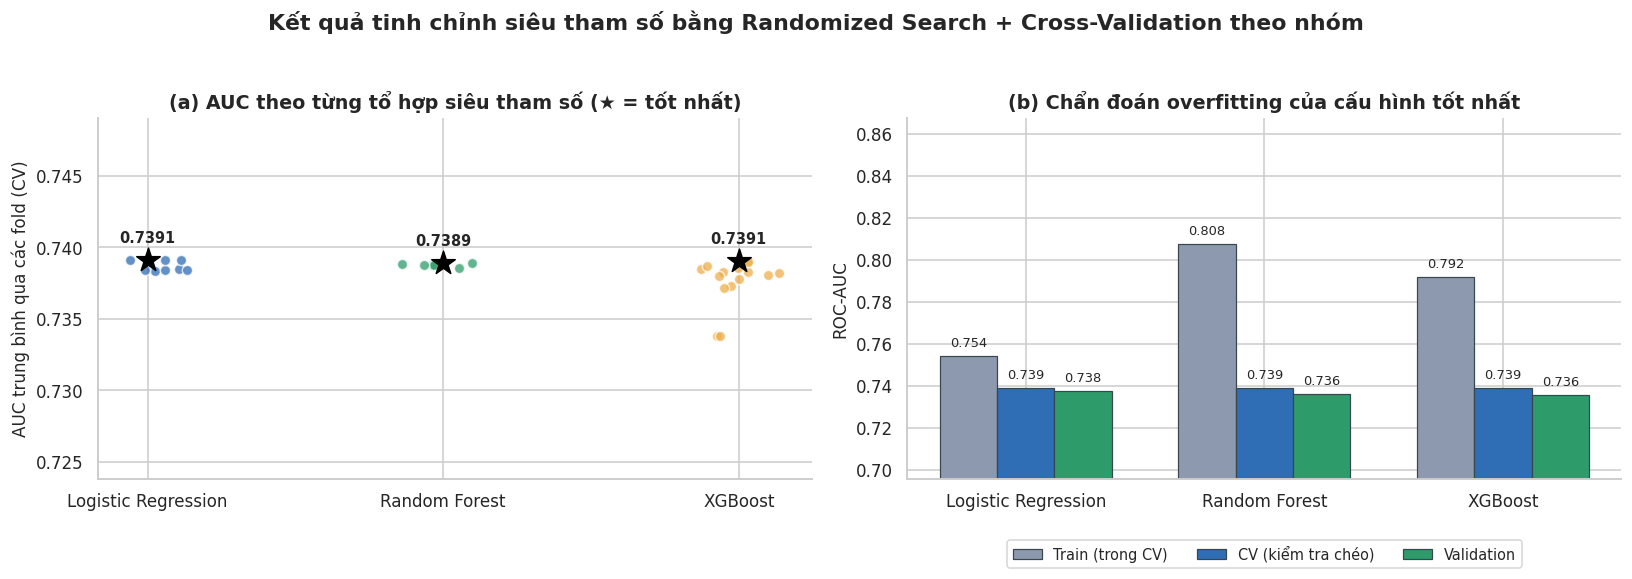

Hình 4.16. (a) AUC kiểm tra chéo của từng tổ hợp siêu tham số đã thử (ngôi sao: tổ hợp tốt nhất). (b) So sánh AUC trên Train, CV và Validation của cấu hình tốt nhất; khoảng cách nhỏ giữa các cột cho thấy mô hình không bị overfitting.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/16_ket_qua_tinh_chinh_sieu_tham_so.png



In [ ]:
# ---------- Hình: kết quả tinh chỉnh ----------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
ax = axes[0]
for i, n in enumerate(MODEL_NAMES):
    cvr = pd.DataFrame(searches[n].cv_results_)
    sc = cvr["mean_test_score"].values
    xs = np.random.RandomState(i).normal(i, 0.06, len(sc))
    ax.scatter(xs, sc, s=45, color=MODEL_COLORS[n], alpha=0.75, edgecolor="white", label=n)
    ax.scatter([i], [sc.max()], marker="*", s=260, color="black", zorder=5)
    ax.text(i, sc.max() + 0.001, f"{sc.max():.4f}", va="bottom", ha="center", fontsize=9.5, fontweight="bold")
ax.set_xticks(range(len(MODEL_NAMES)))
ax.set_xticklabels(MODEL_NAMES)
ax.set_ylabel("AUC trung bình qua các fold (CV)")
ax.set_title("(a) AUC theo từng tổ hợp siêu tham số (★ = tốt nhất)")
ax.set_ylim(min(sc) - 0.01, max(sc) + 0.01)

ax = axes[1]
x = np.arange(len(MODEL_NAMES))
wd = 0.24
tr = [searches[n].cv_results_["mean_train_score"][searches[n].best_index_] for n in MODEL_NAMES]
cvs = [searches[n].best_score_ for n in MODEL_NAMES]
va = [roc_auc_score(y_val, best_est[n].predict_proba(X_val)[:, 1]) for n in MODEL_NAMES]

for off, vals, lab, col in [(-wd, tr, "Train (trong CV)", C_GREY), (0, cvs, "CV (kiểm tra chéo)", C_BLUE), (wd, va, "Validation", C_GREEN)]:
    ax.bar(x + off, vals, wd, label=lab, color=col, edgecolor="#37474F", lw=0.8)
    for xi, v in zip(x + off, vals):
        ax.text(xi, v + 0.003, f"{v:.3f}", ha="center", va="bottom", fontsize=8.5, rotation=0)

lo_y = min(min(tr), min(cvs), min(va)) - 0.04
ax.set_ylim(max(0.4, lo_y), min(1.0, max(tr + cvs + va) + 0.06))
ax.set_xticks(x)
ax.set_xticklabels(MODEL_NAMES)
ax.set_ylabel("ROC-AUC")
ax.set_title("(b) Chẩn đoán overfitting của cấu hình tốt nhất")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=9.5)

fig.suptitle("Kết quả tinh chỉnh siêu tham số bằng Randomized Search + Cross-Validation theo nhóm", fontweight="bold", y=1.03)
plt.tight_layout()
save_fig(fig, "ket_qua_tinh_chinh_sieu_tham_so",
         "(a) AUC kiểm tra chéo của từng tổ hợp siêu tham số đã thử (ngôi sao: tổ hợp tốt nhất). "
         "(b) So sánh AUC trên Train, CV và Validation của cấu hình tốt nhất; khoảng cách nhỏ giữa các cột cho thấy mô hình không bị overfitting.")

---
# PHẦN 14. ĐÁNH GIÁ TRÊN TẬP VALIDATION, CHỌN NGƯỠNG VÀ CHẨN ĐOÁN MÔ HÌNH

## 14.1. So sánh ba mô hình đã tinh chỉnh

Ở Validation ta (1) so sánh các mô hình, (2) **chọn ngưỡng quyết định** và (3) chẩn đoán overfitting. Ngưỡng 0,5 mặc định không nhất thiết tối ưu; ở đây chọn ngưỡng **tối đa hóa Youden's J = TPR − FPR** (tương đương tối đa Balanced Accuracy), vì cách này đối xử công bằng với cả hai lớp.

*Vì sao không chọn ngưỡng theo F1 của lớp trễ?* Lớp trễ chiếm đa số (~57%), nên "đoán mọi đơn đều trễ" đã cho F1 ≈ 0,73. Tối ưu F1 sẽ đẩy ngưỡng về gần 0 và mô hình dự đoán tất cả đều trễ, trông "đẹp" nhưng vô dụng.

In [ ]:
def youden_threshold(y_true, proba):
    fpr, tpr, thr = roc_curve(y_true, proba)
    j = tpr - fpr
    return float(thr[int(np.argmax(j))])

proba_val  = {n: best_est[n].predict_proba(X_val)[:, 1] for n in MODEL_NAMES}
proba_base = baselines["Baseline 2: Logistic chỉ với shipping_mode"].predict_proba(X_val)[:, 1]
thr_opt = {n: youden_threshold(y_val, proba_val[n]) for n in MODEL_NAMES}

val_05  = pd.DataFrame({n: evaluate(y_val, proba_val[n], 0.5) for n in MODEL_NAMES}).T
val_opt = pd.DataFrame({n: evaluate(y_val, proba_val[n], thr_opt[n]) for n in MODEL_NAMES}).T
val_opt.insert(0, "Ngưỡng", pd.Series(thr_opt))
print("— Validation, ngưỡng mặc định 0,5 —");   display(val_05.style.format("{:.4f}"))
print("— Validation, ngưỡng tối ưu (Youden J) chọn trên chính Validation —"); display(val_opt.style.format("{:.4f}"))

val_auc = {n: val_05.loc[n, "ROC-AUC"] for n in MODEL_NAMES}
best_name = max(val_auc, key=val_auc.get)
second = sorted(val_auc.values())[-2]
print(f"\n★ Mô hình có ROC-AUC Validation cao nhất: {best_name} ({val_auc[best_name]:.4f}); chênh với mô hình kế tiếp: {val_auc[best_name]-second:+.4f}")
if val_auc[best_name] - second < 0.002:
    print("  Chênh lệch rất nhỏ (< 0,002): về mặt thống kê các mô hình hàng đầu gần như tương đương; "
          "khi đó nên ưu tiên mô hình đơn giản/dễ diễn giải hơn.")

— Validation, ngưỡng mặc định 0,5 —


,ROC-AUC,PR-AUC,Accuracy,Balanced Acc,Precision,Recall,F1 (lớp trễ),Macro-F1,MCC,Brier,Log-loss
Logistic Regression,0.7378,0.8331,0.6932,0.7134,0.8372,0.5790,0.6845,0.6930,0.4310,0.1893,0.5469
Random Forest,0.7363,0.8324,0.6956,0.7182,0.8546,0.5669,0.6816,0.6950,0.4443,0.1896,0.5487
XGBoost,0.7360,0.8329,0.6948,0.7199,0.8696,0.5518,0.6752,0.6937,0.4518,0.1895,0.5403


— Validation, ngưỡng tối ưu (Youden J) chọn trên chính Validation —


,Ngưỡng,ROC-AUC,PR-AUC,Accuracy,Balanced Acc,Precision,Recall,F1 (lớp trễ),Macro-F1,MCC,Brier,Log-loss
Logistic Regression,0.7571,0.7378,0.8331,0.6943,0.7225,0.8896,0.5346,0.6679,0.6924,0.4625,0.1893,0.5469
Random Forest,0.5507,0.7363,0.8324,0.6955,0.7229,0.8856,0.5401,0.6710,0.6938,0.4618,0.1896,0.5487
XGBoost,0.5685,0.7360,0.8329,0.6952,0.7231,0.8890,0.5369,0.6695,0.6934,0.4634,0.1895,0.5403



★ Mô hình có ROC-AUC Validation cao nhất: Logistic Regression (0.7378); chênh với mô hình kế tiếp: +0.0015
  Chênh lệch rất nhỏ (< 0,002): về mặt thống kê các mô hình hàng đầu gần như tương đương; khi đó nên ưu tiên mô hình đơn giản/dễ diễn giải hơn.


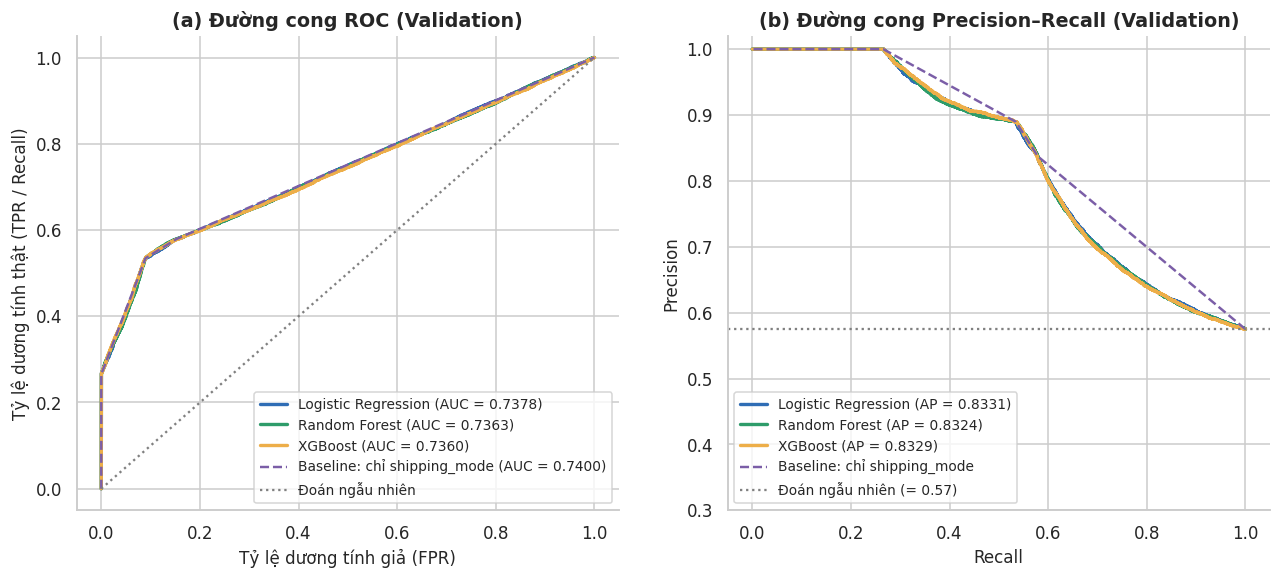

Hình 4.17. Đường cong (a) ROC và (b) Precision–Recall của ba mô hình đã tinh chỉnh trên tập Validation, cùng với mô hình cơ sở chỉ dùng phương thức vận chuyển (nét đứt tím).
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/17_roc_pr_validation.png



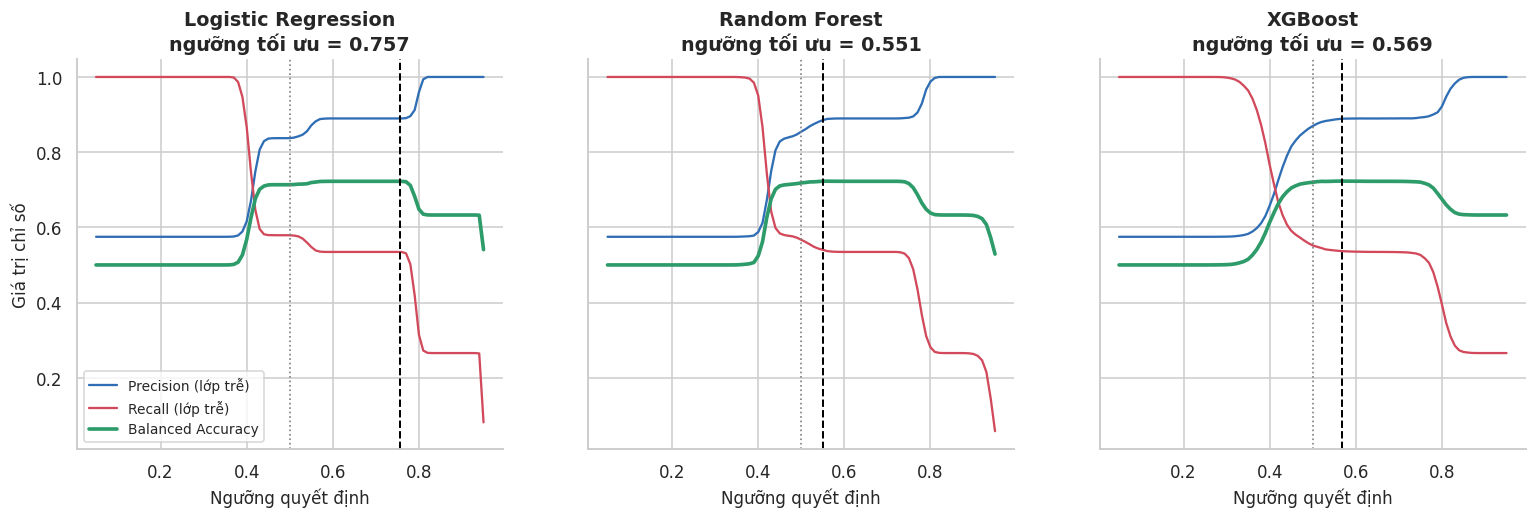

Hình 4.18. Chỉ số Precision, Recall và Balanced Accuracy theo ngưỡng quyết định trên tập Validation. Đường đứt đen là ngưỡng tối ưu (cực đại Youden J), đường chấm xám là ngưỡng mặc định 0,5.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/18_chon_nguong_quyet_dinh.png



In [ ]:
# ---------- Hình: ROC + PR trên Validation ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for n in MODEL_NAMES:
    fpr, tpr, _ = roc_curve(y_val, proba_val[n]); axes[0].plot(fpr, tpr, lw=2.2, color=MODEL_COLORS[n], label=f"{n} (AUC = {val_auc[n]:.4f})")
    pr_, rc_, _ = precision_recall_curve(y_val, proba_val[n]); axes[1].plot(rc_, pr_, lw=2.2, color=MODEL_COLORS[n],
        label=f"{n} (AP = {average_precision_score(y_val, proba_val[n]):.4f})")
fpr, tpr, _ = roc_curve(y_val, proba_base)
axes[0].plot(fpr, tpr, lw=1.6, ls="--", color=C_PURPLE, label=f"Baseline: chỉ shipping_mode (AUC = {roc_auc_score(y_val, proba_base):.4f})")
axes[0].plot([0, 1], [0, 1], ":", c="grey", label="Đoán ngẫu nhiên")
axes[0].set_xlabel("Tỷ lệ dương tính giả (FPR)"); axes[0].set_ylabel("Tỷ lệ dương tính thật (TPR / Recall)")
axes[0].set_title("(a) Đường cong ROC (Validation)"); axes[0].legend(loc="lower right", fontsize=9)
pr_, rc_, _ = precision_recall_curve(y_val, proba_base); axes[1].plot(rc_, pr_, lw=1.6, ls="--", color=C_PURPLE, label="Baseline: chỉ shipping_mode")
axes[1].axhline(y_val.mean(), ls=":", c="grey", label=f"Đoán ngẫu nhiên (= {y_val.mean():.2f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("(b) Đường cong Precision–Recall (Validation)")
axes[1].legend(loc="lower left", fontsize=9); axes[1].set_ylim(0.3, 1.02)
save_fig(fig, "roc_pr_validation",
         "Đường cong (a) ROC và (b) Precision–Recall của ba mô hình đã tinh chỉnh trên tập Validation, "
         "cùng với mô hình cơ sở chỉ dùng phương thức vận chuyển (nét đứt tím).")

# ---------- Hình: chọn ngưỡng ----------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
ths = np.linspace(0.05, 0.95, 91)
for ax, n in zip(axes, MODEL_NAMES):
    pr, rc, ba = [], [], []
    for t in ths:
        pred = (proba_val[n] >= t).astype(int)
        pr.append(precision_score(y_val, pred, zero_division=0)); rc.append(recall_score(y_val, pred)); ba.append(balanced_accuracy_score(y_val, pred))
    ax.plot(ths, pr, color=C_BLUE, label="Precision (lớp trễ)"); ax.plot(ths, rc, color=C_RED, label="Recall (lớp trễ)")
    ax.plot(ths, ba, color=C_GREEN, lw=2.4, label="Balanced Accuracy")
    ax.axvline(thr_opt[n], color="black", ls="--", lw=1.3); ax.axvline(0.5, color="grey", ls=":", lw=1.1)
    ax.set_title(f"{n}\nngưỡng tối ưu = {thr_opt[n]:.3f}"); ax.set_xlabel("Ngưỡng quyết định")
axes[0].set_ylabel("Giá trị chỉ số"); axes[0].legend(loc="lower left", fontsize=9)
save_fig(fig, "chon_nguong_quyet_dinh",
         "Chỉ số Precision, Recall và Balanced Accuracy theo ngưỡng quyết định trên tập Validation. "
         "Đường đứt đen là ngưỡng tối ưu (cực đại Youden J), đường chấm xám là ngưỡng mặc định 0,5.")

## 14.2. Chẩn đoán overfitting bằng đường cong học (learning curve)

Đường cong học cho biết AUC trên Train và Validation thay đổi ra sao khi tăng lượng dữ liệu huấn luyện:
- Hai đường **hội tụ gần nhau** ở mức cao ⇒ mô hình tốt, thêm dữ liệu ít giúp ích.
- Train cao, Validation thấp, khoảng cách rộng ⇒ **overfitting** (phương sai cao).
- Cả hai đều thấp ⇒ **underfitting** (thiên lệch cao): cần đặc trưng tốt hơn chứ không phải thêm dữ liệu.

Lấy mẫu theo **nhóm đơn hàng** để không làm vỡ cấu trúc nhóm.

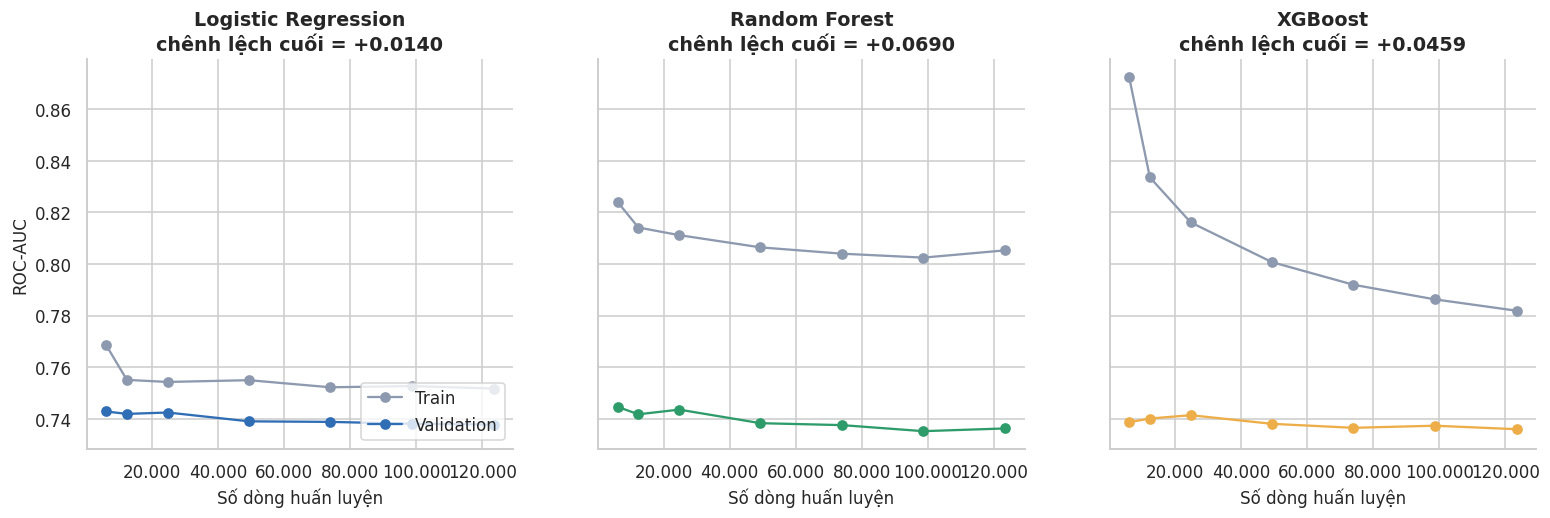

Hình 4.19. Đường cong học của ba mô hình: AUC trên Train (xám) và Validation (màu) theo lượng dữ liệu huấn luyện (lấy mẫu theo nhóm đơn hàng). Khoảng cách giữa hai đường phản ánh mức độ overfitting; hai đường hội tụ ở mức thấp phản ánh giới hạn thông tin của đặc trưng.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/19_duong_cong_hoc.png



,AUC Train,AUC Validation
Logistic Regression,0.7517,0.7378
Random Forest,0.8052,0.7363
XGBoost,0.7819,0.7360


In [ ]:
def learning_curve_by_group(pipe, fractions):
    rng = np.random.RandomState(RANDOM_STATE)
    ug = g_train.unique().copy(); rng.shuffle(ug)
    out = []
    for f in fractions:
        sel = set(ug[: max(50, int(len(ug) * f))])
        m = g_train.isin(sel).values
        p = clone(pipe).fit(X_train[m], y_train[m])
        out.append((int(m.sum()), roc_auc_score(y_train[m], p.predict_proba(X_train[m])[:, 1]),
                    roc_auc_score(y_val, p.predict_proba(X_val)[:, 1])))
    return pd.DataFrame(out, columns=["n_train", "AUC Train", "AUC Validation"])

fractions = [0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0]
lc = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
for ax, n in zip(axes, MODEL_NAMES):
    lc[n] = learning_curve_by_group(best_est[n], fractions)
    ax.plot(lc[n]["n_train"], lc[n]["AUC Train"], "o-", color=C_GREY, label="Train")
    ax.plot(lc[n]["n_train"], lc[n]["AUC Validation"], "o-", color=MODEL_COLORS[n], label="Validation")
    gap = lc[n].iloc[-1]["AUC Train"] - lc[n].iloc[-1]["AUC Validation"]
    ax.set_title(f"{n}\nchênh lệch cuối = {gap:+.4f}"); ax.set_xlabel("Số dòng huấn luyện")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, p: fmt_vn(x)))
axes[0].set_ylabel("ROC-AUC"); axes[0].legend(loc="lower right")
save_fig(fig, "duong_cong_hoc",
         "Đường cong học của ba mô hình: AUC trên Train (xám) và Validation (màu) theo lượng dữ liệu huấn luyện (lấy mẫu theo nhóm đơn hàng). "
         "Khoảng cách giữa hai đường phản ánh mức độ overfitting; hai đường hội tụ ở mức thấp phản ánh giới hạn thông tin của đặc trưng.")
display(pd.concat({n: lc[n].iloc[[-1]].set_index("n_train") for n in MODEL_NAMES}).droplevel(1).style.format("{:.4f}"))

## 14.3. Hiệu chỉnh xác suất (calibration)

Một mô hình có thể xếp hạng tốt (AUC cao) nhưng **xác suất** dự đoán lệch thực tế (ví dụ nói 80% nhưng thực tế chỉ 65% trễ). Nếu doanh nghiệp dùng xác suất để xếp hạng hoặc ra quyết định theo mức rủi ro, cần kiểm tra đường hiệu chỉnh: đường càng sát đường chéo càng tốt.

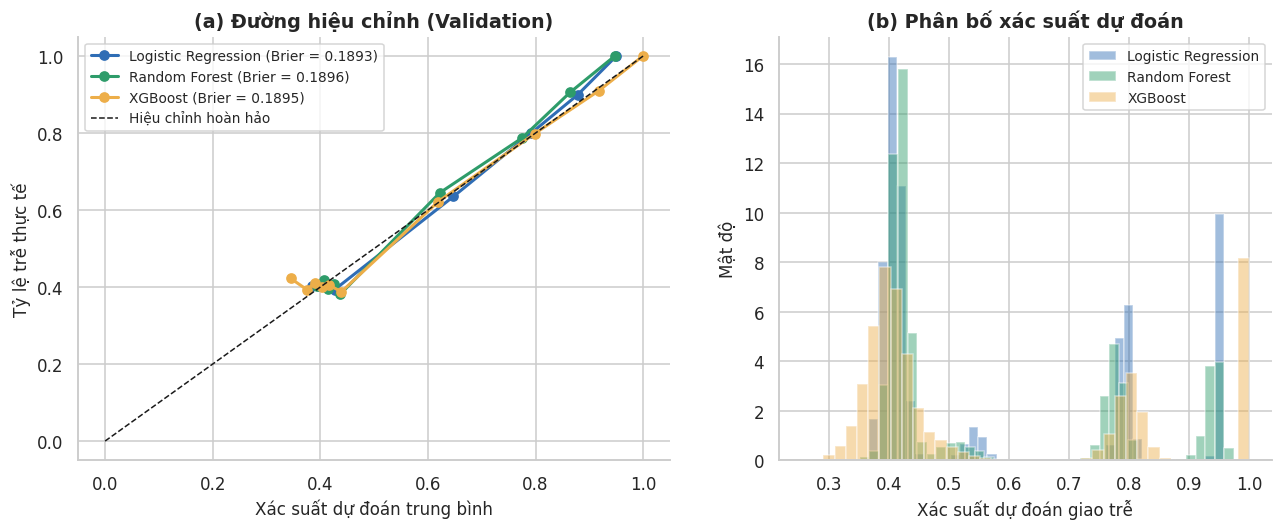

Hình 4.20. (a) Đường hiệu chỉnh xác suất của ba mô hình trên tập Validation (đường chéo đứt là hiệu chỉnh hoàn hảo); (b) phân bố xác suất dự đoán. Xác suất tập trung ở vài mức rời rạc vì dữ liệu chỉ có ít đặc trưng có sức phân biệt cao.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/20_hieu_chinh_xac_suat.png



In [ ]:
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
for n in MODEL_NAMES:
    fp, mp = calibration_curve(y_val, proba_val[n], n_bins=10, strategy="quantile")
    ax.plot(mp, fp, "o-", color=MODEL_COLORS[n], lw=2, label=f"{n} (Brier = {brier_score_loss(y_val, proba_val[n]):.4f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Hiệu chỉnh hoàn hảo")
ax.set_xlabel("Xác suất dự đoán trung bình"); ax.set_ylabel("Tỷ lệ trễ thực tế"); ax.set_title("(a) Đường hiệu chỉnh (Validation)"); ax.legend(loc="upper left", fontsize=9)
ax = axes[1]
for n in MODEL_NAMES:
    ax.hist(proba_val[n], bins=40, alpha=0.45, color=MODEL_COLORS[n], label=n, density=True)
ax.set_xlabel("Xác suất dự đoán giao trễ"); ax.set_ylabel("Mật độ"); ax.set_title("(b) Phân bố xác suất dự đoán"); ax.legend(fontsize=9)
save_fig(fig, "hieu_chinh_xac_suat",
         "(a) Đường hiệu chỉnh xác suất của ba mô hình trên tập Validation (đường chéo đứt là hiệu chỉnh hoàn hảo); "
         "(b) phân bố xác suất dự đoán. Xác suất tập trung ở vài mức rời rạc vì dữ liệu chỉ có ít đặc trưng có sức phân biệt cao.")

---
# PHẦN 15. ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST (CHỈ CHẠY MỘT LẦN)

Từ đây tập Test mới được sử dụng, và **không điều chỉnh gì thêm** sau khi xem kết quả (nếu chỉnh mô hình theo điểm Test thì Test không còn là tập kiểm tra độc lập).

- Mô hình: các mô hình tốt nhất ở Phần 13, huấn luyện trên **Train** (giữ nguyên để ngưỡng chọn ở Validation vẫn nhất quán).
- Ngưỡng: lấy từ Validation (`thr_opt`), **không chọn lại trên Test**.
- Khoảng tin cậy 95% của AUC: *bootstrap theo nhóm đơn hàng* (lấy mẫu lại cả đơn hàng chứ không lấy dòng lẻ), để tính đúng sự phụ thuộc giữa các dòng cùng đơn.

In [ ]:
proba_test = {n: best_est[n].predict_proba(X_test)[:, 1] for n in MODEL_NAMES}
test_05  = pd.DataFrame({n: evaluate(y_test, proba_test[n], 0.5) for n in MODEL_NAMES}).T
test_opt = pd.DataFrame({n: evaluate(y_test, proba_test[n], thr_opt[n]) for n in MODEL_NAMES}).T
test_opt.insert(0, "Ngưỡng (từ Validation)", pd.Series(thr_opt))

# Baseline trên Test để so sánh
base_test = {}
for name, p in baselines.items():
    base_test[name] = evaluate(y_test, p.predict_proba(X_test)[:, 1], 0.5)
base_test = pd.DataFrame(base_test).T

print("— TEST, ngưỡng 0,5 —");                            display(test_05.style.format("{:.4f}"))
print("— TEST, ngưỡng tối ưu chọn từ Validation —");     display(test_opt.style.format("{:.4f}"))
print("— TEST, mô hình cơ sở —");                        display(base_test.style.format("{:.4f}"))

# ---------- Bootstrap theo nhóm cho AUC ----------
def grouped_bootstrap_auc(y_true, probas, groups, n_boot=300, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    y_arr = y_true.values
    idx_by_group = list(pd.Series(np.arange(len(y_arr))).groupby(groups.values).indices.values())
    G = len(idx_by_group); res = {k: [] for k in probas}
    for _ in range(n_boot):
        ii = np.concatenate([idx_by_group[k] for k in rng.randint(0, G, G)])
        if len(np.unique(y_arr[ii])) < 2: continue
        for k, p in probas.items(): res[k].append(roc_auc_score(y_arr[ii], p[ii]))
    return {k: np.array(v) for k, v in res.items()}

boot = grouped_bootstrap_auc(y_test, proba_test, g_test)
ci_tbl = pd.DataFrame({n: {"AUC": roc_auc_score(y_test, proba_test[n]),
                           "CI 95% thấp": np.percentile(boot[n], 2.5), "CI 95% cao": np.percentile(boot[n], 97.5)} for n in MODEL_NAMES}).T
display(ci_tbl.style.format("{:.4f}"))
best_test = ci_tbl["AUC"].idxmax()
print(f"\nMô hình có AUC Test cao nhất: {best_test}. So sánh cặp (bootstrap, hiệu AUC so với {best_test}):")
for n in MODEL_NAMES:
    if n == best_test: continue
    diff = boot[best_test] - boot[n]
    print(f"  {best_test} − {n}: trung bình {diff.mean():+.4f}, KTC 95% [{np.percentile(diff, 2.5):+.4f}; {np.percentile(diff, 97.5):+.4f}] "
          f"→ {'khác biệt có ý nghĩa' if np.percentile(diff, 2.5) > 0 else 'CHƯA đủ bằng chứng khác biệt'}")

— TEST, ngưỡng 0,5 —


,ROC-AUC,PR-AUC,Accuracy,Balanced Acc,Precision,Recall,F1 (lớp trễ),Macro-F1,MCC,Brier,Log-loss
Logistic Regression,0.7301,0.8278,0.6943,0.7131,0.8334,0.5806,0.6844,0.6940,0.4310,0.1899,0.5485
Random Forest,0.7323,0.8283,0.6959,0.7169,0.8489,0.5683,0.6809,0.6952,0.4419,0.1902,0.5502
XGBoost,0.7326,0.8283,0.6968,0.7205,0.8676,0.5533,0.6757,0.6955,0.4536,0.1902,0.5424


— TEST, ngưỡng tối ưu chọn từ Validation —


,Ngưỡng (từ Validation),ROC-AUC,PR-AUC,Accuracy,Balanced Acc,Precision,Recall,F1 (lớp trễ),Macro-F1,MCC,Brier,Log-loss
Logistic Regression,0.7571,0.7301,0.8278,0.6960,0.7222,0.8848,0.5375,0.6687,0.6940,0.4622,0.1899,0.5485
Random Forest,0.5507,0.7323,0.8283,0.6960,0.7216,0.8801,0.5413,0.6703,0.6942,0.4595,0.1902,0.5502
XGBoost,0.5685,0.7326,0.8283,0.6967,0.7226,0.8834,0.5400,0.6703,0.6948,0.4623,0.1902,0.5424


— TEST, mô hình cơ sở —


,ROC-AUC,PR-AUC,Accuracy,Balanced Acc,Precision,Recall,F1 (lớp trễ),Macro-F1,MCC,Brier,Log-loss
Baseline 1: luôn đoán theo tỷ lệ chung (Dummy),0.5000,0.5708,0.5708,0.5000,0.5708,1.0000,0.7268,0.3634,0.0000,0.2450,0.6831
Baseline 2: Logistic chỉ với shipping_mode,0.7400,0.7816,0.6960,0.7222,0.8848,0.5375,0.6687,0.6940,0.4622,0.1887,0.5389


,AUC,CI 95% thấp,CI 95% cao
Logistic Regression,0.7301,0.7192,0.7419
Random Forest,0.7323,0.7220,0.7438
XGBoost,0.7326,0.7223,0.7437



Mô hình có AUC Test cao nhất: XGBoost. So sánh cặp (bootstrap, hiệu AUC so với XGBoost):
  XGBoost − Logistic Regression: trung bình +0.0026, KTC 95% [-0.0020; +0.0075] → CHƯA đủ bằng chứng khác biệt
  XGBoost − Random Forest: trung bình +0.0003, KTC 95% [-0.0040; +0.0049] → CHƯA đủ bằng chứng khác biệt


In [ ]:
print("Số dòng được dự đoán:", len(X_test))
print("Số đơn hàng khác nhau:", g_test.nunique())

Số dòng được dự đoán: 24631
Số đơn hàng khác nhau: 8985


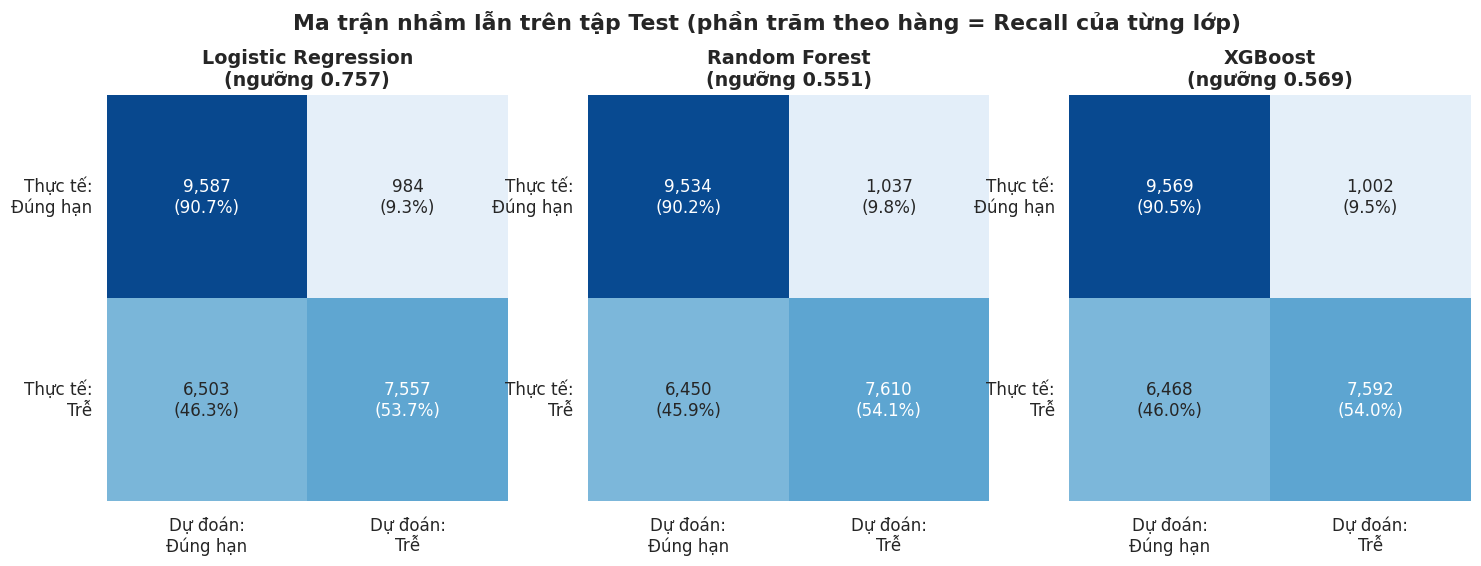

Hình 4.21. Ma trận nhầm lẫn của ba mô hình trên tập Test với ngưỡng chọn từ Validation. Mỗi ô ghi số dòng và tỷ lệ phần trăm theo hàng (đường chéo là Recall của từng lớp: ô dưới phải là tỷ lệ phát hiện đúng đơn trễ).
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/21_ma_tran_nham_lan_test.png



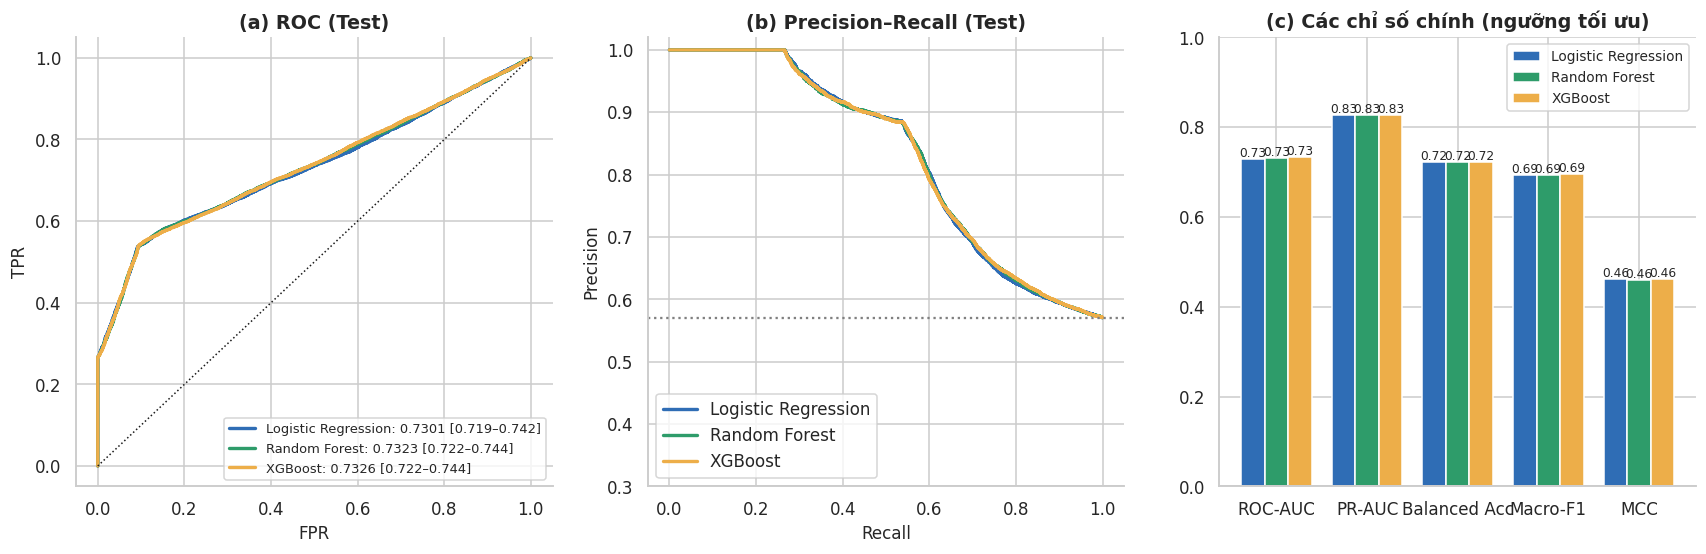

Hình 4.22. So sánh ba mô hình trên tập Test: (a) đường ROC kèm AUC và khoảng tin cậy 95% theo bootstrap theo nhóm đơn hàng; (b) đường Precision–Recall; (c) các chỉ số chính tại ngưỡng đã chọn từ Validation.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/22_so_sanh_mo_hinh_test.png



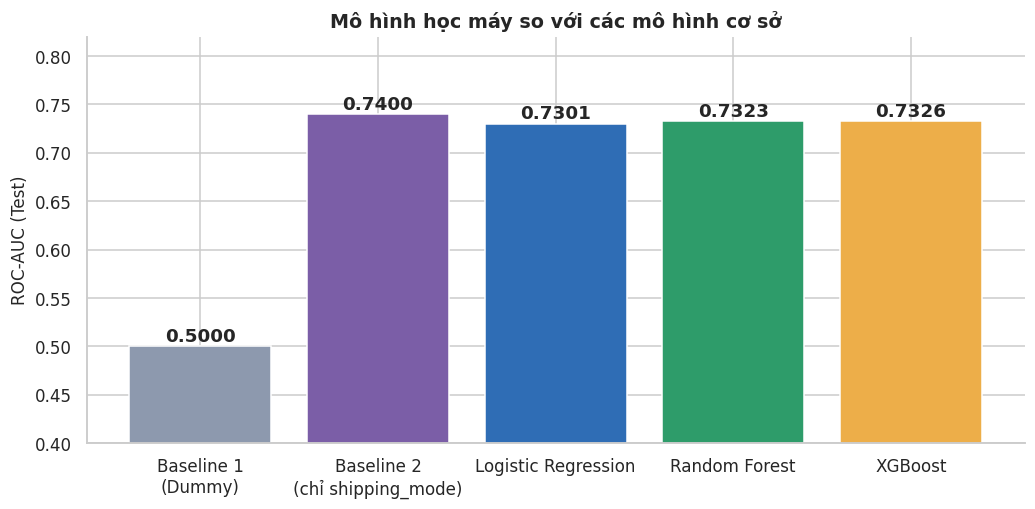

Hình 4.23. ROC-AUC trên tập Test của ba mô hình so với hai mô hình cơ sở. Khoảng cách giữa Baseline 2 (chỉ dùng phương thức vận chuyển) và các mô hình đầy đủ cho biết các đặc trưng còn lại đóng góp thêm bao nhiêu.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/23_so_sanh_voi_baseline.png



In [ ]:

# ---------- Hình: ma trận nhầm lẫn ----------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, n in zip(axes, MODEL_NAMES):
    pred = (proba_test[n] >= thr_opt[n]).astype(int)
    cm = confusion_matrix(y_test, pred)
    pct_row = cm / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f"{int(cm[i, j]):,}\n({pct_row[i, j]:.1f}%)" for j in range(2)] for i in range(2)])
    sns.heatmap(pct_row, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax, annot_kws={"size": 11})
    ax.set_xticklabels(["Dự đoán:\nĐúng hạn", "Dự đoán:\nTrễ"]); ax.set_yticklabels(["Thực tế:\nĐúng hạn", "Thực tế:\nTrễ"], rotation=0)
    ax.set_title(f"{n}\n(ngưỡng {thr_opt[n]:.3f})")
fig.suptitle("Ma trận nhầm lẫn trên tập Test (phần trăm theo hàng = Recall của từng lớp)", fontweight="bold", y=1.04)
save_fig(fig, "ma_tran_nham_lan_test",
         "Ma trận nhầm lẫn của ba mô hình trên tập Test với ngưỡng chọn từ Validation. Mỗi ô ghi số dòng và tỷ lệ phần trăm theo hàng "
         "(đường chéo là Recall của từng lớp: ô dưới phải là tỷ lệ phát hiện đúng đơn trễ).")

# ---------- Hình: ROC, PR, so sánh chỉ số ----------
fig, axes = plt.subplots(1, 3, figsize=(19, 5.3))
for n in MODEL_NAMES:
    fpr, tpr, _ = roc_curve(y_test, proba_test[n])
    axes[0].plot(fpr, tpr, lw=2.2, color=MODEL_COLORS[n], label=f"{n}: {ci_tbl.loc[n,'AUC']:.4f} [{ci_tbl.loc[n,'CI 95% thấp']:.3f}–{ci_tbl.loc[n,'CI 95% cao']:.3f}]")
    pr_, rc_, _ = precision_recall_curve(y_test, proba_test[n]); axes[1].plot(rc_, pr_, lw=2.2, color=MODEL_COLORS[n], label=f"{n}")
axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR"); axes[0].set_title("(a) ROC (Test)"); axes[0].legend(loc="lower right", fontsize=8.5)
axes[1].axhline(y_test.mean(), ls=":", c="grey"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("(b) Precision–Recall (Test)")
axes[1].legend(loc="lower left"); axes[1].set_ylim(0.3, 1.02)
metrics_show = ["ROC-AUC", "PR-AUC", "Balanced Acc", "Macro-F1", "MCC"]
x = np.arange(len(metrics_show)); wd = 0.26
for k, n in enumerate(MODEL_NAMES):
    vals = [test_opt.loc[n, m] for m in metrics_show]
    axes[2].bar(x + (k - 1) * wd, vals, wd, color=MODEL_COLORS[n], label=n)
    for xi, v in zip(x + (k - 1) * wd, vals): axes[2].text(xi, v + 0.005, f"{v:.2f}", ha="center", fontsize=8)
axes[2].set_xticks(x); axes[2].set_xticklabels(metrics_show); axes[2].set_ylim(0, 1.0); axes[2].set_title("(c) Các chỉ số chính (ngưỡng tối ưu)"); axes[2].legend(loc="upper right", fontsize=9)
save_fig(fig, "so_sanh_mo_hinh_test",
         "So sánh ba mô hình trên tập Test: (a) đường ROC kèm AUC và khoảng tin cậy 95% theo bootstrap theo nhóm đơn hàng; "
         "(b) đường Precision–Recall; (c) các chỉ số chính tại ngưỡng đã chọn từ Validation.")

# ---------- Hình: so sánh với mô hình cơ sở ----------
fig, ax = plt.subplots(figsize=(11, 4.8))
labels = ["Baseline 1\n(Dummy)", "Baseline 2\n(chỉ shipping_mode)"] + MODEL_NAMES
aucs = [base_test.iloc[0]["ROC-AUC"], base_test.iloc[1]["ROC-AUC"]] + [test_opt.loc[n, "ROC-AUC"] for n in MODEL_NAMES]
colors = [C_GREY, C_PURPLE] + [MODEL_COLORS[n] for n in MODEL_NAMES]
ax.bar(labels, aucs, color=colors)
for i, v in enumerate(aucs): ax.text(i, v + 0.005, f"{v:.4f}", ha="center", fontweight="bold")
ax.set_ylim(0.4, max(aucs) + 0.08); ax.set_ylabel("ROC-AUC (Test)"); ax.set_title("Mô hình học máy so với các mô hình cơ sở")
save_fig(fig, "so_sanh_voi_baseline",
         "ROC-AUC trên tập Test của ba mô hình so với hai mô hình cơ sở. Khoảng cách giữa Baseline 2 (chỉ dùng phương thức vận chuyển) "
         "và các mô hình đầy đủ cho biết các đặc trưng còn lại đóng góp thêm bao nhiêu.")

In [ ]:
# ---------- Báo cáo chi tiết cho mô hình tốt nhất + bảng điểm vận hành ----------
best_final = best_name   # mô hình chọn ở Validation (đã cố định trước khi nhìn Test)
print(f"MÔ HÌNH ĐƯỢC CHỌN (theo AUC Validation): {best_final}   | AUC Test = {ci_tbl.loc[best_final, 'AUC']:.4f}")
pred_best = (proba_test[best_final] >= thr_opt[best_final]).astype(int)
print(classification_report(y_test, pred_best, target_names=["Đúng hạn / Sớm", "Giao trễ"], digits=4))

# Điểm vận hành theo mục tiêu Recall: ngưỡng chọn trên Validation, đo trên Test
op_rows = []
pv, pt = proba_val[best_final], proba_test[best_final]
for target_recall in [0.70, 0.80, 0.90, 0.95]:
    pr_, rc_, th_ = precision_recall_curve(y_val, pv)
    ok = np.where(rc_[:-1] >= target_recall)[0]
    t = float(th_[ok[-1]]) if len(ok) else 0.0
    pred = (pt >= t).astype(int)
    op_rows.append({"Mục tiêu Recall": target_recall, "Ngưỡng (từ Val)": t, "Recall (Test)": recall_score(y_test, pred),
                    "Precision (Test)": precision_score(y_test, pred, zero_division=0), "% đơn bị cảnh báo": pred.mean() * 100})
op_tbl = pd.DataFrame(op_rows)
print("Điểm vận hành tham khảo cho doanh nghiệp (đánh đổi giữa phát hiện sớm đơn trễ và số cảnh báo sai):")
display(op_tbl.style.format({"Mục tiêu Recall": "{:.0%}", "Ngưỡng (từ Val)": "{:.3f}", "Recall (Test)": "{:.3f}", "Precision (Test)": "{:.3f}", "% đơn bị cảnh báo": "{:.1f}"}))

# Lưu bảng kết quả
val_05.to_csv(os.path.join(ART_DIR, "ket_qua_validation_nguong_0.5.csv"), encoding="utf-8-sig")
val_opt.to_csv(os.path.join(ART_DIR, "ket_qua_validation_nguong_toi_uu.csv"), encoding="utf-8-sig")
test_05.to_csv(os.path.join(ART_DIR, "ket_qua_test_nguong_0.5.csv"), encoding="utf-8-sig")
test_opt.to_csv(os.path.join(ART_DIR, "ket_qua_test_nguong_toi_uu.csv"), encoding="utf-8-sig")
ci_tbl.to_csv(os.path.join(ART_DIR, "ket_qua_test_auc_khoang_tin_cay.csv"), encoding="utf-8-sig")
op_tbl.to_csv(os.path.join(ART_DIR, "diem_van_hanh_theo_recall.csv"), index=False, encoding="utf-8-sig")

MÔ HÌNH ĐƯỢC CHỌN (theo AUC Validation): Logistic Regression   | AUC Test = 0.7301
                precision    recall  f1-score   support

Đúng hạn / Sớm     0.5958    0.9069    0.7192     10571
      Giao trễ     0.8848    0.5375    0.6687     14060

      accuracy                         0.6960     24631
     macro avg     0.7403    0.7222    0.6940     24631
  weighted avg     0.7608    0.6960    0.6904     24631

Điểm vận hành tham khảo cho doanh nghiệp (đánh đổi giữa phát hiện sớm đơn trễ và số cảnh báo sai):


,Mục tiêu Recall,Ngưỡng (từ Val),Recall (Test),Precision (Test),% đơn bị cảnh báo
0,70%,0.414,0.701,0.690,58.0
1,80%,0.406,0.799,0.626,72.8
2,90%,0.396,0.903,0.594,86.8
3,95%,0.390,0.950,0.582,93.2


### ĐÁNH GIÁ RỦI RO Ở CẤP ĐƠN HÀNG (ORDER-LEVEL AGGREGATION)
Đoạn mã dưới đây thực hiện gom các dự đoán ở cấp dòng sản phẩm (item-level) lên cấp đơn hàng (order-level) sử dụng luật rủi ro tối đa (MAX) và đánh giá lại hiệu năng của mô hình.

=== ĐÁNH GIÁ HIỆU NĂNG Ở CẤP ĐƠN HÀNG (ĐÃ GOM NHÓM từ 24,631 items về 8,985 đơn hàng) ===
ROC-AUC cấp Đơn hàng: 0.7338
              precision    recall  f1-score   support

    Đúng hạn       0.59      0.91      0.72      3812
         Trễ       0.89      0.54      0.67      5173

    accuracy                           0.70      8985
   macro avg       0.74      0.72      0.69      8985
weighted avg       0.76      0.70      0.69      8985



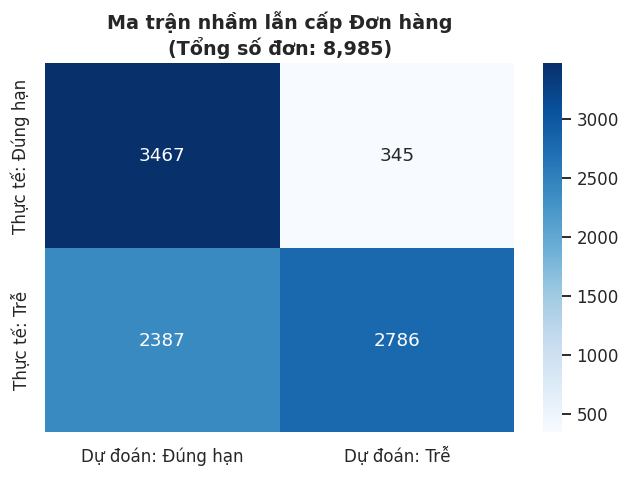

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tạo DataFrame kết quả cấp Item trên tập Test
test_items = pd.DataFrame({
    'order_id': g_test.values,
    'y_true_item': y_test.values,
    'y_proba_item': proba_test[best_final]
})

# 2. Gom nhóm theo order_id để lên cấp Đơn hàng (Order-level)
# Định nghĩa nghiệp vụ: Đơn hàng bị trễ thực tế nếu có ít nhất 1 item bị trễ (MAX)
# Xác suất trễ của đơn hàng bằng xác suất trễ lớn nhất của các item trong đơn (MAX)
test_orders = test_items.groupby('order_id').agg(
    y_true_order=('y_true_item', 'max'),
    y_proba_order=('y_proba_item', 'max'),
    num_items=('order_id', 'count')
).reset_index()

# 3. Áp dụng ngưỡng tối ưu đã chọn từ Validation để đưa ra dự đoán cuối cùng
thr_selected = thr_opt[best_final]
test_orders['y_pred_order'] = (test_orders['y_proba_order'] >= thr_selected).astype(int)

# 4. Đánh giá hiệu năng ở cấp đơn hàng
auc_order = roc_auc_score(test_orders['y_true_order'], test_orders['y_proba_order'])
print(f"=== ĐÁNH GIÁ HIỆU NĂNG Ở CẤP ĐƠN HÀNG (ĐÃ GOM NHÓM từ {len(test_items):,} items về {len(test_orders):,} đơn hàng) ===")
print(f"ROC-AUC cấp Đơn hàng: {auc_order:.4f}")
print(classification_report(test_orders['y_true_order'], test_orders['y_pred_order'], target_names=['Đúng hạn', 'Trễ']))

# 5. Vẽ ma trận nhầm lẫn cấp đơn hàng
cm_order = confusion_matrix(test_orders['y_true_order'], test_orders['y_pred_order'])
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm_order, annot=True, fmt='d', cmap='Blues', xticklabels=['Dự đoán: Đúng hạn', 'Dự đoán: Trễ'], yticklabels=['Thực tế: Đúng hạn', 'Thực tế: Trễ'])
plt.title(f"Ma trận nhầm lẫn cấp Đơn hàng\n(Tổng số đơn: {len(test_orders):,})")
plt.tight_layout()
plt.show()


---
# PHẦN 16. DIỄN GIẢI MÔ HÌNH

Mục tiêu của đề tài không chỉ là dự đoán mà còn **chỉ ra yếu tố nào ảnh hưởng đến giao trễ** để doanh nghiệp hành động. Dùng bốn góc nhìn bổ sung cho nhau:

| Kỹ thuật | Áp dụng cho | Cho biết | Hạn chế |
|---|---|---|---|
| Hệ số / Odds ratio | Logistic Regression | Chiều và độ lớn tác động của từng giá trị | Chỉ phản ánh quan hệ tuyến tính |
| Độ quan trọng nội tại (impurity / gain) | Random Forest, XGBoost | Biến nào được cây dùng nhiều để chia | Thiên lệch về biến có nhiều giá trị khác nhau |
| **Permutation Importance** | Mọi mô hình | AUC giảm bao nhiêu khi xáo trộn một biến | Bị chia nhỏ khi hai biến tương quan |
| **SHAP** | XGBoost | Đóng góp của từng biến vào *từng dự đoán* | Tốn thời gian tính, chỉ dùng mẫu |

Các biến One-Hot (ví dụ `shipping_mode_First Class`) được **gộp lại về biến gốc** (`shipping_mode`) khi tính độ quan trọng, để kết quả đọc được theo ngôn ngữ nghiệp vụ.

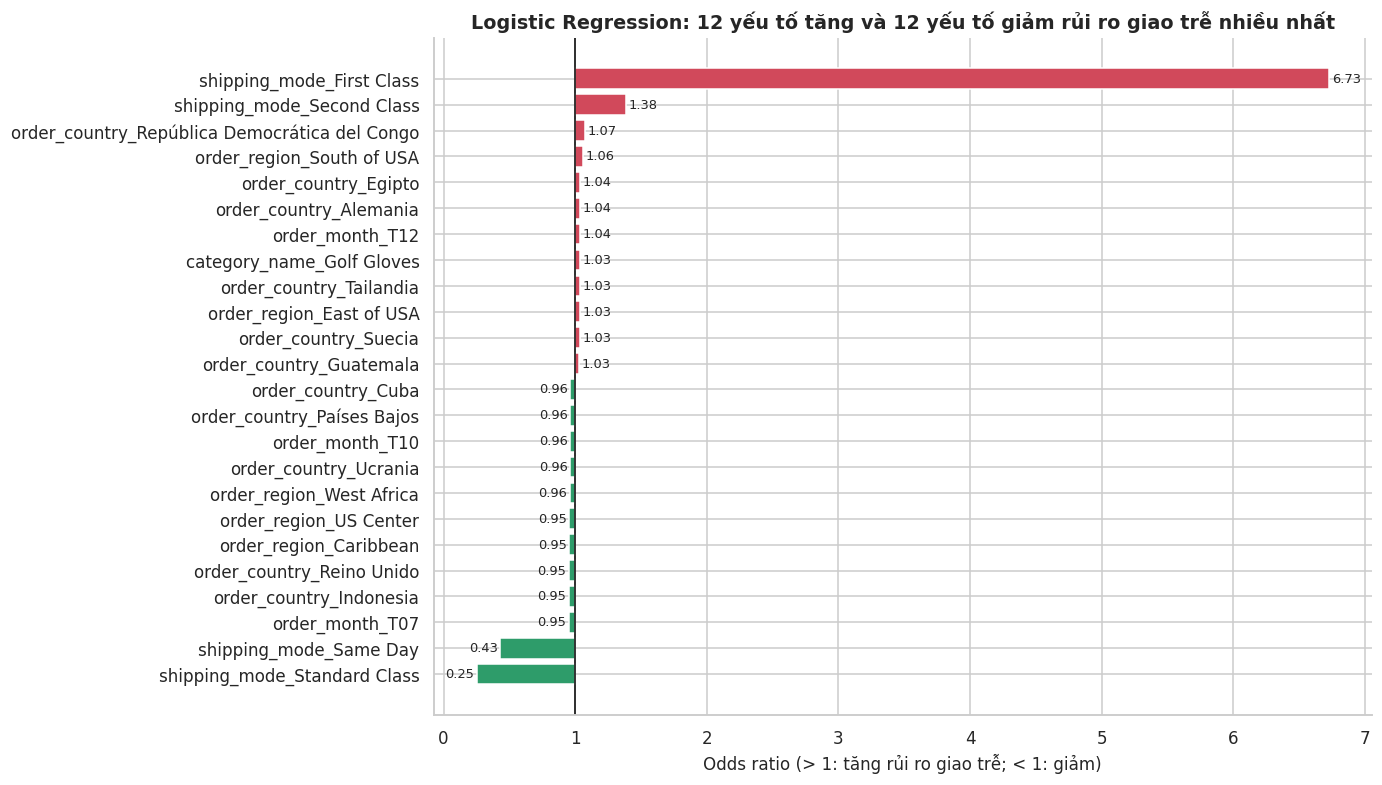

Hình 4.24. Odds ratio của Logistic Regression (đỏ: làm tăng rủi ro giao trễ, xanh: làm giảm). Biến số đã chuẩn hóa nên odds ratio của biến số tính cho mỗi 1 độ lệch chuẩn; với biến phân loại, odds ratio so với mức trung bình của biến đó (do mã hóa One-Hot đầy đủ có điều chuẩn L2).
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/24_logistic_odds_ratio.png



,hệ số,odds ratio
cat__shipping_mode_First Class,1.906,6.729
cat__shipping_mode_Second Class,0.326,1.385
cat__order_country_República Democrática del Congo,0.070,1.073
cat__order_region_South of USA,0.059,1.061
cat__order_country_Egipto,0.039,1.039
cat__order_country_Alemania,0.038,1.039


In [ ]:
def raw_feature_of(col_name):
    """Ánh xạ tên cột sau tiền xử lý về đặc trưng gốc."""
    body = col_name.split("__", 1)[1]
    if col_name.startswith("num__"):
        return body
    cands = [c for c in CAT_FEATURES if body.startswith(c + "_")]
    return max(cands, key=len) if cands else body

def get_names(pipe):
    return list(pipe.named_steps["prep"].get_feature_names_out())

# ---------- 16.1 Logistic Regression: hệ số và odds ratio ----------
lr_pipe = best_est["Logistic Regression"]
lr_names = get_names(lr_pipe)
coef = pd.Series(lr_pipe.named_steps["clf"].coef_[0], index=lr_names)
or_tbl = pd.DataFrame({"hệ số": coef, "odds ratio": np.exp(coef)})
or_tbl["đặc trưng gốc"] = [raw_feature_of(n) for n in or_tbl.index]
top_pos = or_tbl.sort_values("hệ số", ascending=False).head(12)
top_neg = or_tbl.sort_values("hệ số").head(12)
show = pd.concat([top_pos, top_neg]).drop_duplicates().sort_values("hệ số")

fig, ax = plt.subplots(figsize=(11, 8))
colors = [C_RED if c > 0 else C_GREEN for c in show["hệ số"]]
ax.barh([n.split("__", 1)[1] for n in show.index], show["odds ratio"] - 1, left=1, color=colors)
for i, (n, r_) in enumerate(zip(show.index, show["odds ratio"])):
    ax.text(r_ + (0.02 if r_ >= 1 else -0.02), i, f"{r_:.2f}", va="center", ha="left" if r_ >= 1 else "right", fontsize=8.5)
ax.axvline(1, c="black", lw=1)
ax.set_xlabel("Odds ratio (> 1: tăng rủi ro giao trễ; < 1: giảm)")
ax.set_title("Logistic Regression: 12 yếu tố tăng và 12 yếu tố giảm rủi ro giao trễ nhiều nhất")
save_fig(fig, "logistic_odds_ratio",
         "Odds ratio của Logistic Regression (đỏ: làm tăng rủi ro giao trễ, xanh: làm giảm). Biến số đã chuẩn hóa nên odds ratio của biến số "
         "tính cho mỗi 1 độ lệch chuẩn; với biến phân loại, odds ratio so với mức trung bình của biến đó (do mã hóa One-Hot đầy đủ có điều chuẩn L2).")
display(top_pos[["hệ số", "odds ratio"]].head(6).style.format("{:.3f}"))

Permutation importance Logistic Regression: 5s
Permutation importance Random Forest: 24s
Permutation importance XGBoost: 12s


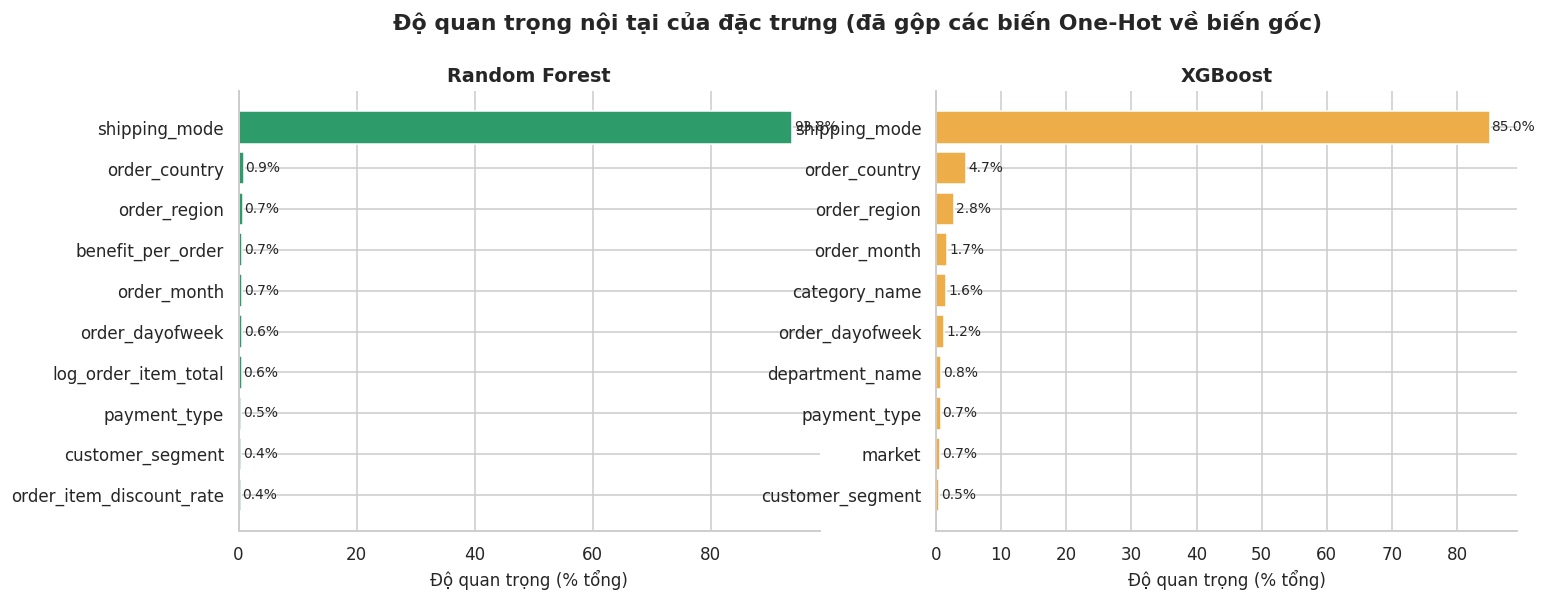

Hình 4.25. Độ quan trọng nội tại của đặc trưng trong Random Forest (giảm tạp chất) và XGBoost (gain), đã gộp các cột One-Hot về biến gốc. Chỉ mang tính tham khảo vì thiên lệch về biến có nhiều giá trị.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/25_do_quan_trong_noi_tai.png



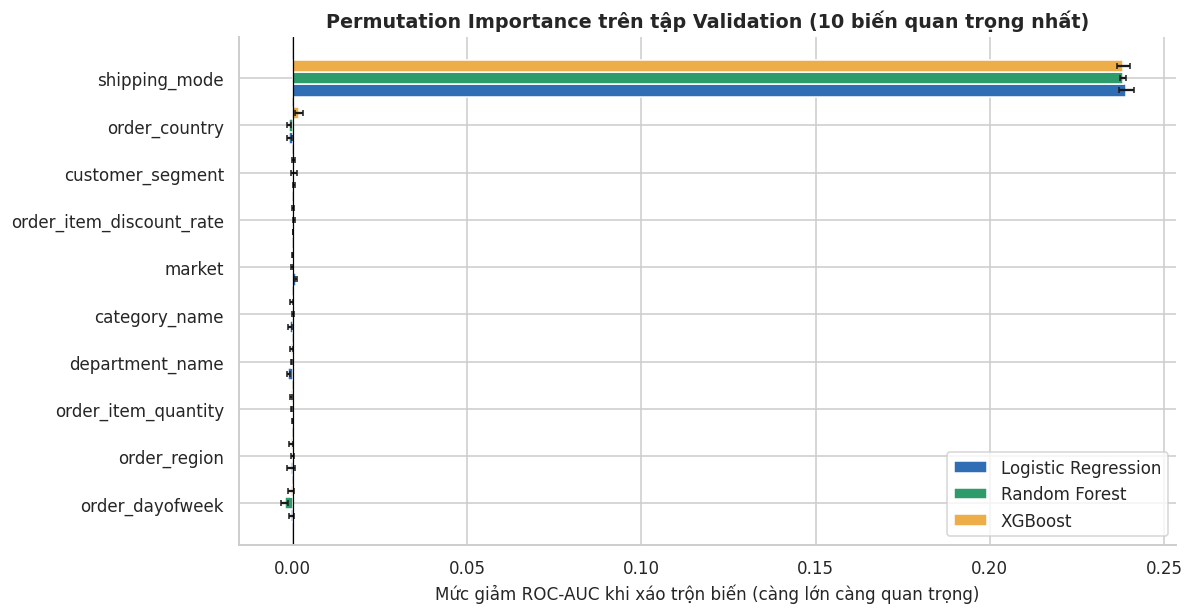

Hình 4.26. Permutation Importance của ba mô hình trên tập Validation: mức giảm ROC-AUC khi xáo trộn ngẫu nhiên từng đặc trưng (thanh sai số là độ lệch chuẩn qua 5 lần lặp). Biến nào làm AUC giảm nhiều nhất là biến mô hình dựa vào nhiều nhất.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/26_permutation_importance.png

Nhận xét tự động: biến quan trọng nhất theo Permutation Importance (XGBoost) là 'shipping_mode' (AUC giảm 0.2383).


In [ ]:
# ---------- 16.2 Độ quan trọng nội tại của Random Forest và XGBoost (gộp về đặc trưng gốc) ----------
def aggregated_importance(pipe):
    names = get_names(pipe)
    imp = pd.Series(pipe.named_steps["clf"].feature_importances_, index=names)
    return imp.groupby([raw_feature_of(n) for n in names]).sum().sort_values(ascending=False)

imp_rf  = aggregated_importance(best_est["Random Forest"])
imp_xgb = aggregated_importance(best_est["XGBoost"])

# ---------- 16.3 Permutation Importance (trên tập Validation, biến gốc) ----------
from sklearn.inspection import permutation_importance
rng = np.random.RandomState(RANDOM_STATE)
pi_idx = rng.choice(len(X_val), size=min(15_000, len(X_val)), replace=False)
Xpi, ypi = X_val.iloc[pi_idx], y_val.iloc[pi_idx]
perm = {}
for n in MODEL_NAMES:
    t0 = time.time()
    r = permutation_importance(best_est[n], Xpi, ypi, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
    perm[n] = pd.DataFrame({"mean": r.importances_mean, "std": r.importances_std}, index=X_val.columns)
    print(f"Permutation importance {n}: {time.time()-t0:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, imp, n in [(axes[0], imp_rf, "Random Forest"), (axes[1], imp_xgb, "XGBoost")]:
    t = (imp / imp.sum()).head(10).iloc[::-1]
    ax.barh(t.index, t.values * 100, color=MODEL_COLORS[n])
    for i, v in enumerate(t.values): ax.text(v * 100 + 0.3, i, f"{v*100:.1f}%", va="center", fontsize=9)
    ax.set_xlabel("Độ quan trọng (% tổng)"); ax.set_title(n)
fig.suptitle("Độ quan trọng nội tại của đặc trưng (đã gộp các biến One-Hot về biến gốc)", fontweight="bold", y=1.02)
save_fig(fig, "do_quan_trong_noi_tai",
         "Độ quan trọng nội tại của đặc trưng trong Random Forest (giảm tạp chất) và XGBoost (gain), đã gộp các cột One-Hot về biến gốc. "
         "Chỉ mang tính tham khảo vì thiên lệch về biến có nhiều giá trị.")

order = perm["XGBoost"]["mean"].sort_values(ascending=False).index[:10][::-1]
fig, ax = plt.subplots(figsize=(11, 6))
h = 0.26
for k, n in enumerate(MODEL_NAMES):
    ax.barh(np.arange(len(order)) + (k - 1) * h, perm[n].loc[order, "mean"], h, xerr=perm[n].loc[order, "std"], color=MODEL_COLORS[n], label=n, capsize=2)
ax.set_yticks(np.arange(len(order))); ax.set_yticklabels(order); ax.axvline(0, c="black", lw=0.8)
ax.set_xlabel("Mức giảm ROC-AUC khi xáo trộn biến (càng lớn càng quan trọng)"); ax.legend(loc="lower right")
ax.set_title("Permutation Importance trên tập Validation (10 biến quan trọng nhất)")
save_fig(fig, "permutation_importance",
         "Permutation Importance của ba mô hình trên tập Validation: mức giảm ROC-AUC khi xáo trộn ngẫu nhiên từng đặc trưng "
         "(thanh sai số là độ lệch chuẩn qua 5 lần lặp). Biến nào làm AUC giảm nhiều nhất là biến mô hình dựa vào nhiều nhất.")
top1 = perm["XGBoost"]["mean"].idxmax()
print(f"Nhận xét tự động: biến quan trọng nhất theo Permutation Importance (XGBoost) là '{top1}' "
      f"(AUC giảm {perm['XGBoost'].loc[top1,'mean']:.4f}).")

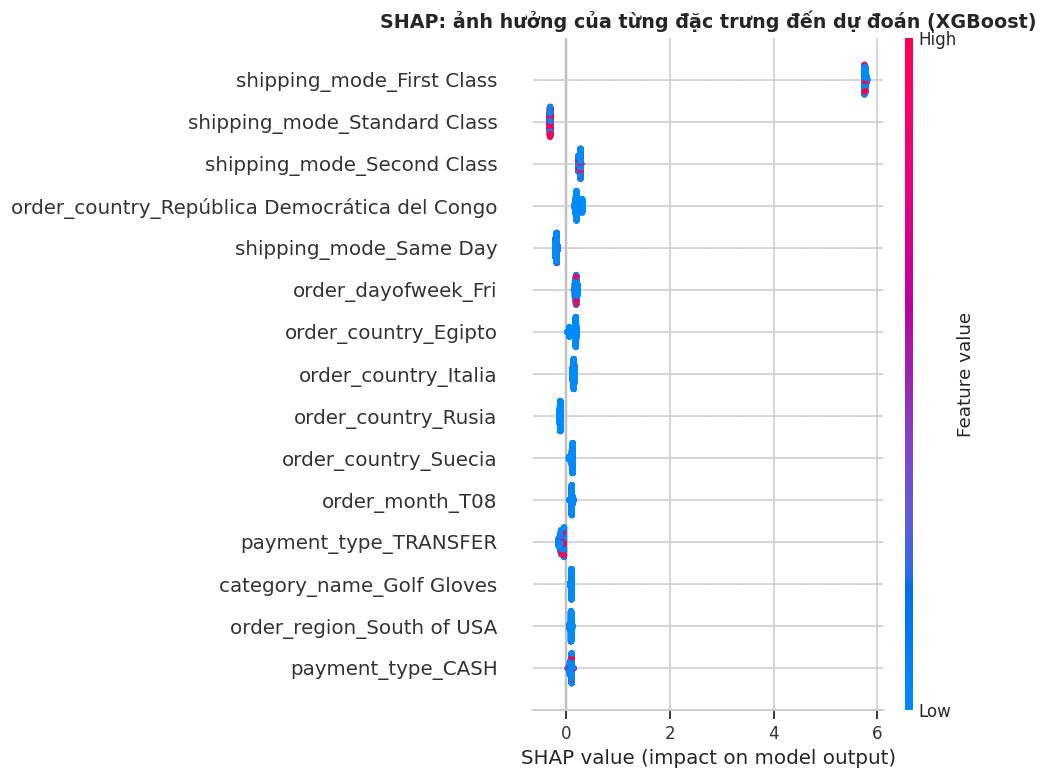

Hình 4.27. Biểu đồ SHAP (beeswarm) của XGBoost trên mẫu 2.000 dòng của tập Test: mỗi chấm là một dòng; vị trí ngang là mức đẩy dự đoán về phía giao trễ (phải) hoặc đúng hạn (trái); màu thể hiện giá trị của đặc trưng (đỏ: cao, xanh: thấp).
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/27_shap_beeswarm_xgboost.png



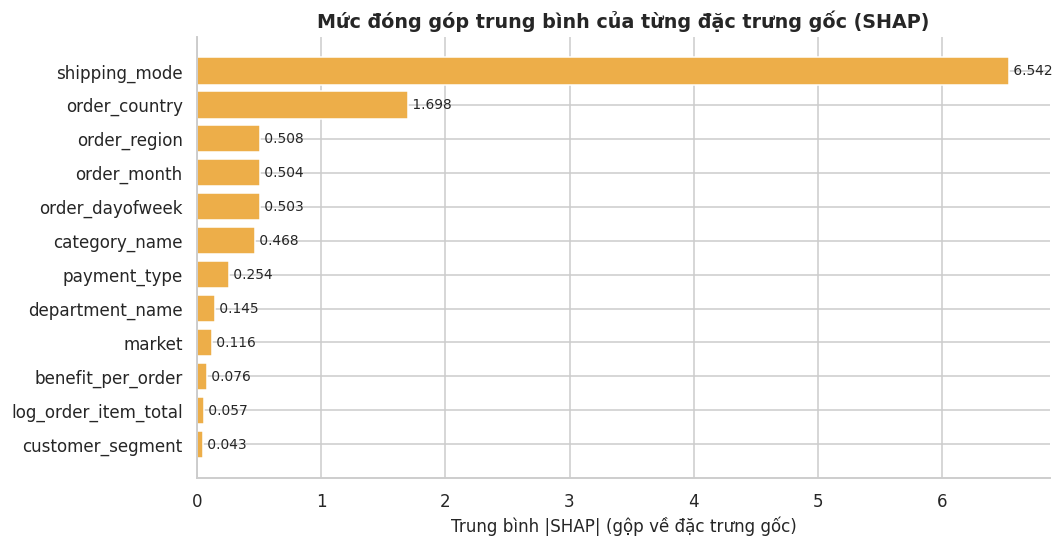

Hình 4.28. Mức đóng góp trung bình theo trị tuyệt đối SHAP của từng đặc trưng gốc (đã cộng gộp các cột One-Hot) trong mô hình XGBoost.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/28_shap_do_quan_trong_gop.png



In [ ]:
# ---------- 16.4 SHAP cho XGBoost ----------
try:
    import shap
    xgb_pipe = best_est["XGBoost"]
    prep_x, clf_x = xgb_pipe.named_steps["prep"], xgb_pipe.named_steps["clf"]
    shap_names = get_names(xgb_pipe)
    Xs = X_test.sample(n=min(2000, len(X_test)), random_state=RANDOM_STATE)
    Xs_t = prep_x.transform(Xs)
    Xs_t = Xs_t.toarray() if hasattr(Xs_t, "toarray") else np.asarray(Xs_t)
    sv = shap.TreeExplainer(clf_x).shap_values(Xs_t)
    sv = sv[1] if isinstance(sv, list) else sv

    plt.figure(figsize=(11, 7))
    shap.summary_plot(sv, Xs_t, feature_names=[n.split("__", 1)[1] for n in shap_names], max_display=15, show=False)
    fig = plt.gcf(); fig.set_size_inches(11, 7)
    plt.title("SHAP: ảnh hưởng của từng đặc trưng đến dự đoán (XGBoost)", fontweight="bold")
    save_fig(fig, "shap_beeswarm_xgboost",
             "Biểu đồ SHAP (beeswarm) của XGBoost trên mẫu 2.000 dòng của tập Test: mỗi chấm là một dòng; vị trí ngang là mức đẩy dự đoán "
             "về phía giao trễ (phải) hoặc đúng hạn (trái); màu thể hiện giá trị của đặc trưng (đỏ: cao, xanh: thấp).")

    mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=shap_names)
    agg = mean_abs.groupby([raw_feature_of(n) for n in shap_names]).sum().sort_values(ascending=True).tail(12)
    fig, ax = plt.subplots(figsize=(10, 5.2))
    ax.barh(agg.index, agg.values, color=C_ORANGE)
    for i, v in enumerate(agg.values): ax.text(v, i, f" {v:.3f}", va="center", fontsize=9)
    ax.set_xlabel("Trung bình |SHAP| (gộp về đặc trưng gốc)"); ax.set_title("Mức đóng góp trung bình của từng đặc trưng gốc (SHAP)")
    save_fig(fig, "shap_do_quan_trong_gop",
             "Mức đóng góp trung bình theo trị tuyệt đối SHAP của từng đặc trưng gốc (đã cộng gộp các cột One-Hot) trong mô hình XGBoost.")
except Exception as e:
    print("Không vẽ được biểu đồ SHAP:", repr(e))
    print("Các phần còn lại không bị ảnh hưởng; có thể bỏ qua cell này.")

---
# PHẦN 17. PHÂN TÍCH LỖI THEO NHÓM VÀ KIỂM TRA ĐỘ BỀN THEO THỜI GIAN

Chỉ số tổng thể có thể che giấu việc mô hình **hoạt động rất tệ ở một nhóm cụ thể**. Phần này đo chất lượng của mô hình được chọn trên từng nhóm phương thức vận chuyển, thị trường và ngành hàng (trên tập Test), rồi kiểm tra mô hình có còn tốt khi **dự đoán tương lai** (chia theo thời gian) hay không.

Mô hình phân tích: Logistic Regression (ngưỡng 0.757)

Theo phương thức vận chuyển


,shipping_mode,n,Tỷ lệ trễ thực tế,Tỷ lệ bị cảnh báo,AUC,Recall,Precision
0,Standard Class,"14,833",0.397,0.000,0.473,0.000,0.000
1,Second Class,"4,799",0.795,1.000,0.479,1.000,0.795
2,First Class,"3,742",1.000,1.000,nan,1.000,1.000
3,Same Day,"1,257",0.484,0.000,0.496,0.000,0.000


Theo thị trường


,market,n,Tỷ lệ trễ thực tế,Tỷ lệ bị cảnh báo,AUC,Recall,Precision
0,LATAM,"7,084",0.572,0.347,0.722,0.530,0.873
1,Europe,"6,697",0.584,0.345,0.735,0.534,0.903
2,Pacific Asia,"5,687",0.545,0.338,0.736,0.543,0.877
3,USCA,"3,493",0.589,0.360,0.716,0.546,0.894
4,Africa,"1,670",0.563,0.355,0.761,0.546,0.867


Theo ngành hàng


,department_name,n,Tỷ lệ trễ thực tế,Tỷ lệ bị cảnh báo,AUC,Recall,Precision
0,Fan Shop,"9,141",0.573,0.347,0.729,0.538,0.889
1,Apparel,"6,662",0.569,0.342,0.725,0.530,0.881
2,Golf,"4,524",0.566,0.351,0.739,0.547,0.884
3,Footwear,"2,003",0.582,0.350,0.726,0.533,0.887
4,Outdoors,"1,307",0.567,0.344,0.712,0.537,0.886
5,Fitness,342,0.556,0.348,0.746,0.547,0.874


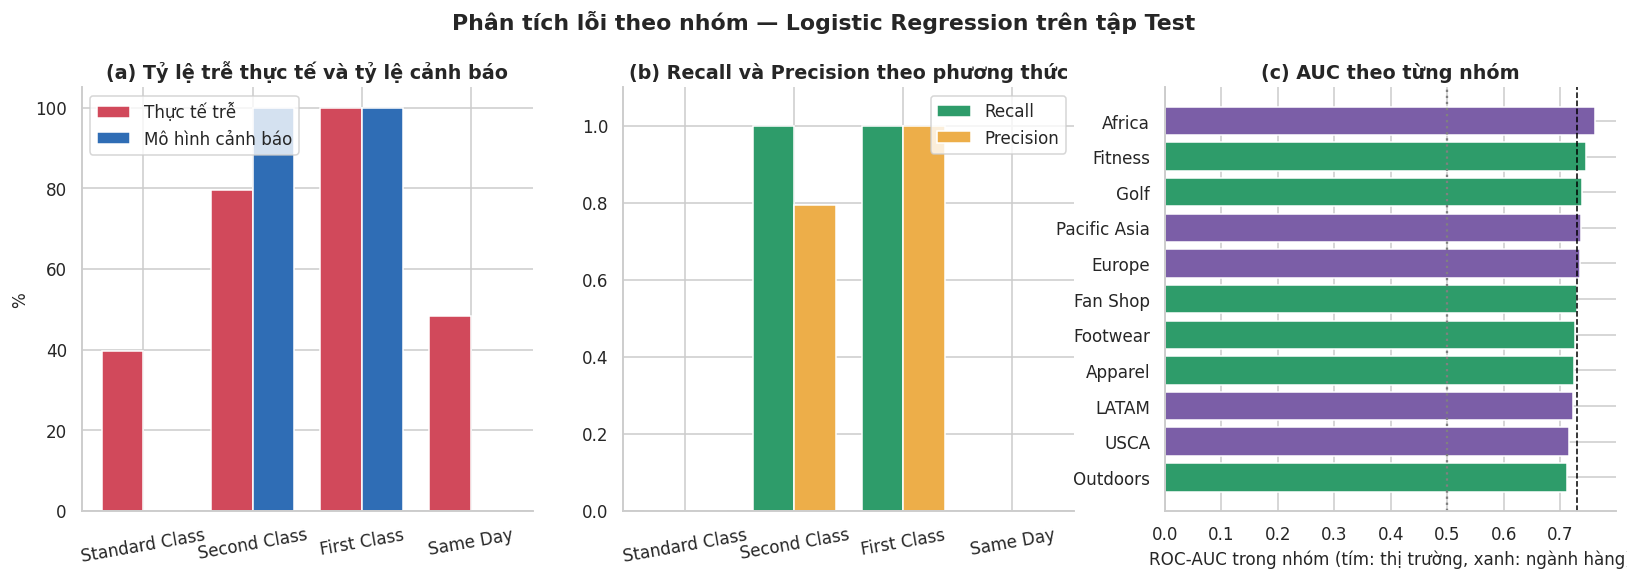

Hình 4.29. Phân tích lỗi của mô hình Logistic Regression trên tập Test: (a) tỷ lệ trễ thực tế so với tỷ lệ mô hình cảnh báo theo phương thức vận chuyển; (b) Recall và Precision theo phương thức; (c) AUC trong từng thị trường và ngành hàng (đường đứt đen: AUC chung). AUC thấp trong nhóm cho thấy trong nhóm đó mô hình khó phân biệt thêm ngoài phương thức vận chuyển.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/29_phan_tich_loi_theo_nhom.png



In [ ]:
test_df = df_model.iloc[test_idx].copy().reset_index(drop=True)
test_df["proba"] = proba_test[best_final]
test_df["pred"]  = (test_df["proba"] >= thr_opt[best_final]).astype(int)

def group_report(col, min_n=300):
    rows = []
    for k, g in test_df.groupby(col):
        if len(g) < min_n: continue
        y_g = g[TARGET]
        both = y_g.nunique() == 2
        rows.append({col: k, "n": len(g), "Tỷ lệ trễ thực tế": y_g.mean(), "Tỷ lệ bị cảnh báo": g["pred"].mean(),
                     "AUC": roc_auc_score(y_g, g["proba"]) if both else np.nan,
                     "Recall": recall_score(y_g, g["pred"], zero_division=0), "Precision": precision_score(y_g, g["pred"], zero_division=0)})
    return pd.DataFrame(rows).sort_values("n", ascending=False).reset_index(drop=True)

rep_mode, rep_market, rep_dep = group_report("shipping_mode"), group_report("market"), group_report("department_name")
print(f"Mô hình phân tích: {best_final} (ngưỡng {thr_opt[best_final]:.3f})\n")
for nm, r_ in [("Theo phương thức vận chuyển", rep_mode), ("Theo thị trường", rep_market), ("Theo ngành hàng", rep_dep)]:
    print(nm); display(r_.style.format({"n": "{:,}", "Tỷ lệ trễ thực tế": "{:.3f}", "Tỷ lệ bị cảnh báo": "{:.3f}", "AUC": "{:.3f}", "Recall": "{:.3f}", "Precision": "{:.3f}"}))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
x = np.arange(len(rep_mode)); wd = 0.38
axes[0].bar(x - wd/2, rep_mode["Tỷ lệ trễ thực tế"] * 100, wd, color=C_RED, label="Thực tế trễ")
axes[0].bar(x + wd/2, rep_mode["Tỷ lệ bị cảnh báo"] * 100, wd, color=C_BLUE, label="Mô hình cảnh báo")
axes[0].set_xticks(x); axes[0].set_xticklabels(rep_mode["shipping_mode"], rotation=10); axes[0].set_ylabel("%"); axes[0].legend(); axes[0].set_title("(a) Tỷ lệ trễ thực tế và tỷ lệ cảnh báo")
axes[1].bar(x - wd/2, rep_mode["Recall"], wd, color=C_GREEN, label="Recall"); axes[1].bar(x + wd/2, rep_mode["Precision"], wd, color=C_ORANGE, label="Precision")
axes[1].set_xticks(x); axes[1].set_xticklabels(rep_mode["shipping_mode"], rotation=10); axes[1].set_ylim(0, 1.1); axes[1].legend(); axes[1].set_title("(b) Recall và Precision theo phương thức")
auc_df = pd.concat([rep_market.assign(nhom="Thị trường").rename(columns={"market": "ten"}),
                    rep_dep.assign(nhom="Ngành hàng").rename(columns={"department_name": "ten"})]).dropna(subset=["AUC"]).sort_values("AUC")
axes[2].barh(auc_df["ten"], auc_df["AUC"], color=[C_PURPLE if g == "Thị trường" else C_GREEN for g in auc_df["nhom"]])
axes[2].axvline(0.5, c="grey", ls=":"); axes[2].axvline(roc_auc_score(y_test, proba_test[best_final]), c="black", ls="--", lw=1)
axes[2].set_xlabel("ROC-AUC trong nhóm (tím: thị trường, xanh: ngành hàng)"); axes[2].set_title("(c) AUC theo từng nhóm")
fig.suptitle(f"Phân tích lỗi theo nhóm — {best_final} trên tập Test", fontweight="bold", y=1.02)
save_fig(fig, "phan_tich_loi_theo_nhom",
         f"Phân tích lỗi của mô hình {best_final} trên tập Test: (a) tỷ lệ trễ thực tế so với tỷ lệ mô hình cảnh báo theo phương thức vận chuyển; "
         "(b) Recall và Precision theo phương thức; (c) AUC trong từng thị trường và ngành hàng (đường đứt đen: AUC chung). "
         "AUC thấp trong nhóm cho thấy trong nhóm đó mô hình khó phân biệt thêm ngoài phương thức vận chuyển.")

Huấn luyện: đặt hàng trước 2017-01-01 (119,880 dòng) | Kiểm tra: từ 2017-01-01 (52,885 dòng) | đơn vắt qua mốc bị loại: 0


,AUC chia theo nhóm đơn hàng (Test),AUC chia theo thời gian (2015–2016 → 2017–01/2018)
Logistic Regression,0.7301,0.7411
Random Forest,0.7323,0.7423
XGBoost,0.7326,0.7388


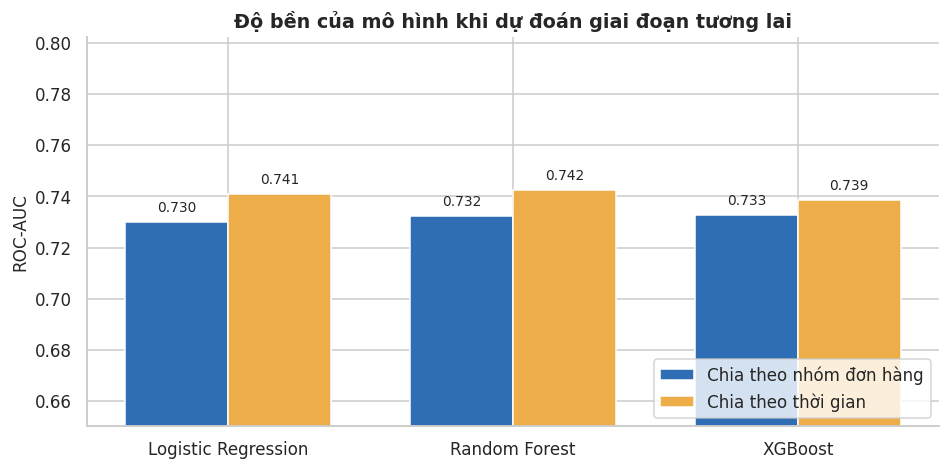

Hình 4.30. So sánh ROC-AUC khi chia dữ liệu theo nhóm đơn hàng với khi chia theo thời gian (huấn luyện 2015–2016, kiểm tra 2017–01/2018). AUC gần như không đổi chứng tỏ mô hình ổn định, không phụ thuộc vào việc dữ liệu kiểm tra nằm trong cùng giai đoạn với dữ liệu huấn luyện.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/30_do_ben_theo_thoi_gian.png



In [ ]:
# ---------- Kiểm tra độ bền theo thời gian: huấn luyện trên quá khứ, dự đoán tương lai ----------
cut = pd.Timestamp("2017-01-01")
od = df_model["order_date"]
tr_mask = (od < cut).to_numpy().copy()
te_mask = (od >= cut).to_numpy().copy()
overlap = set(g_all[tr_mask]) & set(g_all[te_mask])          # đơn hàng nằm vắt qua mốc thời gian (nếu có)
te_mask = te_mask & ~g_all.isin(overlap).to_numpy()
print(f"Huấn luyện: đặt hàng trước {cut.date()} ({tr_mask.sum():,} dòng) | Kiểm tra: từ {cut.date()} ({te_mask.sum():,} dòng) | đơn vắt qua mốc bị loại: {len(overlap)}")

time_res = {}
for n in MODEL_NAMES:
    p = clone(best_est[n]).fit(X_all[tr_mask], y_all[tr_mask])
    time_res[n] = roc_auc_score(y_all[te_mask], p.predict_proba(X_all[te_mask])[:, 1])
cmp_time = pd.DataFrame({"AUC chia theo nhóm đơn hàng (Test)": {n: roc_auc_score(y_test, proba_test[n]) for n in MODEL_NAMES},
                         "AUC chia theo thời gian (2015–2016 → 2017–01/2018)": time_res})
display(cmp_time.style.format("{:.4f}"))

fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(MODEL_NAMES)); wd = 0.36
ax.bar(x - wd/2, cmp_time.iloc[:, 0], wd, color=C_BLUE, label="Chia theo nhóm đơn hàng")
ax.bar(x + wd/2, cmp_time.iloc[:, 1], wd, color=C_ORANGE, label="Chia theo thời gian")
for i, (a, b) in enumerate(zip(cmp_time.iloc[:, 0], cmp_time.iloc[:, 1])):
    ax.text(i - wd/2, a + 0.004, f"{a:.3f}", ha="center", fontsize=9); ax.text(i + wd/2, b + 0.004, f"{b:.3f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(MODEL_NAMES); ax.set_ylabel("ROC-AUC")
ax.set_ylim(max(0.4, cmp_time.values.min() - 0.08), min(1.0, cmp_time.values.max() + 0.06)); ax.legend(loc="lower right")
ax.set_title("Độ bền của mô hình khi dự đoán giai đoạn tương lai")
save_fig(fig, "do_ben_theo_thoi_gian",
         "So sánh ROC-AUC khi chia dữ liệu theo nhóm đơn hàng với khi chia theo thời gian (huấn luyện 2015–2016, kiểm tra 2017–01/2018). "
         "AUC gần như không đổi chứng tỏ mô hình ổn định, không phụ thuộc vào việc dữ liệu kiểm tra nằm trong cùng giai đoạn với dữ liệu huấn luyện.")

### Thực hiện ghi ngược kết quả dự đoán lên BigQuery để truy vấn đối soát

In [ ]:
# Ghi BigQuery chỉ khi người chạy bật WRITE_BACK_TO_BQ.
if WRITE_BACK_TO_BQ:
    # Thiết lập kích hoạt ghi ngược và chạy tiến trình ghi dữ liệu lên BigQuery
    scored = df_model[["order_item_id", "order_id"]].copy()
    split_label = np.empty(len(df_model), dtype=object)
    split_label[train_idx], split_label[val_idx], split_label[test_idx] = "train", "validation", "test"
    scored["tap_du_lieu"] = split_label
    scored["xac_suat_tre"] = best_est[best_final].predict_proba(X_all)[:, 1]
    scored["du_doan_tre"] = (scored["xac_suat_tre"] >= thr_opt[best_final]).astype(int)
    scored["mo_hinh"] = best_final
    scored["thoi_diem_cham_diem"] = pd.Timestamp.utcnow()
    
    dest = f"{PROJECT_ID}.gold.ml_late_delivery_predictions"
    job = client.load_table_from_dataframe(scored, dest, job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE"))
    job.result()
    print(f"✔ Đã ghi thành công {client.get_table(dest).num_rows:,} dòng vào bảng: {dest}")
else:
    print("Bỏ qua ghi BigQuery: WRITE_BACK_TO_BQ = False.")


✔ Đã ghi thành công 172,765 dòng vào bảng: warehouse-512516.gold.ml_late_delivery_predictions


### Đoạn mã SQL dùng để truy vấn kiểm tra trên BigQuery Console

Bạn có thể sao chép đoạn SQL dưới đây để chạy thử nghiệm ngay trên BigQuery Console giúp phân tích độ lệch dự đoán:

In [ ]:
sql_check_query = f"""
SELECT
  tap_du_lieu,
  COUNT(*) AS tong_so_dong,
  ROUND(AVG(xac_suat_tre) * 100, 2) AS xac_suat_tre_trung_binh_pct,
  ROUND(AVG(du_doan_tre) * 100, 2) AS ty_le_du_doan_tre_pct
FROM `{PROJECT_ID}.gold.ml_late_delivery_predictions`
GROUP BY tap_du_lieu
ORDER BY tap_du_lieu;
"""
print("--- ĐOẠN TRUY VẤN SQL KIỂM TRA TRÊN BIGQUERY CONSOLE ---")
print(sql_check_query)

# Chạy thử trực tiếp trong Colab để hiển thị kết quả đối soát nhanh
if WRITE_BACK_TO_BQ:
    df_bq_check = run_query(sql_check_query)
    display(df_bq_check)
else:
    print("Chỉ in SQL đối soát; chưa bật ghi/đọc bảng dự đoán BigQuery.")

--- ĐOẠN TRUY VẤN SQL KIỂM TRA TRÊN BIGQUERY CONSOLE ---

SELECT
  tap_du_lieu,
  COUNT(*) AS tong_so_dong,
  ROUND(AVG(xac_suat_tre) * 100, 2) AS xac_suat_tre_trung_binh_pct,
  ROUND(AVG(du_doan_tre) * 100, 2) AS ty_le_du_doan_tre_pct
FROM `warehouse-512516.gold.ml_late_delivery_predictions`
GROUP BY tap_du_lieu
ORDER BY tap_du_lieu;



,tap_du_lieu,tong_so_dong,xac_suat_tre_trung_binh_pct,ty_le_du_doan_tre_pct
0,test,24631,57.08,34.68
1,train,123399,57.29,35.03
2,validation,24735,57.05,34.55


---
# PHẦN 18. PHÂN TÍCH CẢI THIỆN MÔ HÌNH VÀ THÍ NGHIỆM ĐỐI CHỨNG

## 18.1. Tóm tắt các bước cải thiện đã thực hiện

| Bước cải thiện | Phần | Mục đích |
|---|---|---|
| Loại biến rò rỉ, trùng lặp, định danh | 7 | Mô hình có giá trị thực tế, giảm nhiễu |
| Log-transform doanh thu, chuẩn hóa (Logistic) | 7, 10 | Giảm lệch phải, ổn định tối ưu hóa |
| Gộp giá trị hiếm khi One-Hot | 10 | Giảm chiều, chống overfit |
| Tinh chỉnh siêu tham số bằng CV theo nhóm | 13 | Cân bằng thiên lệch – phương sai |
| Chọn ngưỡng quyết định tối ưu | 14 | Cân bằng hai loại sai lầm |

Bảng dưới đo mức cải thiện AUC trên Validation từ baseline → cấu hình ban đầu → cấu hình đã tinh chỉnh.

In [ ]:
imp_tbl = pd.DataFrame({
    "Baseline (chỉ shipping_mode)": roc_auc_score(y_val, proba_base),
    "Cấu hình ban đầu": {n: base_tbl.loc[n, "AUC Validation"] for n in MODEL_NAMES},
    "Sau tinh chỉnh": {n: roc_auc_score(y_val, proba_val[n]) for n in MODEL_NAMES},
})
imp_tbl["Cải thiện do tinh chỉnh"] = imp_tbl["Sau tinh chỉnh"] - imp_tbl["Cấu hình ban đầu"]
imp_tbl["Cải thiện so với baseline"] = imp_tbl["Sau tinh chỉnh"] - imp_tbl["Baseline (chỉ shipping_mode)"]
display(imp_tbl.style.format("{:+.4f}", subset=["Cải thiện do tinh chỉnh", "Cải thiện so với baseline"]).format("{:.4f}", subset=["Baseline (chỉ shipping_mode)", "Cấu hình ban đầu", "Sau tinh chỉnh"]))
imp_tbl.to_csv(os.path.join(ART_DIR, "cai_thien_mo_hinh.csv"), encoding="utf-8-sig")

,Baseline (chỉ shipping_mode),Cấu hình ban đầu,Sau tinh chỉnh,Cải thiện do tinh chỉnh,Cải thiện so với baseline
Logistic Regression,0.7400,0.7376,0.7378,+0.0002,-0.0023
Random Forest,0.7400,0.7361,0.7363,+0.0002,-0.0038
XGBoost,0.7400,0.7391,0.7360,-0.0032,-0.0041


## 18.2. Phân tích đóng góp của từng nhóm đặc trưng (ablation)

Hai cách đo trên XGBoost (cấu hình đã tinh chỉnh), đánh giá trên Validation:

- **Bỏ một nhóm**: AUC giảm bao nhiêu khi mất nhóm đó (giảm nhiều ⇒ nhóm quan trọng).
- **Chỉ dùng một nhóm**: nhóm đó tự giải thích được bao nhiêu AUC.

Kết quả giúp **bảo vệ danh sách đặc trưng** trong báo cáo: nhóm nào thực sự đóng góp, nhóm nào chỉ làm tăng độ phức tạp.

,Nhóm,AUC khi BỎ nhóm,AUC khi CHỈ dùng nhóm,Giảm AUC khi bỏ nhóm
0,Phương thức vận chuyển,0.4999,0.7400,+0.2361
1,Địa lý,0.7365,0.5071,-0.0006
2,Sản phẩm,0.7371,0.4982,-0.0011
3,Khách hàng & thanh toán,0.7379,0.4967,-0.0020
4,Thời gian,0.7382,0.4944,-0.0022
5,Tài chính,0.7377,0.4982,-0.0017


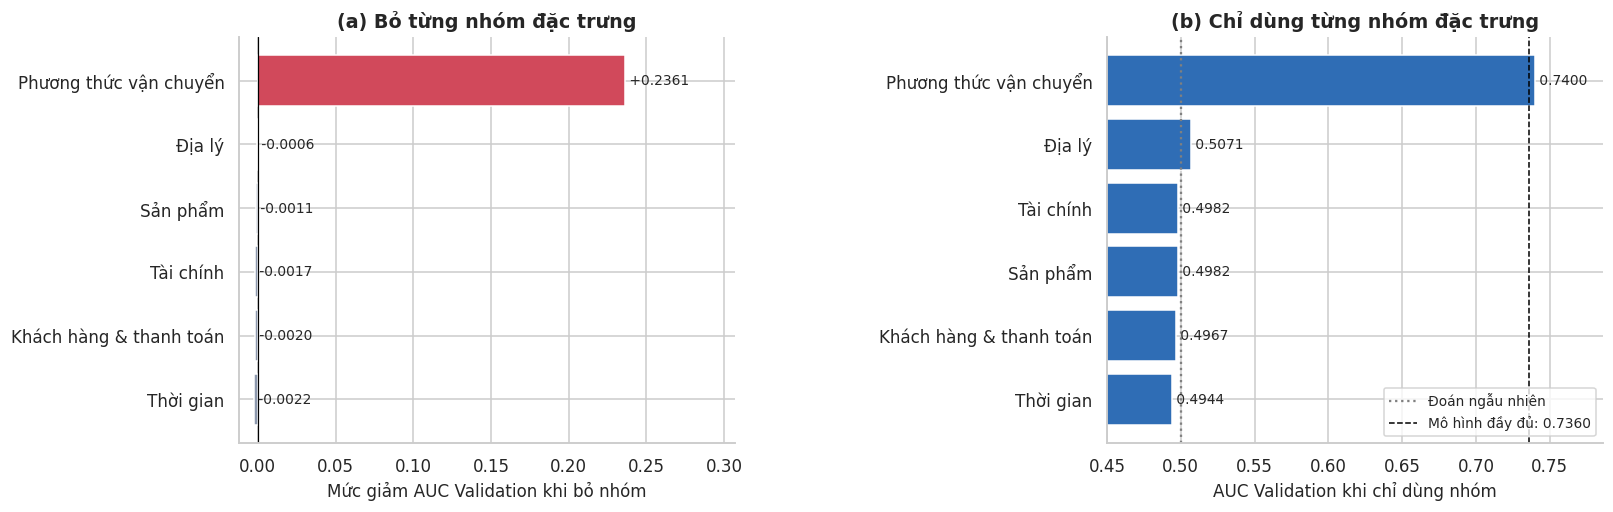

Hình 4.31. Phân tích đóng góp của từng nhóm đặc trưng trong XGBoost trên tập Validation: (a) mức giảm AUC khi bỏ từng nhóm (đỏ: nhóm đóng góp đáng kể); (b) AUC khi chỉ dùng riêng từng nhóm so với mô hình đầy đủ (đường đứt đen).
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/31_ablation_nhom_dac_trung.png



In [ ]:
groups_def = {
    "Phương thức vận chuyển": (["shipping_mode"], []),
    "Địa lý":                 (["market", "order_region", "order_country"], []),
    "Sản phẩm":               (["category_name", "department_name"], []),
    "Khách hàng & thanh toán": (["customer_segment", "payment_type"], []),
    "Thời gian":              (["order_month", "order_dayofweek"], []),
    "Tài chính":              ([], list(NUM_FEATURES)),
}
xgb_params = best_est["XGBoost"].named_steps["clf"]

def fit_eval_xgb(cats, nums):
    p = Pipeline([("prep", make_preprocessor(cats, nums, False)), ("clf", clone(xgb_params))])
    p.fit(X_train[cats + nums], y_train)
    return roc_auc_score(y_val, p.predict_proba(X_val[cats + nums])[:, 1])

full_auc = roc_auc_score(y_val, proba_val["XGBoost"])
abl = []
for gname, (gc, gn) in groups_def.items():
    cats_wo = [c for c in CAT_FEATURES if c not in gc]; nums_wo = [c for c in NUM_FEATURES if c not in gn]
    abl.append({"Nhóm": gname, "AUC khi BỎ nhóm": fit_eval_xgb(cats_wo, nums_wo), "AUC khi CHỈ dùng nhóm": fit_eval_xgb(gc, gn)})
abl = pd.DataFrame(abl)
abl["Giảm AUC khi bỏ nhóm"] = full_auc - abl["AUC khi BỎ nhóm"]
display(abl.style.format({"AUC khi BỎ nhóm": "{:.4f}", "AUC khi CHỈ dùng nhóm": "{:.4f}", "Giảm AUC khi bỏ nhóm": "{:+.4f}"}))
abl.to_csv(os.path.join(ART_DIR, "ablation_nhom_dac_trung.csv"), index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
fig.subplots_adjust(wspace=0.75)
a = abl.sort_values("Giảm AUC khi bỏ nhóm")
axes[0].barh(a["Nhóm"], a["Giảm AUC khi bỏ nhóm"], color=[C_RED if v > 0.002 else C_GREY for v in a["Giảm AUC khi bỏ nhóm"]])
for i, v in enumerate(a["Giảm AUC khi bỏ nhóm"]): axes[0].text(v, i, f" {v:+.4f}", va="center", fontsize=9)
axes[0].axvline(0, c="black", lw=0.8); axes[0].set_xlim(min(0, a["Giảm AUC khi bỏ nhóm"].min()) - 0.01, max(0.02, a["Giảm AUC khi bỏ nhóm"].max()) * 1.3)
axes[0].set_xlabel("Mức giảm AUC Validation khi bỏ nhóm"); axes[0].set_title("(a) Bỏ từng nhóm đặc trưng")
a = abl.sort_values("AUC khi CHỈ dùng nhóm")
axes[1].barh(a["Nhóm"], a["AUC khi CHỈ dùng nhóm"], color=C_BLUE)
for i, v in enumerate(a["AUC khi CHỈ dùng nhóm"]): axes[1].text(v, i, f" {v:.4f}", va="center", fontsize=9)
axes[1].axvline(0.5, c="grey", ls=":", label="Đoán ngẫu nhiên"); axes[1].axvline(full_auc, c="black", ls="--", lw=1, label=f"Mô hình đầy đủ: {full_auc:.4f}")
axes[1].set_xlim(0.45, full_auc + 0.05); axes[1].set_xlabel("AUC Validation khi chỉ dùng nhóm"); axes[1].set_title("(b) Chỉ dùng từng nhóm đặc trưng"); axes[1].legend(loc="lower right", fontsize=9)
save_fig(fig, "ablation_nhom_dac_trung",
         "Phân tích đóng góp của từng nhóm đặc trưng trong XGBoost trên tập Validation: (a) mức giảm AUC khi bỏ từng nhóm (đỏ: nhóm đóng góp đáng kể); "
         "(b) AUC khi chỉ dùng riêng từng nhóm so với mô hình đầy đủ (đường đứt đen).")

## 18.3. Thí nghiệm đối chứng: điều gì xảy ra nếu để lọt biến rò rỉ?

Thí nghiệm này huấn luyện XGBoost với các biến mà Phần 7 đã **loại**, để chứng minh bằng số liệu rằng quyết định loại là đúng. Nếu AUC tiến sát 1,0, mô hình đang "nhìn thấy đáp án".

⚠ **Đây chỉ là thí nghiệm minh họa, không phải mô hình đề xuất.**

Đặc trưng hợp lệ (mô hình đề xuất)         AUC Validation = 0.7377
+ actual_shipping_days                     AUC Validation = 1.0000
+ shipping_delay_days                      AUC Validation = 1.0000
+ delivery_status                          AUC Validation = 1.0000


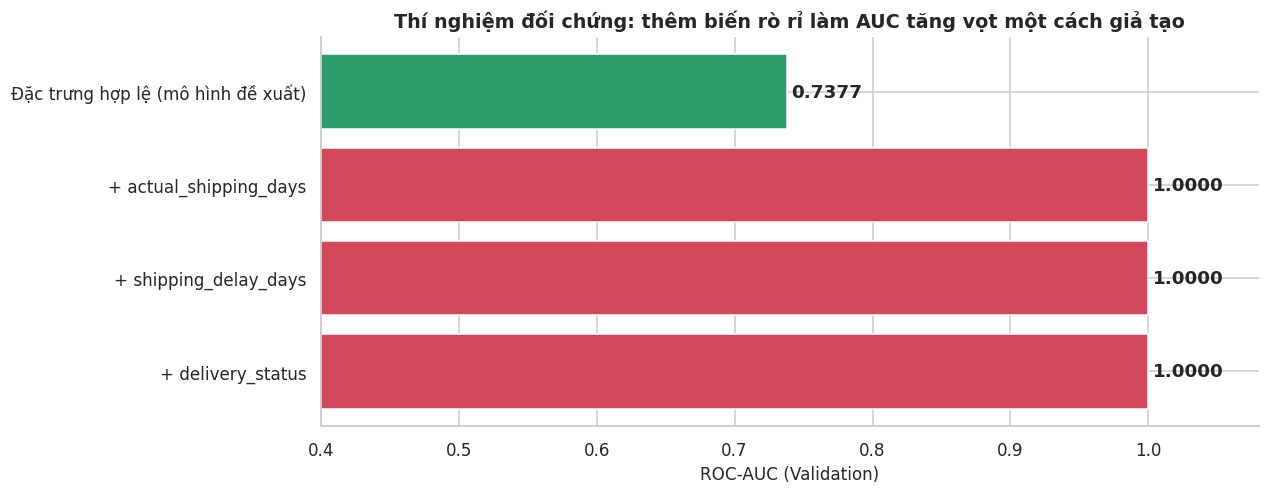

Hình 4.32. Thí nghiệm đối chứng: ROC-AUC trên Validation của XGBoost khi chỉ dùng đặc trưng hợp lệ (xanh) so với khi thêm từng biến rò rỉ (đỏ). AUC tiến sát 1,0 chứng tỏ các biến chỉ có sau khi giao hàng làm lộ đáp án, nên phải loại khỏi mô hình dự báo.
   → đã lưu: /content/drive/MyDrive/img_datawarehouse/32_thi_nghiem_ro_ri_du_lieu.png



In [ ]:
variants = {
    "Đặc trưng hợp lệ (mô hình đề xuất)": [],
    "+ actual_shipping_days":           ["actual_shipping_days"],
    "+ shipping_delay_days":            ["shipping_delay_days"],
    "+ delivery_status":                ["delivery_status"],
}
leak_auc = {}
for vname, extra in variants.items():
    ex_cat = [c for c in extra if c == "delivery_status"]
    ex_num = [c for c in extra if c != "delivery_status"]
    cats, nums = CAT_FEATURES + ex_cat, NUM_FEATURES + ex_num
    Xl = df_model[cats + nums].copy()
    p = Pipeline([("prep", make_preprocessor(cats, nums, False)),
                  ("clf", XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, tree_method="hist", eval_metric="logloss",
                                        n_jobs=-1, random_state=RANDOM_STATE))])
    p.fit(Xl.iloc[train_idx], y_all.iloc[train_idx])
    leak_auc[vname] = roc_auc_score(y_all.iloc[val_idx], p.predict_proba(Xl.iloc[val_idx])[:, 1])
    print(f"{vname:42s} AUC Validation = {leak_auc[vname]:.4f}")

fig, ax = plt.subplots(figsize=(11, 4.6))
names_l = list(leak_auc.keys()); vals_l = list(leak_auc.values())
bar_colors = [C_GREEN if i == 0 else C_RED for i in range(len(names_l))]
ax.barh(names_l[::-1], vals_l[::-1], color=bar_colors[::-1])
for i, v in enumerate(vals_l[::-1]): ax.text(v + 0.003, i, f"{v:.4f}", va="center", fontweight="bold")
ax.set_xlim(0.4, 1.08); ax.set_xlabel("ROC-AUC (Validation)")
ax.set_title("Thí nghiệm đối chứng: thêm biến rò rỉ làm AUC tăng vọt một cách giả tạo")
save_fig(fig, "thi_nghiem_ro_ri_du_lieu",
         "Thí nghiệm đối chứng: ROC-AUC trên Validation của XGBoost khi chỉ dùng đặc trưng hợp lệ (xanh) so với khi thêm từng biến rò rỉ (đỏ). "
         "AUC tiến sát 1,0 chứng tỏ các biến chỉ có sau khi giao hàng làm lộ đáp án, nên phải loại khỏi mô hình dự báo.")

---
# PHẦN 19. LƯU KẾT QUẢ VÀ LIÊN KẾT NGƯỢC VỀ KHO DỮ LIỆU

Lưu mô hình, ngưỡng, danh sách đặc trưng, phiên bản thư viện và hạt giống ngẫu nhiên để **tái lập** kết quả khi bảo vệ đồ án. Danh mục hình (`danh_muc_hinh.csv`) gồm số hình, tên file và chú thích tiếng Việt, đặt cùng thư mục với ảnh.

In [ ]:
# ---------- Lưu mô hình ----------
for n in MODEL_NAMES:
    joblib.dump(best_est[n], os.path.join(ART_DIR, f"model_{n.replace(' ', '_').lower()}.joblib"))
joblib.dump(best_est[best_final], os.path.join(ART_DIR, "model_tot_nhat.joblib"))

config_out = {
    "ngay_chay": time.strftime("%Y-%m-%d %H:%M:%S"), "random_state": RANDOM_STATE, "profile": PROFILE,
    "bang_nguon": WIDE_TABLE, "nhan": TARGET, "dac_trung_phan_loai": CAT_FEATURES, "dac_trung_so": NUM_FEATURES,
    "mo_hinh_duoc_chon": best_final, "nguong_toi_uu": thr_opt,
    "so_dong": {"train": int(len(X_train)), "validation": int(len(X_val)), "test": int(len(X_test))},
    "auc_test": {n: float(ci_tbl.loc[n, "AUC"]) for n in MODEL_NAMES},
    "phien_ban": {"python": platform.python_version(), "sklearn": sklearn.__version__, "xgboost": xgboost.__version__,
                  "pandas": pd.__version__, "numpy": np.__version__},
}
with open(os.path.join(ART_DIR, "cau_hinh_va_ket_qua.json"), "w", encoding="utf-8") as f:
    json.dump(config_out, f, ensure_ascii=False, indent=2, default=float)

# ---------- Danh mục hình ----------
fig_df = pd.DataFrame(FIG_LOG)
fig_df.to_csv(os.path.join(IMG_DIR, "danh_muc_hinh.csv"), index=False, encoding="utf-8-sig")
print(f"Đã lưu {len(fig_df)} hình vào: {IMG_DIR}")
display(fig_df[["so_hinh", "file"]])
print("\nThư mục kết quả:", ART_DIR)
for fn in sorted(os.listdir(ART_DIR)): print("  -", fn)

## Tùy chọn: ghi kết quả dự đoán ngược về tầng Gold của BigQuery

Đặt `WRITE_BACK_TO_BQ = True` ở Phần 1 để tạo bảng `gold.ml_late_delivery_predictions`. Khi đó, kết quả học máy trở thành **một phần của kho dữ liệu**, nối với bảng phẳng qua `order_item_id` để dashboard BI hiển thị rủi ro giao trễ theo từng đơn.

Yêu cầu: tài khoản có quyền *BigQuery Data Editor* trên dataset `gold`. Bảng được ghi đè (`WRITE_TRUNCATE`) mỗi lần chạy, nên chạy lại notebook không tạo bản sao.

In [ ]:
if WRITE_BACK_TO_BQ:
    scored = df_model[["order_item_id", "order_id"]].copy()
    split_label = np.empty(len(df_model), dtype=object)
    split_label[train_idx], split_label[val_idx], split_label[test_idx] = "train", "validation", "test"
    scored["tap_du_lieu"] = split_label
    scored["xac_suat_tre"] = best_est[best_final].predict_proba(X_all)[:, 1]
    scored["du_doan_tre"] = (scored["xac_suat_tre"] >= thr_opt[best_final]).astype(int)
    scored["mo_hinh"] = best_final
    scored["thoi_diem_cham_diem"] = pd.Timestamp.utcnow()
    dest = f"{PROJECT_ID}.gold.ml_late_delivery_predictions"
    job = client.load_table_from_dataframe(scored, dest, job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE"))
    job.result()
    print(f"✔ Đã ghi {client.get_table(dest).num_rows:,} dòng vào {dest}")
    print("Lưu ý: xác suất của các dòng thuộc tập train/validation là xác suất 'trong mẫu' (kém khách quan hơn tập test).")
else:
    print("WRITE_BACK_TO_BQ = False → bỏ qua bước ghi ngược về BigQuery.")

WRITE_BACK_TO_BQ = False → bỏ qua bước ghi ngược về BigQuery.


# PHẦN 20. XUẤT DỮ LIỆU CHO WEBSITE DATACO
Nếu phiên Colab đã có `best_est`, `best_final`, `X_all`, `X_train`, `X_test` và các tập chia, chỉ chạy cell bên dưới. 
Cell không fit model, không ghi BigQuery. Nó lưu pipeline tốt nhất, ngưỡng Validation, metrics Test, 
tên feature gốc/sau mã hóa, defaults Train, mẫu dự báo và CSV metadata vào ZIP trên Drive.
Nếu biến chưa tồn tại, cell sẽ báo tên biến thiếu. Không có kết quả model được tạo khi chỉ mở file notebook.


In [ ]:
"""Raw inputs for the DataCo pipeline in the project's train.ipynb."""
import math
from datetime import date

FIELD_DEFINITIONS = [
    {'name': 'shipping_mode', 'label': 'Phương thức vận chuyển', 'type': 'select', 'required': True},
    {'name': 'market', 'label': 'Thị trường', 'type': 'select'},
    {'name': 'order_region', 'label': 'Khu vực giao hàng', 'type': 'select'},
    {'name': 'order_country', 'label': 'Quốc gia giao hàng', 'type': 'select'},
    {'name': 'category_name', 'label': 'Danh mục sản phẩm', 'type': 'select'},
    {'name': 'department_name', 'label': 'Ngành hàng', 'type': 'select'},
    {'name': 'customer_segment', 'label': 'Phân khúc khách hàng', 'type': 'select'},
    {'name': 'payment_type', 'label': 'Phương thức thanh toán', 'type': 'select'},
    {'name': 'order_date', 'label': 'Ngày đặt hàng', 'type': 'date', 'required': True},
    {'name': 'order_item_quantity', 'label': 'Số lượng sản phẩm', 'type': 'number', 'required': True, 'integer': True, 'min': 1},
    {'name': 'order_item_discount_rate', 'label': 'Tỷ lệ giảm giá (0–1)', 'type': 'number', 'min': 0, 'max': 1},
    {'name': 'order_item_total', 'label': 'Giá trị dòng đơn sau giảm giá (USD)', 'type': 'number', 'required': True, 'min': 0},
    {'name': 'benefit_per_order', 'label': 'Lợi nhuận dự kiến của dòng đơn (USD)', 'type': 'number'},
    {'name': 'scheduled_shipping_days', 'label': 'Số ngày vận chuyển dự kiến', 'type': 'number', 'integer': True, 'min': 1},
]
FORBIDDEN = {'actual_delivery_days', 'actual_shipping_days', 'delay_days', 'delivery_status',
             'shipping_delay_days', 'shipping_date', 'order_status', 'is_shipping_canceled',
             'late_delivery_risk', 'is_late', 'delivered_customer_date',
             'order_delivered_customer_date', 'customer_id', 'product_card_id'}
REQUIRED = [field['name'] for field in FIELD_DEFINITIONS if field.get('required')]


def validate_input(data, config):
    if not isinstance(data, dict):
        raise ValueError('Dữ liệu một dòng phải là đối tượng JSON.')
    bad = FORBIDDEN.intersection(data)
    if bad:
        raise ValueError('Không được dùng biến rò rỉ/định danh: ' + ', '.join(sorted(bad)))
    fields = config.get('form_fields') or FIELD_DEFINITIONS
    unknown = set(data) - {f['name'] for f in fields} - {'order_id', 'order_item_id'}
    if unknown:
        raise ValueError('Trường không được hỗ trợ: ' + ', '.join(sorted(unknown)))
    result = {}
    for field in fields:
        name = field['name']
        value = data.get(name)
        if value is None or str(value).strip() == '':
            if field.get('required'):
                raise ValueError(f'{name}: bắt buộc nhập.')
            continue
        if field['type'] == 'date':
            try:
                result[name] = date.fromisoformat(str(value)).isoformat()
            except ValueError:
                raise ValueError(f'{name}: dùng định dạng YYYY-MM-DD.') from None
        elif field['type'] == 'select':
            value = str(value).strip()
            if len(value) > 150:
                raise ValueError(f'{name}: tối đa 150 ký tự.')
            if field.get('options') and value not in field['options']:
                raise ValueError(f'{name}: giá trị không nằm trong danh mục đã export từ Train.')
            result[name] = value
        else:
            try:
                number = float(value)
            except (ValueError, TypeError):
                raise ValueError(f'{name}: phải là số.') from None
            if not math.isfinite(number):
                raise ValueError(f'{name}: số phải hữu hạn.')
            if 'min' in field and number < field['min']:
                raise ValueError(f'{name}: phải ≥ {field["min"]}.')
            if 'max' in field and number > field['max']:
                raise ValueError(f'{name}: phải ≤ {field["max"]}.')
            if field.get('integer') and not number.is_integer():
                raise ValueError(f'{name}: phải là số nguyên.')
            result[name] = int(number) if field.get('integer') else number
    return result


"""Export existing DataCo notebook objects. Does not fit or resample."""
import json
import math
import platform
import shutil
from pathlib import Path
from importlib.metadata import version
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             precision_score, recall_score, f1_score, confusion_matrix)


def export_dataco_dashboard(ns, destination):
    required = ['best_est', 'best_final', 'thr_opt', 'X_train', 'X_test', 'y_test',
                'X_all', 'df_model', 'train_idx', 'val_idx', 'test_idx', 'FEATURES',
                'CAT_FEATURES', 'NUM_FEATURES', 'TARGET']
    missing = [key for key in required if key not in ns]
    if missing:
        raise ValueError('Chưa có kết quả notebook trong phiên này: ' + ', '.join(missing))
    root = Path(destination)
    model_dir, data_dir = root / 'backend/models', root / 'data'
    model_dir.mkdir(parents=True, exist_ok=True)
    data_dir.mkdir(parents=True, exist_ok=True)
    model = ns['best_est'][ns['best_final']]
    names = list(ns['X_train'].columns)
    if names != list(ns['FEATURES']) or names != list(getattr(model, 'feature_names_in_', names)):
        raise ValueError('Thứ tự feature không khớp pipeline notebook.')
    if FORBIDDEN.intersection(names) or {'order_id', 'order_item_id'} & set(names):
        raise ValueError('Bộ feature có biến cấm; dừng export.')
    if not {'log_order_item_total', 'order_month', 'order_dayofweek'} <= set(names):
        raise ValueError('Không khớp phép tạo feature của notebook DataCo hiện tại.')
    threshold = float(ns['thr_opt'][ns['best_final']])
    if not math.isfinite(threshold) or not 0 <= threshold <= 1:
        raise ValueError('Ngưỡng Validation không hợp lệ. Cần kiểm tra cell chọn Youden.')
    defaults = {}
    for name in names:
        series = ns['X_train'][name].dropna()
        if series.empty:
            raise ValueError(f'{name}: không có giá trị Train để tạo mặc định.')
        value = series.mode().iloc[0] if name in ns['CAT_FEATURES'] else series.median()
        defaults[name] = value.item() if isinstance(value, np.generic) else value
    fields = []
    for definition in FIELD_DEFINITIONS:
        field = dict(definition)
        name = field['name']
        if name == 'scheduled_shipping_days' and name not in names:
            continue
        if field['type'] == 'select':
            field['options'] = sorted(ns['X_train'][name].dropna().astype(str).unique().tolist())
            field['default'] = defaults[name]
        elif name == 'order_item_total':
            field['default'] = math.expm1(defaults['log_order_item_total'])
        elif name == 'order_date':
            field['default'] = None
        else:
            field['default'] = defaults[name]
            if field.get('integer'):
                field['default'] = int(field['default'])
        fields.append(field)
    positive = list(model.classes_).index(1)
    test_prob = np.asarray(model.predict_proba(ns['X_test']))[:, positive]
    truth = np.asarray(ns['y_test'], dtype=int)
    pred = (test_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(truth, pred, labels=[0, 1]).ravel()
    both = len(np.unique(truth)) == 2
    metrics = {'roc_auc': float(roc_auc_score(truth, test_prob)) if both else None,
               'pr_auc': float(average_precision_score(truth, test_prob)) if both else None,
               'accuracy': float(accuracy_score(truth, pred)),
               'precision': float(precision_score(truth, pred, zero_division=0)),
               'recall': float(recall_score(truth, pred, zero_division=0)),
               'f1': float(f1_score(truth, pred, zero_division=0))}
    source = ns['df_model'].reset_index(drop=True)
    scored = source[['order_item_id', 'order_id']].copy()
    split = np.full(len(source), '', dtype=object)
    for label, key in [('train','train_idx'),('validation','val_idx'),('test','test_idx')]:
        indices = np.asarray(ns[key], dtype=int)
        if (split[indices] != '').any():
            raise ValueError('Các tập dữ liệu bị chồng lặp chỉ số.')
        split[indices] = label
    if (split == '').any():
        raise ValueError('Có dòng chưa thuộc tập Train/Validation/Test.')
    scored['tap_du_lieu'] = split
    scored['xac_suat_tre'] = np.asarray(model.predict_proba(ns['X_all']))[:, positive]
    scored['du_doan_tre'] = (scored.xac_suat_tre >= threshold).astype(int)
    scored['mo_hinh'] = ns['best_final']
    scored['thoi_diem_cham_diem'] = pd.Timestamp.now(tz='UTC').isoformat()
    scored['is_late'] = source[ns['TARGET']].astype(int).to_numpy()
    for col in ['category_name','order_region','order_date']:
        scored[col] = source[col].to_numpy()
    test_source = source.iloc[ns['test_idx']].reset_index(drop=True)
    examples = {}
    for label, mask in [('late',test_prob >= threshold),('on_time',test_prob < threshold)]:
        hits = np.flatnonzero(mask)
        if not len(hits):
            continue
        row, raw = test_source.iloc[int(hits[0])], {}
        for field in fields:
            key = field['name']
            value = row[key]
            if pd.isna(value):
                continue
            if key == 'order_date':
                value = pd.Timestamp(value).date().isoformat()
            elif field['type'] == 'select':
                value = str(value)
                if value not in field['options']:
                    field['options'].append(value)
                    field['options'].sort()
            elif field.get('integer'):
                value = int(value)
            else:
                value = float(value)
            raw[key] = value
        examples[label] = raw
    importance, transformed, kind = [], [], None
    if hasattr(model, 'named_steps') and 'prep' in model.named_steps:
        transformed = list(model.named_steps['prep'].get_feature_names_out())
        classifier = model.named_steps['clf']
        weights, kind = getattr(classifier, 'feature_importances_', None), 'feature_importances_'
        if weights is None and hasattr(classifier, 'coef_'):
            weights, kind = np.abs(classifier.coef_[0]), 'abs(coef_)'
        if weights is not None and len(weights) == len(transformed):
            grouped = {}
            for encoded, value in zip(transformed, weights):
                body = encoded.split('__', 1)[-1]
                candidates = [key for key in names if body == key or body.startswith(key+'_')]
                key = max(candidates, key=len) if candidates else body
                grouped[key] = grouped.get(key, 0.) + float(value)
            total_weight = sum(grouped.values()) or 1.
            importance = sorted([{'feature':k,'importance':v/total_weight} for k,v in grouped.items()],
                                key=lambda item:item['importance'], reverse=True)
    config = {'dataset':'DataCo', 'model':ns['best_final'], 'threshold':threshold,
              'feature_count':len(names), 'encoded_feature_count':len(transformed) or None,
              'expected_rows':len(scored), 'source_table':ns.get('WIDE_TABLE'),
              'target':ns['TARGET'], 'metrics':metrics,
              'confusion_matrix':{'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)},
              'metrics_source':'Tập test DataCo; ngưỡng chọn từ Validation; model chọn theo AUC Validation',
              'feature_defaults':defaults, 'form_fields':fields,
              'feature_importance':importance, 'importance_method':kind,
              'demo_inputs':examples,
              'split_counts':{label:int((split==label).sum()) for label in ['train','validation','test']},
              'label_rate':float(scored.is_late.mean()),
              'versions':{key:version(key) for key in ['scikit-learn','xgboost','pandas','numpy','joblib']},
              'python':platform.python_version(),
              'notes':'CSV gồm Train/Validation/Test; điểm Train là in-sample. Pipeline nhận feature gốc và tự encode.'}
    months = pd.to_datetime(test_source.order_date).dt.strftime('%Y-%m')
    monitoring = []
    for month in sorted(months.dropna().unique()):
        mask = (months == month).to_numpy()
        if mask.sum() >= 30 and len(np.unique(truth[mask])) == 2:
            monitoring.append({'period':month,'auc':float(roc_auc_score(truth[mask],test_prob[mask])),
                               'n':int(mask.sum()),'source':'Tập test theo tháng đặt hàng; không phải đánh giá tương lai'})
    config['monitoring_auc'] = monitoring
    joblib.dump(model, model_dir / 'model_tot_nhat.joblib')
    for filename, content in [('model_config.json',config),('feature_names.json',names),
                              ('transformed_feature_names.json',transformed)]:
        (model_dir / filename).write_text(json.dumps(content,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
    scored.to_csv(data_dir / 'delivery_predictions.csv', index=False, encoding='utf-8-sig')
    bundle = shutil.make_archive(str(root.parent / 'dataco_dashboard_bundle'), 'zip', root)
    print(f'Đã xuất {len(names)} feature gốc, {len(scored):,} dòng dự đoán; model {ns["best_final"]}; ngưỡng {threshold:.6f}.')
    print('Bundle:', bundle)
    return bundle


# Cell này chỉ dùng kết quả/pipeline đã fit trong phiên; KHÔNG huấn luyện lại.
DASHBOARD_EXPORT_DIR = os.path.join(ART_DIR, "dataco_dashboard_export")
bundle_path = export_dataco_dashboard(globals(), DASHBOARD_EXPORT_DIR)
print("Tải ZIP, giải nén và chép backend/models + data vào thư mục dashboard trên máy.")
if IN_COLAB:
    from google.colab import files
    files.download(bundle_path)
